In [14]:
# ============================================================
# DataScience Vic — MASTER IMPORTS
# Core + EDA + Preprocess + Unsupervised + Supervised (Cls/Reg)
# - Ordenado, sin duplicados
# - Incluye HPO opcional + DL opcional
# ============================================================

from __future__ import annotations

# ============================================================
# (0) Standard library
# ============================================================
import os
import time
import json
import pickle
import warnings
import re
from dataclasses import dataclass
from typing import Any, Dict, List, Optional, Tuple, Union, Callable
import importlib.util
import sys


# ============================================================
# (1) Core scientific stack
# ============================================================
import numpy as np
import pandas as pd

# ============================================================
# (2) Parallelism / persistence
# ============================================================
import joblib
from joblib import Parallel, delayed

# ============================================================
# (3) Plotting and visualization
# ============================================================
import plotly.express as px
import plotly.graph_objects as go

import matplotlib

def _setup_matplotlib_backend_for_notebook():
    try:
        from IPython import get_ipython
        ip = get_ipython()
        if ip is None:
            return
        if "IPKernelApp" in ip.config:  # notebook/jupyter
            matplotlib.use("module://matplotlib_inline.backend_inline")
    except Exception:
        pass

_setup_matplotlib_backend_for_notebook()

import matplotlib.pyplot as plt

# ============================================================
# (4) Statistics / signals
# ============================================================
from scipy.stats import gaussian_kde
from scipy import signal

# ============================================================
# (5) Pandas dtype helpers
# ============================================================
from pandas.api.types import (
    is_bool_dtype,
    is_datetime64_any_dtype,
    is_numeric_dtype,
    is_object_dtype,
)

# ============================================================
# (6) Scikit-learn: base / pipelines / preprocessing
# ============================================================
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    LabelEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
)

# ============================================================
# (7) Scikit-learn: model selection / CV / search
# ============================================================
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
)

# Halving Search (optional)
try:
    from sklearn.experimental import enable_halving_search_cv  # noqa: F401
    from sklearn.model_selection import HalvingRandomSearchCV
    _HAS_HALVING = True
except Exception:
    _HAS_HALVING = False

# BayesSearch (optional)
try:
    from skopt import BayesSearchCV
    _HAS_SKOPT = True
except Exception:
    _HAS_SKOPT = False

# ============================================================
# (8) Scikit-learn: feature scoring / reduction / clustering
# ============================================================
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# (9) Scikit-learn: metrics
# ============================================================
from sklearn.metrics import (
    # Unsupervised
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    # Classification
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    log_loss,
    classification_report,
    # Regression
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    make_scorer,
)

# ============================================================
# (10) Supervised models — Classification
# ============================================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.discriminant_analysis import (
    QuadraticDiscriminantAnalysis,
    LinearDiscriminantAnalysis,
)
from sklearn.naive_bayes import GaussianNB

# XGBoost (optional)
try:
    from xgboost import XGBClassifier
    _HAS_XGB = True
except Exception:
    _HAS_XGB = False

try:
    import xgboost as xgb #xgboost para series de tiempo
    _HAS_XGB = True
except Exception:
    _HAS_XGB = False    

# ============================================================
# (11) Supervised models — Regression
# ============================================================
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# ============================================================
# (12) Deep Learning (optional): TensorFlow / Keras + Keras Tuner
# ============================================================
_HAS_TF = False
_HAS_KT = False

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import regularizers
    from tensorflow.keras import layers 
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Input, Dense, LSTM, Conv1D, GlobalAveragePooling1D
    _HAS_TF = True
except Exception:
    _HAS_TF = False

try:
    import keras_tuner as kt
    _HAS_KT = True
except Exception:
    _HAS_KT = False

# ============================================================
# (13) Time Series (statsmodels)
# (Opcional en master: si TODO vive en 1 solo archivo)
# ============================================================
from statsmodels.tsa.api import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
try:
    from prophet import Prophet
    _HAS_PROPHET = True
except Exception:
    _HAS_PROPHET = False

# ============================================================
# (13) Utilities (framework-level)
# ============================================================
def _ensure_dir(path: str) -> None:
    os.makedirs(path, exist_ok=True)

def _rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

# sklearn scoring: "higher is better" => usamos negativo para que minimice RMSE
RMSE_SCORER = make_scorer(
    lambda yt, yp: -_rmse(yt, yp),
    greater_is_better=True
)

# ============================================================
# (X) Optional: joblib for parallel SARIMA tuning
# ============================================================
try:
    from joblib import Parallel, delayed
    _HAS_JOBLIB = True
except Exception:
    _HAS_JOBLIB = False
    Parallel = None
    delayed = None

# ============================================================
# Clase DataScience Vic
# ============================================================

@dataclass
class ColumnGroups:
    numeric: List[str]
    categorical: List[str]
    datetime: List[str]
    boolean: List[str]
    other: List[str]

class DFCore:
    """
    Núcleo mínimo:
    - almacena df (copia)
    - detecta grupos de columnas
    - utilidades comunes para el resto de módulos
    """
    def __init__(self, df: pd.DataFrame, target: Optional[str] = None, features: Optional[List[str]] = None):
        if not isinstance(df, pd.DataFrame):
            raise TypeError("df debe ser un pandas.DataFrame")

        self.df = df.copy()
        self.target = target

        if features is None:
            self.features = [c for c in self.df.columns if c != target]
        else:
            # Validación básica
            missing = [c for c in features if c not in self.df.columns]
            if missing:
                raise ValueError(f"Estas columnas no existen en df: {missing}")
            self.features = features

        self.cols = self._infer_column_groups()

    def _infer_column_groups(self) -> ColumnGroups:
        df = self.df

        datetime_cols = [c for c in df.columns if is_datetime64_any_dtype(df[c])]
        bool_cols = [c for c in df.columns if is_bool_dtype(df[c])]

        numeric_cols = [c for c in df.columns if is_numeric_dtype(df[c]) and c not in datetime_cols and c not in bool_cols]
        cat_cols = cat_cols = [
                c for c in df.columns
                if (
                    is_object_dtype(df[c])
                    or isinstance(df[c].dtype, pd.CategoricalDtype)
                )
                and c not in datetime_cols
                and c not in bool_cols
                ]


        used = set(datetime_cols + bool_cols + numeric_cols + cat_cols)
        other_cols = [c for c in df.columns if c not in used]

        return ColumnGroups(
            numeric=numeric_cols,
            categorical=cat_cols,
            datetime=datetime_cols,
            boolean=bool_cols,
            other=other_cols
        )

    def objects_to_category(self, cols: Optional[List[str]] = None, exclude: Optional[List[str]] = None):
        """
        Convierte columnas object a category.
        Modifica self.df y actualiza grupos de columnas.
        """
        exclude = set(exclude or [])

        if cols is None:
            cols = self.df.select_dtypes(include=["object"]).columns.tolist()

        converted = []
        skipped = []

        for c in cols:
            if c not in self.df.columns:
                skipped.append(c)
                continue
            if c in exclude:
                skipped.append(c)
                continue

            if is_object_dtype(self.df[c]):
                self.df[c] = self.df[c].astype("category")
                converted.append(c)
            else:
                skipped.append(c)

        self.cols = self._infer_column_groups()
        print(f"Columnas convertidas a category: {converted}")

        return {"converted": converted, "skipped": skipped}

    def cast_datetime(self, cols: List[str], errors: str = "coerce", format: Optional[str] = None, dayfirst: bool = False):
        """
        Convierte columnas a datetime.
        """
        missing = [c for c in cols if c not in self.df.columns]
        if missing:
            raise ValueError(f"Estas columnas no existen en df: {missing}")

        for c in cols:
            self.df[c] = pd.to_datetime(self.df[c], errors=errors, format=format, dayfirst=dayfirst)

        self.cols = self._infer_column_groups()

    def _in_notebook(self) -> bool:
        """Detecta si estamos en un entorno tipo Jupyter."""
        try:
            from IPython import get_ipython
            ip = get_ipython()
            if ip is None:
                return False
            # kernel típico de notebook/lab
            return "IPKernelApp" in ip.config
        except Exception:
            return False

    def _display_df(
        self,
        df: pd.DataFrame,
        title: Optional[str] = None,
        head: Optional[int] = None,
        precision: int = 4,
        max_colwidth: int = 60
    ):
        """
        Muestra un DataFrame de forma bonita en Jupyter (Styler),
        con fallback a print en consola.

        - title: imprime encabezado
        - head: si se pasa, muestra solo top N filas
        """
        if df is None:
            return

        if not isinstance(df, pd.DataFrame):
            # fallback simple
            if title:
                print(title)
            print(df)
            return

        view = df.head(head) if head is not None else df

        if title:
            print(title)

        # --- Notebook: usar Styler ---
        if self._in_notebook():
            try:
                from IPython.display import display
                sty = (
                    view.style
                        .format(precision=precision)
                        .set_properties(**{"text-align": "left"})
                        .set_table_styles([
                            {"selector": "th", "props": [("text-align", "left")]},
                        ])
                )
                # Nota: max_colwidth depende de pandas version; si falla, lo ignoramos
                try:
                    pd.set_option("display.max_colwidth", max_colwidth)
                except Exception:
                    pass

                display(sty)
                return
            except Exception:
                # si algo falla, caemos al print
                pass

        # --- Consola: print friendly ---
        with pd.option_context(
            "display.max_rows", 200,
            "display.max_columns", 200,
            "display.width", 120,
            "display.max_colwidth", max_colwidth
        ):
            print(view)    

    def _style_strength(self, val: Any) -> str:
        if val is None or (isinstance(val, float) and np.isnan(val)):
            return ""

        v = str(val)

        styles = {
            "Strong":     "background-color: #d9f2d9; color: black; font-weight: 600;",
            "Moderate":   "background-color: #fff2cc; color: black; font-weight: 600;",
            "Weak":       "background-color: #ffe0cc; color: black; font-weight: 600;",
            "Negligible": "background-color: #eeeeee; color: black;",
            "Unknown":    "background-color: #e6e0f8; color: black;"
        }

        return styles.get(v, "")

    @staticmethod
    def _style_status(val: Any) -> str:
        """
        Colorea status tipo dependency doctor.
        - OK: verde con letras negras (bold)
        - MISSING: rojo con letras blancas (bold)
        - MISSING_FLAG: naranja con letras negras (bold)
        - WARN: amarillo con letras negras (bold) (opcional)
        """
        if val is None or (isinstance(val, float) and np.isnan(val)):
            return ""

        v = str(val).strip().upper()

        styles = {
            "OK":           "background-color: #b7e1cd; color: black; font-weight: 700;",
            "MISSING":      "background-color: #c00000; color: white; font-weight: 700;",
            "MISSING_FLAG": "background-color: #ff8c00; color: black; font-weight: 700;",
            "WARN":         "background-color: #ffd966; color: black; font-weight: 700;",
        }
        return styles.get(v, "")
    
    @staticmethod
    def pretty_table_static(
        df: pd.DataFrame,
        title: Optional[str] = None,
        head: Optional[int] = None,
        precision: int = 4,
        max_colwidth: int = 60,
        style_funcs: Optional[Dict[str, Any]] = None,  # {"col": func(val)->css}
    ):
        """
        Render bonito SIN necesitar instancia DFCore.
        style_funcs: dict columna -> función estilo (CSS string)
        """
        if df is None:
            return None

        # fallback si no es DataFrame
        if not isinstance(df, pd.DataFrame):
            if title:
                print(title)
            print(df)
            return None

        view = df.head(head) if head is not None else df

        if title:
            print(title)

        # ¿Notebook?
        try:
            from IPython import get_ipython
            ip = get_ipython()
            in_nb = (ip is not None) and ("IPKernelApp" in ip.config)
        except Exception:
            in_nb = False

        if in_nb:
            try:
                from IPython.display import display
                sty = (
                    view.style
                        .format(precision=precision)
                        .set_properties(**{"text-align": "left"})
                        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
                )

                if style_funcs:
                    for col, fn in style_funcs.items():
                        if col in view.columns and callable(fn):
                            sty = sty.map(fn, subset=[col])

                try:
                    pd.set_option("display.max_colwidth", max_colwidth)
                except Exception:
                    pass

                display(sty)
                return sty
            except Exception:
                pass

        # consola fallback
        with pd.option_context(
            "display.max_rows", 200,
            "display.max_columns", 200,
            "display.width", 120,
            "display.max_colwidth", max_colwidth
        ):
            print(view)
        return None

    def _has_pkg(pkg_name: str) -> bool:
        """True si el paquete es importable (sin importarlo)."""
        try:
            return importlib.util.find_spec(pkg_name) is not None
        except Exception:
            return False

    @classmethod
    def dependency_doctor(cls, verbose: bool = True, return_df: bool = False):
        """
        Revisa dependencias por capabilities del framework y reporta faltantes.
        - No revienta si faltan; solo reporta.
        - Usa find_spec (ligero) + banderas _HAS_* cuando existan.
        """

        def _has_pkg(pkg: str) -> bool:
            try:
                return importlib.util.find_spec(pkg) is not None
            except Exception:
                return False

        checks = {
            "core": ["numpy", "pandas"],
            "viz": ["plotly", "matplotlib"],
            "sklearn_core": ["sklearn"],
            "hpo_halving": ["sklearn"],
            "hpo_bayes_skopt": ["skopt"],
            "xgboost": ["xgboost"],
            "deeplearning_tf": ["tensorflow"],
            "deeplearning_kt": ["keras_tuner"],
            "timeseries_statsmodels": ["statsmodels"],
            "timeseries_prophet": ["prophet"],
        }

        rows = []
        for cap, pkgs in checks.items():
            missing = [p for p in pkgs if not _has_pkg(p)]
            rows.append({
                "capability": cap,
                "status": "OK" if not missing else "MISSING",
                "missing": ", ".join(missing) if missing else ""
            })

        df = pd.DataFrame(rows)

        # banderas internas (si existen)
        flag_map = {
            "_HAS_HALVING": "hpo_halving",
            "_HAS_SKOPT": "hpo_bayes_skopt",
            "_HAS_XGB": "xgboost",
            "_HAS_TF": "deeplearning_tf",
            "_HAS_KT": "deeplearning_kt",
            "_HAS_PROPHET": "timeseries_prophet",
        }
        g = globals()
        for flag, cap in flag_map.items():
            if flag in g and (not bool(g[flag])):
                df.loc[df["capability"] == cap, "status"] = "MISSING_FLAG"
                cur = df.loc[df["capability"] == cap, "missing"].iloc[0]
                if cur == "":
                    df.loc[df["capability"] == cap, "missing"] = f"(flag {flag}=False)"

        # ordenar (faltantes arriba)
        order_map = {"MISSING": 0, "MISSING_FLAG": 1, "OK": 2}
        df["_ord"] = df["status"].map(order_map).fillna(9).astype(int)
        df = (
            df[["capability", "status", "missing", "_ord"]]
            .sort_values(["_ord", "capability"])
            .drop(columns=["_ord"])
            .reset_index(drop=True)
        )

        if verbose:
            missing_df = df[df["status"] != "OK"]

            if missing_df.empty:
                print("✅ Dependency doctor: todo OK (para los módulos chequeados).")
                cls.pretty_table_static(
                    df,
                    title="Dependency doctor (OK)",
                    precision=4,
                    max_colwidth=80,
                    style_funcs={"status": lambda v: cls(pd.DataFrame({"_":[0]}))._style_status(v)}  # ver nota abajo
                )
            else:
                print("⚠️ Dependency doctor: faltantes detectados:")
                cls.pretty_table_static(
                    missing_df,
                    title="Dependency doctor (FALTANTES)",
                    precision=4,
                    max_colwidth=80,
                    style_funcs={"status": lambda v: cls(pd.DataFrame({"_":[0]}))._style_status(v)}  # ver nota abajo
                )

                pkgs_missing = sorted({
                    x.strip()
                    for m in missing_df["missing"].tolist()
                    for x in m.split(",")
                    if x.strip() and not x.strip().startswith("(")
                })
                if pkgs_missing:
                    print("\nSugerencia (pip):")
                    print("pip install " + " ".join(pkgs_missing))

        return df if return_df else None

    def pretty_table(
        self,
        df: pd.DataFrame,
        title: Optional[str] = None,
        head: Optional[int] = None,
        precision: int = 4,
        highlight_strength_col: Optional[str] = "strength",
        highlight_status_col: Optional[str] = None,
        max_colwidth: int = 60
    ):
        """
        API principal (NO romper código viejo).
        Internamente delega a pretty_table_static.
        """

        # construir style_funcs según columnas
        style_funcs = {}

        # strength
        if highlight_strength_col is not None and isinstance(df, pd.DataFrame) and highlight_strength_col in df.columns:
            style_funcs[highlight_strength_col] = DFCore._style_strength

        # status
        status_col = highlight_status_col
        if status_col is None and isinstance(df, pd.DataFrame) and "status" in df.columns:
            status_col = "status"
        if status_col is not None and isinstance(df, pd.DataFrame) and status_col in df.columns:
            style_funcs[status_col] = DFCore._style_status

        return DFCore.pretty_table_static(
            df=df,
            title=title,
            head=head,
            precision=precision,
            max_colwidth=max_colwidth,
            style_funcs=style_funcs if style_funcs else None
        )

# ============================================================
# EDA Rápida + Target Analysis + Imbalance Report + Predictive Power
# ============================================================

class EDAQuick(DFCore):
    """
    EDA rápido: shape, missing, duplicates, cardinalidad, describe numérico,
    correlación y outliers (plotly).
    """

    def summary(self) -> pd.DataFrame:
        df = self.df
        out = pd.DataFrame({
            "dtype": df.dtypes.astype(str),
            "n_null": df.isna().sum(),
            "pct_null": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(dropna=True),
        })
        out["pct_unique"] = (out["n_unique"] / len(df) * 100).round(2)
        return out.sort_values(["pct_null", "pct_unique"], ascending=False)

    def dataset_info(self) -> Dict[str, Any]:
        df = self.df
        return {
            "rows": df.shape[0],
            "cols": df.shape[1],
            "memory_mb": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
            "duplicates_rows": int(df.duplicated().sum()),
            "target": self.target,
            "n_numeric": len(self.cols.numeric),
            "n_categorical": len(self.cols.categorical),
            "n_datetime": len(self.cols.datetime),
            "n_boolean": len(self.cols.boolean),
            "n_other": len(self.cols.other),
        }

    def describe_numeric(self) -> pd.DataFrame:
        if len(self.cols.numeric) == 0:
            return pd.DataFrame()
        return self.df[self.cols.numeric].describe().T

    def correlation_plot(self, method: str = "pearson"):
        """
        Heatmap de correlación para numéricas (Plotly).
        """
        if len(self.cols.numeric) < 2:
            print("Se requieren al menos 2 columnas numéricas para correlación.")
            return None

        corr = self.df[self.cols.numeric].corr(method=method)
        fig = px.imshow(
            corr,
            text_auto=True,
            aspect="auto",
            title=f"Correlación ({method}) — variables numéricas"
        )
        fig.show()
        return corr

    def outliers_boxplot(self, cols: Optional[List[str]] = None, points: str = "outliers"):
        """
        Boxplot interactivo Plotly.
        points: 'outliers' | 'all' | False
        """
        if cols is None:
            cols = self.cols.numeric

        if len(cols) == 0:
            print("No hay columnas numéricas para boxplot.")
            return

        df_melt = self.df[cols].melt(var_name="variable", value_name="value")
        fig = px.box(df_melt, x="variable", y="value", points=points, title="Outliers — Boxplot (Plotly)")
        fig.show()

    def _imbalance_severity(self, ratio: float) -> str:
        # Regla práctica (ajustable después)
        if ratio < 1.5:
            return "Balanced"
        elif ratio < 3:
            return "Mild imbalance"
        elif ratio < 10:
            return "Moderate imbalance"
        else:
            return "Severe imbalance"

    def _compute_imbalance_info(self):
        """
        Calcula imbalance del target SIN imprimir nada.
        Retorna dict o None si no aplica.
        """
        if self.target is None:
            return None

        s = self.df[self.target]

        is_cat = (
            is_object_dtype(s)
            or isinstance(s.dtype, pd.CategoricalDtype)
            or is_bool_dtype(s)
        )
        if not is_cat:
            return None

        counts = s.value_counts(dropna=False)
        if len(counts) <= 1:
            return {"counts": counts, "ratio": 1.0, "severity": "Balanced", "recommendations": []}

        ratio = float(counts.max() / counts.min())
        severity = self._imbalance_severity(ratio)
        recs = self._imbalance_recommendations(ratio)

        return {
            "counts": counts,
            "ratio": ratio,
            "severity": severity,
            "recommendations": recs
        }

    def _imbalance_recommendations(self, ratio: float) -> List[str]:
        # Recomendaciones típicas para clasificación
        recs = []
        if ratio >= 1.5:
            recs.append("Prefer F1-macro / balanced accuracy over plain accuracy.")
            recs.append("Use stratified split / stratified CV.")
        if ratio >= 3:
            recs.append("Consider class_weight='balanced' (where applicable).")
            recs.append("Consider resampling (RandomOverSampler / SMOTE) for training only.")
        if ratio >= 10:
            recs.append("Review data collection; extremely imbalanced targets can be unstable.")
        return recs
    
    def target_distribution(self):
        """
        Distribución del target si existe.

        - Si es categórico:
            Barra horizontal única segmentada (%)
        - Si es numérico:
            Histograma
        """

        if self.target is None:
            print("No definiste target.")
            return

        s = self.df[self.target]

        # ---------------------------------------------------------
        # TARGET CATEGÓRICO
        # ---------------------------------------------------------
        if (
            is_object_dtype(s)
            or isinstance(s.dtype, pd.CategoricalDtype)
            or is_bool_dtype(s)
        ):

            tab = s.value_counts(dropna=False)
            pct = (tab / tab.sum() * 100).round(2)

            out = pd.DataFrame({
                "category": tab.index.astype(str),
                "count": tab.values,
                "pct": pct.values
            })

            # -------------------------------------------------
            # CALCULO DEL IMBALANCE (SOLO CATEGORICO)
            # -------------------------------------------------

            imb = self._compute_imbalance_info()

            if imb is not None and len(tab) > 1:
                title_text = (
                    f"Distribución target: {self.target} | "
                    f"{imb['severity']} ({imb['ratio']:.2f}:1)"
                )
            else:
                title_text = f"Distribución target: {self.target}"


            fig = go.Figure()

            for _, row in out.iterrows():
                fig.add_bar(
                    x=[row["pct"]],
                    y=[""],
                    orientation="h",
                    name=row["category"],
                    text=f'{row["pct"]:.1f}%<br>({row["count"]})',
                    textposition="inside",
                )

            fig.update_layout(
                barmode="stack",
                title=title_text,
                xaxis_title="Porcentaje (%)",
                yaxis_title="",
                showlegend=True,
                height=250
            )

            fig.update_xaxes(range=[0, 100])
            fig.show()

            return out.set_index("category")


        # ---------------------------------------------------------
        # TARGET NUMÉRICO
        # ---------------------------------------------------------
        else:
            fig = px.histogram(
                self.df,
                x=self.target,
                nbins=30,
                title=f"Distribución target: {self.target}"
            )
            fig.show()

            return s.describe()
        
    def imbalance_report(self) -> Optional[pd.DataFrame]:
        if self.target is None:
            print("No definiste target.")
            return None

        imb = self._compute_imbalance_info()
        if imb is None:
            print("El target no es categórico (o no aplica imbalance).")
            return None

        counts = imb["counts"]
        pct = (counts / counts.sum() * 100).round(2)
        report = pd.DataFrame({"count": counts, "pct": pct})

        if len(counts) > 1:
            majority_class = counts.idxmax()
            minority_class = counts.idxmin()

            print("========== IMBALANCE REPORT ==========")
            print(f"Majority class : {majority_class}")
            print(f"Minority class : {minority_class}")
            print(f"Imbalance ratio: {imb['ratio']:.2f} : 1")
            print(f"Severity       : {imb['severity']}")
            if imb["recommendations"]:
                print("Recommendations:")
                for r in imb["recommendations"]:
                    print(f" - {r}")

            report["severity"] = imb["severity"]
            report["imbalance_ratio"] = round(imb["ratio"], 4)
        else:
            print("========== IMBALANCE REPORT ==========")
            print("Solo hay una clase en el target; no se puede calcular imbalance.")
            report["severity"] = "Balanced"
            report["imbalance_ratio"] = 1.0

        return report

    def predictive_power_categorical(
        self,
        var: str,
        normalize: str = "index",   # "index" => % por fila (cada categoría suma 100%)
        min_count: int = 10,
        sort_by: str = "count",     # "count" | "alpha"
        show: bool = True
    ) -> pd.DataFrame:
        """
        Poder predictivo para variable categórica vs target.
        - Crea tabla de contingencia y la normaliza por fila (%)
        - Grafica stacked horizontal en Plotly
        - Devuelve el DataFrame (porcentajes) + conteos

        min_count: agrupa categorías raras en '__OTHER__' si su count < min_count
        """

        if self.target is None:
            raise ValueError("No definiste target.")

        if var not in self.df.columns:
            raise ValueError(f"'{var}' no existe en el DataFrame.")

        df = self.df[[var, self.target]].copy()

        # Manejo de NaN como categoría explícita
        df[var] = df[var].astype("object").fillna("__NA__")
        df[self.target] = df[self.target].astype("object").fillna("__NA__")

        # Agrupar categorías raras
        vc = df[var].value_counts(dropna=False)
        rare = vc[vc < min_count].index
        if len(rare) > 0:
            df[var] = df[var].where(~df[var].isin(rare), "__OTHER__")

        # Conteos
        ct_counts = pd.crosstab(df[var], df[self.target], dropna=False)

        # Porcentajes por fila (cada categoría suma 1.0)
        if normalize == "index":
            ct_pct = ct_counts.div(ct_counts.sum(axis=1), axis=0)
        elif normalize == "all":
            ct_pct = ct_counts / ct_counts.values.sum()
        else:
            raise ValueError("normalize debe ser 'index' o 'all'.")

        # Orden
        if sort_by == "count":
            order = ct_counts.sum(axis=1).sort_values(ascending=False).index
        elif sort_by == "alpha":
            order = sorted(ct_counts.index, key=lambda x: str(x))
        else:
            raise ValueError("sort_by debe ser 'count' o 'alpha'.")

        ct_counts = ct_counts.loc[order]
        ct_pct = ct_pct.loc[order]

        # DataFrame de salida (pct + count_total)
        out = (ct_pct * 100).round(2)
        out["count_total"] = ct_counts.sum(axis=1)
        out = out.rename_axis(var).reset_index()

        # Plot
        if show:
            # a formato largo para plotly
            long_df = ct_pct.reset_index().melt(
                id_vars=[var],
                var_name="target_class",
                value_name="pct"
            )
            long_df["pct"] = (long_df["pct"] * 100)

            fig = px.bar(
                long_df,
                y=var,
                x="pct",
                color="target_class",
                orientation="h",
                text=long_df["pct"].map(lambda x: f"{x:.1f}%"),
                title=f"Poder predictivo (categórica): {var} vs {self.target}",
            )
            fig.update_layout(barmode="stack", xaxis_title="Porcentaje (%)", yaxis_title=var)
            fig.update_xaxes(range=[0, 100])
            fig.show()

        return out

    def predictive_power_numeric(
        self,
        var: str,
        show: bool = True,
        grid_size: int = 256,
        clip_quantiles: tuple = (0.01, 0.99),
        bw_method=None,            # None usa default; podés poner "scott" o "silverman"
        fill_opacity: float = 0.35
    ) -> pd.DataFrame:
        """
        Poder predictivo numérico vs target con KDE (estilo seaborn fill=True) usando Plotly.

        Devuelve describe() por clase.
        """

        if self.target is None:
            raise ValueError("No definiste target.")
        if var not in self.df.columns:
            raise ValueError(f"'{var}' no existe en el DataFrame.")
        if not pd.api.types.is_numeric_dtype(self.df[var]):
            raise TypeError(f"'{var}' no es numérica. dtype={self.df[var].dtype}")

        df = self.df[[var, self.target]].dropna(subset=[var, self.target]).copy()

        # Stats (silencia warning observed)
        stats = df.groupby(self.target, observed=True)[var].describe()

        if not show:
            return stats

        # Rango robusto para evitar colas locas
        lo, hi = df[var].quantile(list(clip_quantiles)).values
        if lo == hi:
            lo, hi = df[var].min(), df[var].max()
            if lo == hi:
                # variable constante
                fig = go.Figure()
                fig.add_annotation(text=f"{var} es constante; no se puede estimar KDE.", showarrow=False)
                fig.update_layout(title=f"KDE: {var} por clase de {self.target}")
                fig.show()
                return stats

        xgrid = np.linspace(lo, hi, grid_size)

        fig = go.Figure()

        # Graficar KDE por clase
        for cls, sub in df.groupby(self.target, observed=True):
            x = sub[var].astype(float).values

            if len(x) < 2 or np.std(x) == 0:
                # muy pocos datos o varianza 0 → no KDE confiable
                continue

            kde = gaussian_kde(x, bw_method=bw_method)
            y = kde(xgrid)

            # línea
            fig.add_trace(go.Scatter(
                x=xgrid,
                y=y,
                mode="lines",
                name=str(cls),
            ))
            # relleno (duplicamos con fill tozeroy)
            fig.add_trace(go.Scatter(
                x=xgrid,
                y=y,
                mode="lines",
                name=str(cls),
                fill="tozeroy",
                opacity=fill_opacity,
                showlegend=False,
                hoverinfo="skip"
            ))

        fig.update_layout(
            title=f"Densidad (KDE): {var} por clase de {self.target}",
            xaxis_title=var,
            yaxis_title="Densidad",
            height=400
        )
        fig.show()

        return stats

    def predictive_power_all(
        self,
        categorical_vars: Optional[List[str]] = None,
        numeric_vars: Optional[List[str]] = None,
        exclude: Optional[List[str]] = None,
        max_categorical: int = 12,
        max_numeric: int = 8,
        min_count_cat: int = 10,
        sort_by_cat: str = "count",   # "count" | "alpha"
        show_plots: bool = True,
        points_numeric: str = "outliers",
    ) -> Dict[str, Any]:
        """
        Ejecuta poder predictivo para múltiples variables:
        - Categóricas: stacked horizontal (% target por categoría)
        - Numéricas: violin por clase

        Devuelve:
        {
            "categorical": {var: df_out, ...},
            "numeric": {var: stats_df, ...},
            "skipped": {"categorical": [...], "numeric": [...]}
        }
        """

        if self.target is None:
            raise ValueError("No definiste target.")

        exclude = set(exclude or [])
        exclude.add(self.target)

        # Si el usuario no pasa lista, usamos lo detectado por DFCore
        if categorical_vars is None:
            categorical_vars = [c for c in self.cols.categorical if c not in exclude]
        else:
            categorical_vars = [c for c in categorical_vars if c not in exclude]

        if numeric_vars is None:
            numeric_vars = [c for c in self.cols.numeric if c not in exclude]
        else:
            numeric_vars = [c for c in numeric_vars if c not in exclude]

        # Limitar para evitar explotar el notebook
        categorical_vars = categorical_vars[:max_categorical]
        numeric_vars = numeric_vars[:max_numeric]

        results = {
            "categorical": {},
            "numeric": {},
            "skipped": {"categorical": [], "numeric": []}
        }

        # ---------- Categóricas ----------
        for var in categorical_vars:
            try:
                out = self.predictive_power_categorical(
                    var=var,
                    min_count=min_count_cat,
                    sort_by=sort_by_cat,
                    show=show_plots
                )
                results["categorical"][var] = out
            except Exception as e:
                results["skipped"]["categorical"].append((var, str(e)))

        # ---------- Numéricas ----------
        for var in numeric_vars:
            try:
                stats = self.predictive_power_numeric(
                    var=var,
                    show=show_plots
                )
                results["numeric"][var] = stats
            except Exception as e:
                results["skipped"]["numeric"].append((var, str(e)))

        return results
        
    def run_eda(
        self,
        do_objects_to_category: bool = True,
        show_summary: bool = True,
        show_target: bool = True,
        show_imbalance: bool = True,
        show_corr: bool = True,
        show_outliers: bool = True,
        corr_method: str = "pearson",
        outlier_points: str = "outliers",
        summary_head: int = 30,

        # --- NUEVO: Poder predictivo ---
        show_predictive_power: bool = False,
        use_power_all: bool = True,
        max_categorical: int = 12,
        max_numeric: int = 8,
        min_count_cat: int = 10,
        sort_by_cat: str = "count",
        points_numeric: str = "outliers",
        show_power_plots: bool = True,
    ) -> Dict[str, Any]:
        """
        Ejecuta un flujo completo de EDAQuick para ahorrar tiempo.

        Devuelve un dict con objetos/tablas útiles:
        - dataset_info (dict)
        - summary (DataFrame)
        - describe_numeric (DataFrame)
        - target_distribution (DataFrame/Series según caso)
        - imbalance_report (DataFrame)
        - correlation (DataFrame)
        - predictive_power (dict) [opcional]
        """

        results: Dict[str, Any] = {}

        # 0) Conversión opcional object -> category
        if do_objects_to_category:
            self.objects_to_category()

        # 1) Info general
        info = self.dataset_info()
        results["dataset_info"] = info
        print("========== DATASET INFO ==========")
        for k, v in info.items():
            print(f"{k}: {v}")

        # 2) Summary tabla
        if show_summary:
            print("\n========== SUMMARY (top) ==========")
            summ = self.summary()
            results["summary"] = summ
            try:
                from IPython.display import display
                display(summ.head(summary_head))
            except Exception:
                print(summ.head(summary_head))

        # 3) Describe numérico
        desc = self.describe_numeric()
        results["describe_numeric"] = desc
        if not desc.empty:
            print("\n========== DESCRIBE (numeric) ==========")
            try:
                from IPython.display import display
                display(desc)
            except Exception:
                print(desc)

        # 4) Target distribution + imbalance
        if self.target is not None and show_target:
            print("\n========== TARGET DISTRIBUTION ==========")
            results["target_distribution"] = self.target_distribution()

            if show_imbalance:
                # OJO: No imprimimos header aquí para evitar duplicados.
                results["imbalance_report"] = self.imbalance_report()

        # 5) Correlación
        if show_corr:
            print("\n========== CORRELATION ==========")
            results["correlation"] = self.correlation_plot(method=corr_method)

        # 6) Outliers boxplot
        if show_outliers:
            print("\n========== OUTLIERS (boxplot) ==========")
            self.outliers_boxplot(points=outlier_points)

        # 7) Poder predictivo
        if show_predictive_power and self.target is not None:
            print("\n========== PREDICTIVE POWER ==========")

            if use_power_all:
                results["predictive_power"] = self.predictive_power_all(
                    max_categorical=max_categorical,
                    max_numeric=max_numeric,
                    min_count_cat=min_count_cat,
                    sort_by_cat=sort_by_cat,
                    points_numeric=points_numeric,
                    show_plots=show_power_plots,
                )
            else:
                # Si no querés "all", igual devolvemos estructura vacía para consistencia
                results["predictive_power"] = {"categorical": {}, "numeric": {}, "skipped": {}}
                print("use_power_all=False: corre los métodos individuales manualmente.")

        return results

class EDAAdvanced(EDAQuick):
    """
    EDA avanzado orientado a "separabilidad" / poder predictivo.
    Diseñado para target categórico (clasificación).
    """

    # ----------------------------
    # Helpers
    # ----------------------------
    def _is_target_categorical(self) -> bool:
        if self.target is None:
            return False
        s = self.df[self.target]
        return (
            is_object_dtype(s)
            or isinstance(s.dtype, pd.CategoricalDtype)
            or is_bool_dtype(s)
        )

    def _require_target(self):
        if self.target is None:
            raise ValueError("No definiste target.")

    def _require_target_categorical(self):
        self._require_target()
        if not self._is_target_categorical():
            raise TypeError("EDAAdvanced (por ahora) requiere target categórico (clasificación).")

    def _cramers_v(self, confusion: pd.DataFrame) -> float:
        obs = confusion.values
        n = obs.sum()
        if n == 0:
            return np.nan

        row_sum = obs.sum(axis=1, keepdims=True)
        col_sum = obs.sum(axis=0, keepdims=True)
        expected = row_sum @ col_sum / n
        expected = np.where(expected == 0, 1e-12, expected)

        chi2_stat = ((obs - expected) ** 2 / expected).sum()

        r, k = obs.shape
        denom = n * (min(k - 1, r - 1))
        if denom == 0:
            return np.nan

        return float(np.sqrt(chi2_stat / denom))

    # ----------------------------
    # 1) Ranking numéricas vs target
    # ----------------------------
    def rank_numeric_features(
        self,
        features: Optional[List[str]] = None,
        top_n: int = 20,
        random_state: Optional[int] = None,
        verbose: bool = True
    ) -> pd.DataFrame:

        self._require_target_categorical()

        if features is None:
            features = self.cols.numeric.copy()

        features = [c for c in features if c in self.df.columns and is_numeric_dtype(self.df[c])]
        if len(features) == 0:
            return pd.DataFrame()

        X = self.df[features].copy()
        y = self.df[self.target].astype(str).values

        X = X.fillna(X.median(numeric_only=True))

        F, p = f_classif(X.values, y)
        mi = mutual_info_classif(X.values, y, random_state=random_state)

        out = pd.DataFrame({
            "feature": features,
            "anova_F": F,
            "anova_p": p,
            "mutual_info": mi,
        }).sort_values(["mutual_info", "anova_F"], ascending=False)

        # --------- NUEVO: score interpretable 0-1 + strength ----------
        mi_min = float(out["mutual_info"].min())
        mi_max = float(out["mutual_info"].max())
        out["mi_score"] = (out["mutual_info"] - mi_min) / (mi_max - mi_min + 1e-12)

        def _interpret_strength(score: float) -> str:
            if score >= 0.8:
                return "Strong"
            elif score >= 0.5:
                return "Moderate"
            elif score >= 0.2:
                return "Weak"
            else:
                return "Negligible"

        out["strength"] = out["mi_score"].apply(_interpret_strength)

        # (opcional) reordenar columnas para lectura
        out = out[["feature", "strength", "mi_score", "mutual_info", "anova_F", "anova_p"]]

        if verbose:
            self.pretty_table(
                out,
                title="========== NUMERIC FEATURE RANKING (interpretable) ==========",
                head=top_n,
                precision=4
            )

        return out


    # ----------------------------
    # 2) Ranking categóricas vs target
    # ----------------------------
    def rank_categorical_features(
        self,
        features: Optional[List[str]] = None,
        top_n: int = 20,
        min_count: int = 10,
        verbose: bool = True
    ) -> pd.DataFrame:

        self._require_target_categorical()

        if features is None:
            features = [c for c in self.cols.categorical if c != self.target]

        features = [c for c in features if c in self.df.columns]
        if len(features) == 0:
            return pd.DataFrame()

        df = self.df[features + [self.target]].copy()
        df[self.target] = df[self.target].astype(str)

        for c in features:
            df[c] = df[c].astype("object").fillna("__NA__")
            vc = df[c].value_counts(dropna=False)
            rare = vc[vc < min_count].index
            if len(rare) > 0:
                df[c] = df[c].where(~df[c].isin(rare), "__OTHER__")

        # Cramér's V
        cv_list = []
        for c in features:
            ct = pd.crosstab(df[c], df[self.target], dropna=False)
            cv_list.append((c, self._cramers_v(ct)))
        cv_df = pd.DataFrame(cv_list, columns=["feature", "cramers_v"])

        # Chi²
        y = pd.Categorical(df[self.target]).codes

        chi2_rows = []
        for c in features:
            Xc = df[[c]]
            enc = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
            Xohe = enc.fit_transform(Xc)

            chi2_stat, pvals = chi2(Xohe, y)

            chi2_rows.append({
                "feature": c,
                "chi2_max": float(np.nanmax(chi2_stat)) if len(chi2_stat) else np.nan,
                "chi2_mean": float(np.nanmean(chi2_stat)) if len(chi2_stat) else np.nan,
                "chi2_min_p": float(np.nanmin(pvals)) if len(pvals) else np.nan,
                "n_levels": int(Xc[c].nunique(dropna=False))
            })

        chi2_df = pd.DataFrame(chi2_rows)
        out = chi2_df.merge(cv_df, on="feature", how="left")
        out = out.sort_values(["chi2_max", "cramers_v"], ascending=False)

        # --------- NUEVO: strength por Cramér's V ----------
        def _interpret_cramers(v: float) -> str:
            if pd.isna(v):
                return "Unknown"
            if v >= 0.3:
                return "Strong"
            elif v >= 0.1:
                return "Moderate"
            elif v >= 0.05:
                return "Weak"
            else:
                return "Negligible"

        out["strength"] = out["cramers_v"].apply(_interpret_cramers)

        # (opcional) ordenar columnas para lectura
        out = out[["feature", "strength", "cramers_v", "chi2_max", "chi2_mean", "chi2_min_p", "n_levels"]]

        if verbose:
            self.pretty_table(
                out,
                title="========== CATEGORICAL FEATURE RANKING (interpretable) ==========",
                head=top_n,
                precision=4
            )

        return out


    # ----------------------------
    # 3) Plot helper — Feature Importance
    # ----------------------------
    def plot_feature_importance(
        self,
        importance_df: pd.DataFrame,
        top_n: int = 25,
        title: str = "Random Forest — Feature Importance",
        show: bool = True
    ):
        if importance_df is None or importance_df.empty:
            return None

        d = importance_df.head(top_n).copy()
        d = d.sort_values("importance", ascending=True)

        fig = px.bar(
            d,
            x="importance",
            y="feature",
            orientation="h",
            title=title
        )
        fig.update_layout(
            yaxis_title="",
            xaxis_title="Importance",
            height=max(450, 18 * len(d))
        )

        if show:
            fig.show()
        return fig

    # ----------------------------
    # 4) Feature importance con Random Forest (SOLO gráfico)
    # ----------------------------
    def rf_feature_importance(
        self,
        features: Optional[List[str]] = None,
        test_size: float = 0.2,
        n_estimators: int = 300,
        max_depth: Optional[int] = None,
        random_state: Optional[int] = None,
        n_jobs: int = -1,
        top_n: int = 25,
        show_plot: bool = True,
        verbose: bool = True
    ) -> pd.DataFrame:

        self._require_target_categorical()

        if features is None:
            features = [c for c in self.features if c != self.target]

        features = [c for c in features if c in self.df.columns]
        if len(features) == 0:
            return pd.DataFrame()

        X = self.df[features].copy()
        y = self.df[self.target].astype(str)

        num_cols = [c for c in X.columns if is_numeric_dtype(X[c])]
        cat_cols = [
            c for c in X.columns
            if (is_object_dtype(X[c]) or isinstance(X[c].dtype, pd.CategoricalDtype) or is_bool_dtype(X[c]))
        ]

        for c in num_cols:
            X[c] = X[c].fillna(X[c].median())
        for c in cat_cols:
            X[c] = X[c].astype("object").fillna("__NA__")

        pre = ColumnTransformer(
            transformers=[
                ("num", "passthrough", num_cols),
                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
            ],
            remainder="drop"
        )

        clf = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            n_jobs=n_jobs,
            random_state=random_state
        )

        pipe = Pipeline(steps=[("pre", pre), ("rf", clf)])

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=random_state
        )

        pipe.fit(X_train, y_train)

        feature_names = []
        feature_names.extend(num_cols)

        if len(cat_cols) > 0:
            ohe = pipe.named_steps["pre"].named_transformers_["cat"]
            ohe_names = ohe.get_feature_names_out(cat_cols).tolist()
            feature_names.extend(ohe_names)

        importances = pipe.named_steps["rf"].feature_importances_
        out = pd.DataFrame({"feature": feature_names, "importance": importances})
        out = out.sort_values("importance", ascending=False)

        if verbose:
            print("========== RANDOM FOREST FEATURE IMPORTANCE ==========")

        if show_plot:
            self.plot_feature_importance(
                out,
                top_n=top_n,
                title=f"Random Forest — Feature Importance (top {top_n})",
                show=True
            )

        return out

    # ----------------------------
    # 5) Runner EDA avanzado (NO imprime dict)
    # ----------------------------
    def run_eda_advanced(
        self,
        do_numeric_rank: bool = True,
        do_categorical_rank: bool = True,
        do_rf_importance: bool = True,
        top_n: int = 20,
        rf_n_estimators: int = 300,
        rf_n_jobs: int = -1,
        random_state: Optional[int] = None,
        return_results: bool = False,      # ✅ si lo pones True, te devuelve el dict
        show_outputs_summary: bool = True  # ✅ tabla resumen bonita (opcional)
    ) -> Optional[Dict[str, Any]]:

        self._require_target_categorical()

        results: Dict[str, Any] = {}

        if do_numeric_rank:
            results["rank_numeric"] = self.rank_numeric_features(
                top_n=top_n,
                random_state=random_state,
                verbose=True
            )

        if do_categorical_rank:
            results["rank_categorical"] = self.rank_categorical_features(
                top_n=top_n,
                verbose=True
            )

        if do_rf_importance:
            results["rf_importance"] = self.rf_feature_importance(
                n_estimators=rf_n_estimators,
                n_jobs=rf_n_jobs,
                random_state=random_state,
                top_n=top_n,
                show_plot=True,
                verbose=True
            )

        # ✅ guardar para inspección posterior (sin ensuciar output)
        self.last_results = results

        # ✅ resumen bonito para el usuario (en vez del dict crudo)
        if show_outputs_summary:
            summary = pd.DataFrame({
                "artifact": list(results.keys()),
                "rows": [results[k].shape[0] if isinstance(results[k], pd.DataFrame) else None for k in results],
                "cols": [results[k].shape[1] if isinstance(results[k], pd.DataFrame) else None for k in results],
            })
            self.pretty_table(summary, title="========== EDA ADVANCED — OUTPUTS ==========", head=None)

        if return_results:
            return results

        return None

# ============================================================
# PreProcess modular (sin mezclar con EDA)
# ============================================================

class DFPreprocess(DFCore):
    """
    Preprocessing modular (sin mezclar con EDA):
    - Genera 2 matrices:
        * X_model: para supervised modeling (num + cat)
        * X_embed: para unsupervised/embeddings (num + cat compacto)
    - Soporta encoding: "ohe" | "ordinal" | "auto"
    - Reproducible: guarda preprocessors fitteados + feature names
    """

    def __init__(
        self,
        df: pd.DataFrame,
        target: Optional[str] = None,
        features: Optional[List[str]] = None
    ):
        super().__init__(df=df, target=target, features=features)

        # outputs y estado
        self.preprocessor_model_ = None
        self.preprocessor_embed_ = None
        self.feature_names_model_ = None
        self.feature_names_embed_ = None

        self.last_output_ = None  # para inspección rápida

    # ============================================================
    # Helpers: seleccionar X / y
    # ============================================================
    def _require_target(self):
        if self.target is None:
            raise ValueError("DFPreprocess requiere target (target='...').")

    def get_X_y(
        self,
        features: Optional[List[str]] = None,
        dropna_target: bool = True
    ):
        self._require_target()

        df = self.df.copy()
        if dropna_target:
            df = df.dropna(subset=[self.target])

        if features is None:
            X_cols = [c for c in df.columns if c != self.target]
        else:
            missing = [c for c in features if c not in df.columns]
            if missing:
                raise ValueError(f"Estas columnas no existen en df: {missing}")
            X_cols = [c for c in features if c != self.target]

        X = df[X_cols].copy()
        y = df[self.target].copy()

        return X, y

    def _split_num_cat(
        self,
        X: pd.DataFrame,
        include_bool_as_cat: bool = True
    ) -> Dict[str, List[str]]:
        dt_cols = [c for c in X.columns if is_datetime64_any_dtype(X[c])]

        bool_cols = [c for c in X.columns if is_bool_dtype(X[c]) and c not in dt_cols]
        num_cols = [c for c in X.columns if is_numeric_dtype(X[c]) and c not in dt_cols and c not in bool_cols]

        cat_cols = [
            c for c in X.columns
            if (
                is_object_dtype(X[c])
                or isinstance(X[c].dtype, pd.CategoricalDtype)
            )
            and c not in dt_cols
            and c not in bool_cols
        ]

        if include_bool_as_cat:
            cat_cols = cat_cols + bool_cols
        else:
            num_cols = num_cols + bool_cols

        return {"numeric": num_cols, "categorical": cat_cols, "datetime": dt_cols}

    # ============================================================
    # Encoding strategy helpers
    # ============================================================
    def _build_numeric_pipeline(self, num_impute: str, scale_num: str):
        steps = [("imputer", SimpleImputer(strategy=num_impute))]

        if scale_num is None:
            pass
        elif scale_num == "standard":
            steps.append(("scaler", StandardScaler()))
        elif scale_num == "robust":
            steps.append(("scaler", RobustScaler()))
        else:
            raise ValueError("scale_num debe ser: 'standard', 'robust' o None.")

        return Pipeline(steps=steps)

    def _build_cat_pipeline_ohe(
        self,
        cat_impute: str,
        ohe_sparse: bool,
        ohe_min_frequency: Optional[int] = None
    ):
        steps = [("imputer", SimpleImputer(strategy=cat_impute))]

        ohe_kwargs = dict(handle_unknown="ignore", sparse_output=ohe_sparse)
        if ohe_min_frequency is not None:
            ohe_kwargs["min_frequency"] = ohe_min_frequency

        steps.append(("ohe", OneHotEncoder(**ohe_kwargs)))
        return Pipeline(steps=steps)

    def _build_cat_pipeline_ordinal(
        self,
        cat_impute: str
    ):
        # OrdinalEncoder necesita que no haya NaNs -> imputamos primero
        steps = [
            ("imputer", SimpleImputer(strategy=cat_impute)),
            ("ord", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]
        return Pipeline(steps=steps)

    def _auto_split_cats_by_cardinality(
        self,
        X: pd.DataFrame,
        cat_cols: List[str],
        threshold: int
    ) -> Dict[str, List[str]]:
        """
        Divide cat_cols en:
        - low_card: <= threshold (OHE)
        - high_card: > threshold (Ordinal)
        """
        low_card, high_card = [], []
        for c in cat_cols:
            n_levels = X[c].nunique(dropna=False)
            if n_levels <= threshold:
                low_card.append(c)
            else:
                high_card.append(c)
        return {"low_card": low_card, "high_card": high_card}

    # ============================================================
    # Build preprocessors
    # ============================================================
    def build_preprocessor_model(
        self,
        X: pd.DataFrame,
        include_bool_as_cat: bool = True,
        encoding: str = "auto",              # "ohe" | "ordinal" | "auto"
        auto_cardinality_threshold: int = 15,
        num_impute: str = "median",
        cat_impute: str = "most_frequent",
        scale_num: str = "standard",
        ohe_sparse: bool = False,
        ohe_min_frequency: Optional[int] = None
    ) -> ColumnTransformer:
        """
        Preprocessor para supervised modeling.
        - num: impute + scaler
        - cat: OHE/Ordinal/Auto
        """
        split = self._split_num_cat(X, include_bool_as_cat=include_bool_as_cat)
        num_cols, cat_cols = split["numeric"], split["categorical"]

        num_pipe = self._build_numeric_pipeline(num_impute=num_impute, scale_num=scale_num)

        encoding = encoding.lower().strip()
        transformers = [("num", num_pipe, num_cols)]

        if len(cat_cols) > 0:
            if encoding == "ohe":
                cat_pipe = self._build_cat_pipeline_ohe(cat_impute, ohe_sparse, ohe_min_frequency)
                transformers.append(("cat", cat_pipe, cat_cols))

            elif encoding == "ordinal":
                cat_pipe = self._build_cat_pipeline_ordinal(cat_impute)
                transformers.append(("cat", cat_pipe, cat_cols))

            elif encoding == "auto":
                split_c = self._auto_split_cats_by_cardinality(X, cat_cols, auto_cardinality_threshold)
                low_card = split_c["low_card"]
                high_card = split_c["high_card"]

                if len(low_card) > 0:
                    cat_ohe = self._build_cat_pipeline_ohe(cat_impute, ohe_sparse, ohe_min_frequency)
                    transformers.append(("cat_ohe", cat_ohe, low_card))

                if len(high_card) > 0:
                    cat_ord = self._build_cat_pipeline_ordinal(cat_impute)
                    transformers.append(("cat_ord", cat_ord, high_card))
            else:
                raise ValueError("encoding debe ser: 'ohe', 'ordinal' o 'auto'.")

        pre = ColumnTransformer(transformers=transformers, remainder="drop")
        return pre

    def build_preprocessor_embed(
        self,
        X: pd.DataFrame,
        include_bool_as_cat: bool = True,
        cat_encoding: str = "ordinal",       # por defecto compacto
        num_impute: str = "median",
        cat_impute: str = "most_frequent",
        scale_num: str = "standard"
    ) -> ColumnTransformer:
        """
        Preprocessor para embeddings/unsupervised:
        - num: impute + scaler
        - cat: ordinal (compacto)
        """
        split = self._split_num_cat(X, include_bool_as_cat=include_bool_as_cat)
        num_cols, cat_cols = split["numeric"], split["categorical"]

        num_pipe = self._build_numeric_pipeline(num_impute=num_impute, scale_num=scale_num)

        transformers = [("num", num_pipe, num_cols)]

        if len(cat_cols) > 0:
            cat_encoding = cat_encoding.lower().strip()
            if cat_encoding == "ordinal":
                cat_pipe = self._build_cat_pipeline_ordinal(cat_impute)
                transformers.append(("cat", cat_pipe, cat_cols))
            elif cat_encoding == "ohe":
                # permitido, pero puede explotar dimensión (lo dejamos opcional)
                cat_pipe = self._build_cat_pipeline_ohe(cat_impute, ohe_sparse=False, ohe_min_frequency=None)
                transformers.append(("cat", cat_pipe, cat_cols))
            else:
                raise ValueError("cat_encoding debe ser: 'ordinal' u 'ohe'.")

        pre = ColumnTransformer(transformers=transformers, remainder="drop")
        return pre

    # ============================================================
    # Fit / Transform: outputs completos
    # ============================================================
    def fit_transform_all(
        self,
        features: Optional[List[str]] = None,
        dropna_target: bool = True,

        # columnas
        include_bool_as_cat: bool = True,

        # MODEL matrix config
        model_encoding: str = "auto",                # "ohe" | "ordinal" | "auto"
        auto_cardinality_threshold: int = 15,
        num_impute: str = "median",
        cat_impute: str = "most_frequent",
        scale_num: str = "standard",
        ohe_sparse: bool = False,
        ohe_min_frequency: Optional[int] = None,

        # EMBED matrix config
        embed_cat_encoding: str = "ordinal",         # "ordinal" (default) | "ohe"

        # outputs
        return_dfs: bool = True
    ) -> Dict[str, Any]:
        """
        Fit + Transform para:
          - X_model (supervised)
          - X_embed (unsupervised)
          - y
        """
        X, y = self.get_X_y(features=features, dropna_target=dropna_target)

        # 1) build + fit preprocessors
        pre_model = self.build_preprocessor_model(
            X=X,
            include_bool_as_cat=include_bool_as_cat,
            encoding=model_encoding,
            auto_cardinality_threshold=auto_cardinality_threshold,
            num_impute=num_impute,
            cat_impute=cat_impute,
            scale_num=scale_num,
            ohe_sparse=ohe_sparse,
            ohe_min_frequency=ohe_min_frequency
        )

        pre_embed = self.build_preprocessor_embed(
            X=X,
            include_bool_as_cat=include_bool_as_cat,
            cat_encoding=embed_cat_encoding,
            num_impute=num_impute,
            cat_impute=cat_impute,
            scale_num=scale_num
        )

        pre_model.fit(X)
        pre_embed.fit(X)

        self.preprocessor_model_ = pre_model
        self.preprocessor_embed_ = pre_embed

        # 2) transform
        Xt_model = pre_model.transform(X)
        Xt_embed = pre_embed.transform(X)

        # 3) feature names
        fn_model = self.get_feature_names(pre_model)
        fn_embed = self.get_feature_names(pre_embed)

        self.feature_names_model_ = fn_model
        self.feature_names_embed_ = fn_embed

        # 4) return as DataFrames if requested
        if return_dfs:
            Xt_model = self._to_dense_df(Xt_model, fn_model)
            Xt_embed = self._to_dense_df(Xt_embed, fn_embed)

        out = {
            "X_model": Xt_model,
            "X_embed": Xt_embed,
            "y": y.reset_index(drop=True),
            "feature_names_model": fn_model,
            "feature_names_embed": fn_embed,
            "preprocessor_model": pre_model,
            "preprocessor_embed": pre_embed,
        }

        self.last_output_ = out
        return out

    # ============================================================
    # Utilities
    # ============================================================
    def _to_dense_df(self, Xt, feature_names: Optional[List[str]] = None) -> pd.DataFrame:
        try:
            Xt_arr = Xt.toarray()
        except Exception:
            Xt_arr = np.asarray(Xt)

        if feature_names is None:
            return pd.DataFrame(Xt_arr)

        return pd.DataFrame(Xt_arr, columns=feature_names)

    def get_feature_names(self, pre: ColumnTransformer) -> List[str]:
        """
        Intenta reconstruir nombres de features post-transform:
        - num pipeline -> columnas originales numéricas
        - cat OHE -> get_feature_names_out
        - cat ordinal -> columnas originales cat
        - auto -> combina ambos
        """
        names: List[str] = []

        for name, transformer, cols in pre.transformers_:
            if cols is None or len(cols) == 0:
                continue

            if name == "num":
                names.extend(list(cols))
                continue

            # transformer puede ser Pipeline
            if isinstance(transformer, Pipeline):
                last_step = transformer.steps[-1][1]

                # OHE
                if isinstance(last_step, OneHotEncoder):
                    ohe_names = last_step.get_feature_names_out(cols).tolist()
                    names.extend(ohe_names)

                # Ordinal
                elif isinstance(last_step, OrdinalEncoder):
                    names.extend(list(cols))

                else:
                    # fallback
                    names.extend(list(cols))
            else:
                # fallback
                names.extend(list(cols))

        return names

# ============================================================
# Unsupervised Analysis: Dimensionality Reduction + Clustering
# ============================================================

class UnsupervisedAnalysis(DFCore):
    """
    Unsupervised module:
    - prepara data con DFPreprocess (X_embed, y)
    - Dimensionality Reduction (PCA / RPCA / UMAP / t-SNE)
    - Clustering (KMeans / DBSCAN ...)
    - Permite clusterizar sobre:
        * X_embed (preprocesado)
        * o el embedding generado por DR (ej: PCA/UMAP)
    """

    def __init__(
        self,
        df: pd.DataFrame,
        target: Optional[str] = None,
        features: Optional[List[str]] = None,
        output_dir: str = "unsupervised_outputs"
    ):
        super().__init__(df=df, target=target, features=features)

        self.output_dir = output_dir
        os.makedirs(self.output_dir, exist_ok=True)

        # data preparada
        self.X_embed_ = None
        self.y_ = None

        # embeddings DR guardados por nombre
        self.embeddings_: Dict[str, pd.DataFrame] = {}

        # resultados de clustering guardados
        self.cluster_results_: Dict[str, Dict[str, Any]] = {}

        # último preprocess output
        self.prep_output_ = None


    # ============================================================
    # 0) Preparar matrices
    # ============================================================
    def prepare(
        self,
        model_encoding: str = "auto",
        auto_cardinality_threshold: int = 15,
        scale_num: str = "standard",
        embed_cat_encoding: str = "ordinal",
        return_dfs: bool = True
    ) -> Dict[str, Any]:
        """
        Usa DFPreprocess para construir:
        - X_embed (para unsupervised)
        - y
        """
        prep = DFPreprocess(self.df, target=self.target, features=self.features)
        out = prep.fit_transform_all(
            model_encoding=model_encoding,
            auto_cardinality_threshold=auto_cardinality_threshold,
            scale_num=scale_num,
            embed_cat_encoding=embed_cat_encoding,
            return_dfs=return_dfs
        )

        self.X_embed_ = out["X_embed"]
        self.y_ = out["y"]
        self.prep_output_ = out

        return {"X_embed": self.X_embed_, "y": self.y_}

    # ============================================================
    # 1) Dimensionality Reduction
    # ============================================================

    def reduce(self, method="pca", n_components=2, random_state=None, **kwargs):

        if self.X_embed_ is None:
            raise ValueError("Primero ejecutá prepare() para crear X_embed_.")

        X = self.X_embed_
        method = (method or "").lower().strip()

        if method == "pca":
            from sklearn.decomposition import PCA
            model = PCA(n_components=n_components, **kwargs)
            emb = model.fit_transform(X)
            self.reducer_ = model
            self.reduction_output_ = {}

        elif method in ["tsne", "t-sne"]:
            from sklearn.manifold import TSNE
            model = TSNE(n_components=n_components, random_state=random_state, **kwargs)
            emb = model.fit_transform(X)
            self.reducer_ = model
            self.reduction_output_ = {}

        elif method == "umap":
            import umap
            model = umap.UMAP(n_components=n_components, random_state=random_state, **kwargs)
            emb = model.fit_transform(X)
            self.reducer_ = model
            self.reduction_output_ = {}

        else:
            raise ValueError("method no soportado. Usa: 'pca', 'tsne' o 'umap'.")

        # =========================================================
        # Guardar embedding (común)
        # =========================================================
        emb_arr = np.asarray(emb)

        emb_df = pd.DataFrame(
            emb_arr,
            columns=[f"Dim{i+1}" for i in range(emb_arr.shape[1])]
        )

        if not hasattr(self, "embeddings_") or self.embeddings_ is None:
            self.embeddings_ = {}

        self.embeddings_[method] = emb_df
        self.embedding_ = emb_df

        return emb_df

    # ============================================================
    # 2) Clustering Router
    # ============================================================
    def cluster(
            self,
            method: str = "kmeans",
            X: str = "embed",
            name: Optional[str] = None,
            **kwargs
        ) -> Dict[str, Any]:
            """
            Router de clustering:
            - kmeans: usa cluster_kmeans (con n_init/max_iter)
            - kmedoids: usa cluster_kmedoids
            - dbscan: usa cluster_dbscan
            """
            method = method.lower().strip()

            if method == "kmeans":
                return self.cluster_kmeans(X=X, name=name, **kwargs)

            if method == "kmedoids":
                return self.cluster_kmedoids(X=X, name=name, **kwargs)

            if method == "dbscan":
                return self.cluster_dbscan(X=X, name=name, **kwargs)

            raise ValueError("method debe ser: 'kmeans', 'kmedoids' o 'dbscan'.")


    # ============================================================
    # 3) Plotting (matplotlib)
    # ============================================================
    def plot_embedding(
        self,
        embedding: str,
        color_by: str = "target",   # "target" o "cluster"
        cluster_labels: Optional[np.ndarray] = None,
        title: Optional[str] = None,
        save: bool = True,
        filename: Optional[str] = None,
        alpha: float = 0.7,
        s: int = 18
    ):
        """
        Plotea un embedding 2D:
        - color_by="target": usa self.y_
        - color_by="cluster": usa cluster_labels
        """
        if embedding not in self.embeddings_:
            raise ValueError(f"No existe embedding '{embedding}'. Disponibles: {list(self.embeddings_.keys())}")

        Z = self.embeddings_[embedding]
        if Z.shape[1] < 2:
            raise ValueError("Se requiere embedding 2D para plot.")

        if title is None:
            title = f"{embedding.upper()} — colored by {color_by}"

        if color_by == "target":
            if self.y_ is None:
                raise ValueError("No hay y_. Ejecuta prepare() primero.")
            c = self.y_.astype(str).values

        elif color_by == "cluster":
            if cluster_labels is None:
                raise ValueError("Para color_by='cluster' debes pasar cluster_labels.")
            c = cluster_labels.astype(int)

        else:
            raise ValueError("color_by debe ser: 'target' o 'cluster'.")

        plt.figure(figsize=(8, 6))
        plt.scatter(Z.iloc[:, 0], Z.iloc[:, 1], c=pd.factorize(c)[0], alpha=alpha, s=s)
        plt.title(title)
        plt.xlabel(Z.columns[0])
        plt.ylabel(Z.columns[1])
        plt.tight_layout()

        if save:
            if filename is None:
                filename = f"{embedding}_{color_by}.png"
            path = os.path.join(self.output_dir, filename)
            plt.savefig(path, dpi=160)
        plt.show()

    # ============================================================
    # 4) Resolver X: embed o embedding previo
    # ============================================================
    def _resolve_X(self, X: str) -> Union[pd.DataFrame, np.ndarray]:
        X = X.lower().strip()
        if X == "embed":
            if self.X_embed_ is None:
                raise ValueError("No hay X_embed_. Ejecuta prepare() primero.")
            return self.X_embed_

        # embedding previo
        if X in self.embeddings_:
            return self.embeddings_[X]

        raise ValueError(f"X='{X}' inválido. Usa 'embed' o uno de embeddings: {list(self.embeddings_.keys())}")
    
    # ============================================================
    # 5) Metricas internas de clustering
    # ============================================================

    def _internal_metrics(self, Xvals: np.ndarray, labels: np.ndarray) -> Dict[str, Any]:
        out = {
            "silhouette": None,
            "calinski_harabasz": None,
            "davies_bouldin": None,
            "n_clusters": None,
            "n_noise": None
        }

        labels = np.asarray(labels)
        uniq = set(labels)

        n_noise = int(np.sum(labels == -1)) if (-1 in uniq) else 0
        n_clusters = int(len(uniq) - (1 if -1 in uniq else 0))

        out["n_clusters"] = n_clusters
        out["n_noise"] = n_noise

        try:
            if -1 in uniq:
                mask = labels != -1
                if n_clusters >= 2 and mask.sum() > 2:
                    out["silhouette"] = float(silhouette_score(Xvals[mask], labels[mask]))
                    out["calinski_harabasz"] = float(calinski_harabasz_score(Xvals[mask], labels[mask]))
                    out["davies_bouldin"] = float(davies_bouldin_score(Xvals[mask], labels[mask]))
            else:
                if n_clusters >= 2:
                    out["silhouette"] = float(silhouette_score(Xvals, labels))
                    out["calinski_harabasz"] = float(calinski_harabasz_score(Xvals, labels))
                    out["davies_bouldin"] = float(davies_bouldin_score(Xvals, labels))
        except Exception:
            pass

        return out
    
    # ============================================================
    # 6) Metodos de clustering
    # ============================================================
    
    def cluster_kmeans(
            self,
            X: str = "embed",
            k: int = 3,
            init: str = "k-means++",
            n_init: int = 20,          # ✅ importante
            max_iter: int = 400,       # ✅ importante
            tol: float = 1e-4,
            algorithm: str = "lloyd",
            random_state: Optional[int] = None,
            name: Optional[str] = None
        ) -> Dict[str, Any]:

            Xmat = self._resolve_X(X)
            Xvals = Xmat.values if isinstance(Xmat, pd.DataFrame) else np.asarray(Xmat)

            model = KMeans(
                n_clusters=k,
                init=init,
                n_init=n_init,
                max_iter=max_iter,
                tol=tol,
                algorithm=algorithm,
                random_state=random_state
            )
            labels = model.fit_predict(Xvals)

            if name is None:
                name = f"kmeans_k{k}_on_{X}"

            res = {
                "labels": labels,
                "model": model,
                "method": "kmeans",
                "X_used": X,
                "k": k,
                "inertia": float(model.inertia_),
                "n_iter": int(getattr(model, "n_iter_", -1)),
            }

            res.update(self._internal_metrics(Xvals, labels))

            self.cluster_results_[name] = res
            return res
    
    def cluster_kmedoids(
            self,
            X: str = "embed",
            k: int = 3,
            metric: str = "cityblock",  # como tu ejemplo
            max_iter: int = 400,
            init: str = "k-medoids++",
            random_state: Optional[int] = None,
            name: Optional[str] = None,
            **kwargs
        ) -> Dict[str, Any]:

            try:
                from sklearn_extra.cluster import KMedoids
            except Exception as e:
                raise ImportError("Falta sklearn-extra. Instala: pip install scikit-learn-extra") from e

            Xmat = self._resolve_X(X)
            Xvals = Xmat.values if isinstance(Xmat, pd.DataFrame) else np.asarray(Xmat)

            model = KMedoids(
                n_clusters=k,
                metric=metric,
                max_iter=max_iter,
                init=init,
                random_state=random_state,
                **kwargs
            )
            labels = model.fit_predict(Xvals)

            if name is None:
                name = f"kmedoids_k{k}_on_{X}"

            res = {
                "labels": labels,
                "model": model,
                "method": "kmedoids",
                "X_used": X,
                "k": k,
                "metric": metric
            }

            res.update(self._internal_metrics(Xvals, labels))

            self.cluster_results_[name] = res
            return res
    
    def cluster_dbscan(
            self,
            X: str = "embed",
            eps: float = 0.5,
            min_samples: int = 5,
            metric: str = "euclidean",
            name: Optional[str] = None,
            **kwargs
        ) -> Dict[str, Any]:

            Xmat = self._resolve_X(X)
            Xvals = Xmat.values if isinstance(Xmat, pd.DataFrame) else np.asarray(Xmat)

            model = DBSCAN(eps=eps, min_samples=min_samples, metric=metric, **kwargs)
            labels = model.fit_predict(Xvals)

            if name is None:
                name = f"dbscan_on_{X}"

            res = {
                "labels": labels,
                "model": model,
                "method": "dbscan",
                "X_used": X,
                "eps": eps,
                "min_samples": min_samples,
                "metric": metric
            }

            res.update(self._internal_metrics(Xvals, labels))

            self.cluster_results_[name] = res
            return res
    
    def find_best_k(
            self,
            X: str = "embed",
            k_range: range = range(2, 11),
            method: str = "kmeans",      # "kmeans" o "kmedoids"
            plot: bool = True,
            # kmeans
            n_init: int = 20,
            max_iter: int = 400,
            init: str = "k-means++",
            random_state: Optional[int] = None,
            # kmedoids
            metric: str = "cityblock"
        ) -> pd.DataFrame:

            method = method.lower().strip()
            rows = []

            for k in k_range:
                if method == "kmeans":
                    res = self.cluster_kmeans(
                        X=X, k=k, n_init=n_init, max_iter=max_iter, init=init,
                        random_state=random_state, name=f"_tmp_kmeans_{k}"
                    )
                    inertia = res.get("inertia", None)

                elif method == "kmedoids":
                    res = self.cluster_kmedoids(
                        X=X, k=k, metric=metric, max_iter=max_iter,
                        random_state=random_state, name=f"_tmp_kmedoids_{k}"
                    )
                    inertia = None
                else:
                    raise ValueError("method debe ser 'kmeans' o 'kmedoids'")

                rows.append({
                    "k": k,
                    "silhouette": res.get("silhouette"),
                    "calinski_harabasz": res.get("calinski_harabasz"),
                    "davies_bouldin": res.get("davies_bouldin"),
                    "inertia": inertia
                })

            dfk = pd.DataFrame(rows)

            # limpiar temporales
            for k in k_range:
                self.cluster_results_.pop(f"_tmp_kmeans_{k}", None)
                self.cluster_results_.pop(f"_tmp_kmedoids_{k}", None)

            if plot:
                self._plot_k_search(dfk, method=method, X=X)

            return dfk

    def _plot_k_search(self, dfk: pd.DataFrame, method: str, X: str):
        k = dfk["k"].values

        has_inertia = ("inertia" in dfk.columns and dfk["inertia"].notna().any())
        n_plots = 4 if has_inertia else 3
        fig, axes = plt.subplots(1, n_plots, figsize=(4.6*n_plots, 3.6), dpi=130)

        ax_i = 0
        if has_inertia:
            axes[ax_i].plot(k, dfk["inertia"], marker="o")
            axes[ax_i].set_title(f"Elbow (inertia)\n{method} on {X}")
            axes[ax_i].set_xlabel("k")
            axes[ax_i].set_ylabel("inertia (↓)")
            ax_i += 1

        axes[ax_i].plot(k, dfk["silhouette"], marker="o")
        axes[ax_i].set_title("Silhouette (↑)")
        axes[ax_i].set_xlabel("k")
        ax_i += 1

        axes[ax_i].plot(k, dfk["calinski_harabasz"], marker="o")
        axes[ax_i].set_title("Calinski-Harabasz (↑)")
        axes[ax_i].set_xlabel("k")
        ax_i += 1

        axes[ax_i].plot(k, dfk["davies_bouldin"], marker="o")
        axes[ax_i].set_title("Davies-Bouldin (↓)")
        axes[ax_i].set_xlabel("k")

        plt.tight_layout()
        plt.show()

    def profile_clusters(
        self,
        labels: Union[np.ndarray, pd.Series],
        top_n_categories: int = 5,
        include_target: bool = True
    ) -> Dict[str, Any]:

        labels = np.asarray(labels)
        dfp = self.df.copy()
        dfp["_cluster"] = labels

        out: Dict[str, Any] = {}

        # tamaños
        out["sizes"] = dfp["_cluster"].value_counts().sort_index().to_frame("count")

        # numéricas
        num_cols = self.cols.numeric
        if num_cols:
            out["numeric_means"] = dfp.groupby("_cluster")[num_cols].mean()
            out["numeric_medians"] = dfp.groupby("_cluster")[num_cols].median()

        # categóricas (top niveles)
        cat_cols = [c for c in self.cols.categorical if c != self.target]
        cat_summary = {}
        for c in cat_cols:
            s = dfp[c].astype("object").fillna("__NA__")
            top_levels = s.value_counts().head(top_n_categories).index
            tab = pd.crosstab(dfp["_cluster"], s, normalize="index") * 100
            cat_summary[c] = tab.loc[:, tab.columns.intersection(top_levels)].round(2)
        out["categorical_pct"] = cat_summary

        # target vs cluster
        if include_target and self.target is not None and self.target in dfp.columns:
            t = dfp[self.target].astype("object").fillna("__NA__")
            out["target_by_cluster"] = (pd.crosstab(dfp["_cluster"], t, normalize="index") * 100).round(2)

        return out

    # ============================================================
    # 7) Cluster visualization (interpretability)
    # ============================================================
    def plot_cluster_bars(
        self,
        centroids: pd.DataFrame,
        normalize: bool = True,
        top_n: Optional[int] = None,
        clusters: Optional[List[int]] = None,
        title: str = "Cluster centroids (bar)",
        figsize: Optional[tuple] = None,
    ):
        """
        Bar plots horizontales por cluster.

        centroids: DataFrame index=cluster, cols=variables (ej: numeric_means)
        normalize:
            - True: escala cada variable a [0,1] usando max abs global por columna (comparables)
            - False: usa valores originales
        top_n:
            - si se pasa, usa solo las top_n variables con mayor |media| promedio (para legibilidad)
        clusters:
            - lista de clusters a mostrar; si None, muestra todos.
        """
        if centroids is None or centroids.empty:
            raise ValueError("centroids está vacío.")

        C = centroids.copy()

        # Elegir clusters
        if clusters is not None:
            C = C.loc[clusters]

        # Selección de variables para no explotar el plot
        if top_n is not None and top_n < C.shape[1]:
            score = C.abs().mean(axis=0).sort_values(ascending=False)
            vars_keep = score.head(top_n).index
            C = C[vars_keep]

        # Normalización por columna (max abs) para comparar magnitudes
        if normalize:
            denom = C.abs().max(axis=0).replace(0, 1.0)
            C = C / denom

        n_clusters = C.shape[0]
        if figsize is None:
            figsize = (4.5 * n_clusters, max(4.0, 0.25 * C.shape[1] + 1.5))

        fig, axes = plt.subplots(1, n_clusters, figsize=figsize, dpi=130, sharey=True)
        if n_clusters == 1:
            axes = [axes]

        for ax, (cl, row) in zip(axes, C.iterrows()):
            row_sorted = row.sort_values()
            ax.barh(row_sorted.index, row_sorted.values)
            ax.set_title(f"Cluster {cl}")
            ax.axvline(0, linewidth=1)
            ax.set_xlabel("scaled" if normalize else "value")

        fig.suptitle(title, y=1.02, fontsize=14, fontweight="bold")
        plt.tight_layout()
        plt.show()

    def plot_cluster_radar(
        self,
        centroids: pd.DataFrame,
        normalize: str = "minmax",   # "minmax" | "maxabs" | "none"
        vars: Optional[List[str]] = None,
        top_n: Optional[int] = 10,
        clusters: Optional[List[int]] = None,
        title: str = "Cluster centroids (radar)",
        figsize: tuple = (8, 8),
    ):
        """
        Radar plot para centroides por cluster.

        normalize:
        - "minmax": por variable -> (x - min)/(max - min) en [0,1]
        - "maxabs": por variable -> x / max(abs(x))  (puede dejar negativos)
        - "none": sin normalizar (no recomendado si escalas distintas)
        vars:
        - lista explícita de variables a graficar.
        top_n:
        - si vars es None, elige top_n variables por |media| promedio.
        """
        if centroids is None or centroids.empty:
            raise ValueError("centroids está vacío.")

        C = centroids.copy()

        # Subset clusters
        if clusters is not None:
            C = C.loc[clusters]

        # Selección de variables
        if vars is not None:
            C = C[vars]
        else:
            if top_n is not None and top_n < C.shape[1]:
                score = C.abs().mean(axis=0).sort_values(ascending=False)
                C = C[score.head(top_n).index]

        # Normalización
        if normalize == "minmax":
            vmin = C.min(axis=0)
            vmax = C.max(axis=0)
            denom = (vmax - vmin).replace(0, 1.0)
            Cn = (C - vmin) / denom
        elif normalize == "maxabs":
            denom = C.abs().max(axis=0).replace(0, 1.0)
            Cn = C / denom
            # para radar, si hay negativos, los desplazamos a [0,1] por estética
            vmin = Cn.min(axis=0)
            vmax = Cn.max(axis=0)
            denom2 = (vmax - vmin).replace(0, 1.0)
            Cn = (Cn - vmin) / denom2
        elif normalize == "none":
            Cn = C.copy()
        else:
            raise ValueError("normalize debe ser: 'minmax', 'maxabs', 'none'.")

        labels_vars = list(Cn.columns)
        n_vars = len(labels_vars)

        angles = np.linspace(0, 2*np.pi, n_vars, endpoint=False).tolist()
        angles += angles[:1]  # cerrar

        fig = plt.figure(figsize=figsize, dpi=130)
        ax = plt.subplot(111, polar=True)
        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)

        plt.xticks(angles[:-1], labels_vars)

        ax.set_rlabel_position(0)
        ax.set_ylim(0, 1)

        for cl, row in Cn.iterrows():
            values = row.values.tolist()
            values += values[:1]
            ax.plot(angles, values, linewidth=1, label=f"Cluster {cl}")
            ax.fill(angles, values, alpha=0.25)

        plt.title(title, y=1.08)
        plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1.15))
        plt.tight_layout()
        plt.show()

# ============================================================
# SupervisedClassification (DataScience Vic) — FULL CLASS
# - Safe preprocessing (fit only on train)
# - HPO: grid / random / halving / bayes (optional) / keras_tuner (placeholder)
# - Competition leaderboard
# - Final fit + save (pickle) / save NN (h5)
# - Threshold optimization for binary classification
# - LabelEncoder integrated (fixes XGB string-label issue)
# ============================================================

@dataclass
class ClfModelSpec:
    name: str
    estimator: Any
    hpo_spaces: Dict[str, Any]
    supports_proba: bool = True
    tags: Tuple[str, ...] = ()

class SupervisedClassification(DFCore):
    """
    Supervised classification module (DataScience Vic).

    Key points:
    - Uses DFPreprocess to build preprocessor, but fits it only on train (no leakage)
    - Encodes y internally using LabelEncoder (needed for XGB with string labels)
    - HPO per model + competition leaderboard
    - Threshold optimization for binary classification
    """

    def __init__(
        self,
        df: pd.DataFrame,
        target: str,
        features: Optional[List[str]] = None,
        output_dir: str = "supervised_outputs"
    ):
        super().__init__(df=df, target=target, features=features)

        self.output_dir = output_dir

        # raw data
        self.X_raw_ = None
        self.y_raw_ = None

        # splits (raw)
        self.X_train_ = None
        self.X_valid_ = None
        self.X_test_ = None

        self.y_train_ = None
        self.y_valid_ = None
        self.y_test_ = None

        # label encoding (for training)
        self.label_encoder_: Optional[LabelEncoder] = None
        self.y_train_enc_: Optional[pd.Series] = None
        self.y_valid_enc_: Optional[pd.Series] = None
        self.y_test_enc_: Optional[pd.Series] = None

        # preprocessing
        self.preprocessor_model_ = None
        self.feature_names_model_ = None

        # transformed splits (model-ready)
        self.X_train_model_ = None
        self.X_valid_model_ = None
        self.X_test_model_ = None

        # CV config
        self.cv_ = None
        self.scoring_ = "f1_macro"

        # registry + results
        self.model_specs_: Dict[str, ClfModelSpec] = {}
        self.hpo_results_: Dict[str, pd.DataFrame] = {}
        self.best_params_: Dict[str, Dict[str, Any]] = {}
        self.leaderboard_: Optional[pd.DataFrame] = None

        # fitted best
        self.best_model_name_: Optional[str] = None
        self.best_estimator_: Any = None

        # threshold
        self.threshold_: float = 0.5
        self.threshold_report_: Optional[pd.DataFrame] = None
        self.positive_label_: Any = None  # stored in ORIGINAL label space (string)

    # ============================================================
    # Helpers
    # ============================================================
    def _y_train_for_fit(self) -> pd.Series:
        return self.y_train_enc_ if self.y_train_enc_ is not None else self.y_train_

    def _y_valid_for_fit(self) -> Optional[pd.Series]:
        return self.y_valid_enc_ if self.y_valid_enc_ is not None else self.y_valid_

    def _y_test_for_fit(self) -> pd.Series:
        return self.y_test_enc_ if self.y_test_enc_ is not None else self.y_test_

    def _decode_labels(self, y_enc: np.ndarray) -> np.ndarray:
        if self.label_encoder_ is None:
            return y_enc
        return self.label_encoder_.inverse_transform(np.array(y_enc))

    def _encode_label(self, label: Any) -> Any:
        if self.label_encoder_ is None:
            return label
        return int(self.label_encoder_.transform([label])[0])

    # ============================================================
    # 0) Prepare (split + fit preprocessor on train only)
    # ============================================================
    def prepare(
        self,
        test_size: float = 0.20,
        valid_size: float = 0.0,
        stratify: bool = True,

        # DFPreprocess config (keep aligned with your existing signature)
        model_encoding: str = "auto",
        auto_cardinality_threshold: int = 15,
        include_bool_as_cat: bool = True,
        num_impute: str = "median",
        cat_impute: str = "most_frequent",
        scale_num: str = "standard",
        ohe_sparse: bool = False,
        ohe_min_frequency: Optional[int] = None,

        # CV
        cv_splits: int = 5,
        cv_shuffle: bool = True,
        scoring: str = "f1_macro"
    ) -> Dict[str, Any]:

        self.scoring_ = scoring

        # Get X,y using DFPreprocess (your framework)
        prep = DFPreprocess(self.df, target=self.target, features=self.features)
        X, y = prep.get_X_y(features=self.features, dropna_target=True)

        self.X_raw_ = X.reset_index(drop=True)
        self.y_raw_ = y.reset_index(drop=True)

        strat = self.y_raw_ if stratify else None

        # Split test
        X_tr, X_te, y_tr, y_te = train_test_split(
            self.X_raw_, self.y_raw_,
            test_size=test_size,
            stratify=strat
        )

        # Optional valid split from train
        if valid_size and valid_size > 0:
            strat2 = y_tr if stratify else None
            X_tr, X_va, y_tr, y_va = train_test_split(
                X_tr, y_tr,
                test_size=valid_size,
                stratify=strat2
            )
            self.X_valid_ = X_va.reset_index(drop=True)
            self.y_valid_ = y_va.reset_index(drop=True)
        else:
            self.X_valid_, self.y_valid_ = None, None

        self.X_train_ = X_tr.reset_index(drop=True)
        self.y_train_ = y_tr.reset_index(drop=True)
        self.X_test_ = X_te.reset_index(drop=True)
        self.y_test_ = y_te.reset_index(drop=True)

        # -----------------------------
        # Encode y (fix XGB string labels)
        # Fit encoder only on train
        # -----------------------------
        self.label_encoder_ = LabelEncoder()
        self.label_encoder_.fit(self.y_train_)

        self.y_train_enc_ = pd.Series(self.label_encoder_.transform(self.y_train_), name=self.target)
        self.y_test_enc_ = pd.Series(self.label_encoder_.transform(self.y_test_), name=self.target)
        if self.y_valid_ is not None:
            self.y_valid_enc_ = pd.Series(self.label_encoder_.transform(self.y_valid_), name=self.target)
        else:
            self.y_valid_enc_ = None

        # -----------------------------
        # Build preprocessor model + fit ONLY on train (no leakage)
        # -----------------------------
        kwargs = dict(
            X=self.X_train_,
            include_bool_as_cat=include_bool_as_cat,
            encoding=model_encoding,
            auto_cardinality_threshold=auto_cardinality_threshold,
            num_impute=num_impute,
            cat_impute=cat_impute,
            scale_num=scale_num,
            ohe_sparse=ohe_sparse,
        )
        # only pass if the method supports it
        try:
            if "ohe_min_frequency" in prep.build_preprocessor_model.__code__.co_varnames:
                kwargs["ohe_min_frequency"] = ohe_min_frequency
        except Exception:
            pass

        pre_model = prep.build_preprocessor_model(**kwargs)
        pre_model.fit(self.X_train_)

        self.preprocessor_model_ = pre_model
        self.feature_names_model_ = prep.get_feature_names(pre_model)

        # Transform splits
        self.X_train_model_ = pd.DataFrame(
            pre_model.transform(self.X_train_),
            columns=self.feature_names_model_
        )
        self.X_test_model_ = pd.DataFrame(
            pre_model.transform(self.X_test_),
            columns=self.feature_names_model_
        )
        if self.X_valid_ is not None:
            self.X_valid_model_ = pd.DataFrame(
                pre_model.transform(self.X_valid_),
                columns=self.feature_names_model_
            )
        else:
            self.X_valid_model_ = None

        # CV
        self.cv_ = StratifiedKFold(
            n_splits=cv_splits,
            shuffle=cv_shuffle
        )

        return {
            "X_train_model": self.X_train_model_,
            "X_valid_model": self.X_valid_model_,
            "X_test_model": self.X_test_model_,
            "y_train": self.y_train_,
            "y_valid": self.y_valid_,
            "y_test": self.y_test_,
            "y_train_enc": self.y_train_enc_,
            "y_valid_enc": self.y_valid_enc_,
            "y_test_enc": self.y_test_enc_,
            "feature_names_model": self.feature_names_model_,
            "preprocessor_model": self.preprocessor_model_,
            "label_encoder": self.label_encoder_,
        }

    # ============================================================
    # 1) Register models you requested
    # ============================================================
    def add_default_models(self) -> None:
        self.model_specs_.clear()

        # KNN
        self.model_specs_["KNN"] = ClfModelSpec(
            name="KNN",
            estimator=KNeighborsClassifier(),
            hpo_spaces={
                "grid": {
                    "n_neighbors": [3, 5, 7, 11, 15, 21],
                    "weights": ["uniform", "distance"],
                    "metric": ["minkowski", "manhattan", "euclidean"]
                },
                "random": {
                    "n_neighbors": list(range(3, 61, 2)),
                    "weights": ["uniform", "distance"],
                    "metric": ["minkowski", "manhattan", "euclidean"]
                }
            },
            supports_proba=True,
            tags=("baseline",)
        )

        # SVM (probability=True enables ROC + thresholding)
        self.model_specs_["SVM"] = ClfModelSpec(
            name="SVM",
            estimator=SVC(probability=True),
            hpo_spaces={
                "grid": {
                    "C": [2**p for p in [-5, -3, -1, 1, 3, 5]],
                    "kernel": ["rbf", "linear", "poly", "sigmoid"],
                    "gamma": ["scale", "auto"],
                },
                "random": {
                    "C": [2**p for p in range(-7, 8, 2)],
                    "kernel": ["rbf", "linear", "poly", "sigmoid"],
                    "gamma": ["scale", "auto"],
                }
            },
            supports_proba=True,
            tags=("baseline",)
        )

        # Decision Tree (criterion log_loss may not exist on older sklearn; keep safe)
        self.model_specs_["DecisionTree"] = ClfModelSpec(
            name="DecisionTree",
            estimator=DecisionTreeClassifier(),
            hpo_spaces={
                "grid": {
                    "max_depth": [None, 3, 5, 7, 10, 15],
                    "min_samples_split": [2, 5, 10, 20],
                    "min_samples_leaf": [1, 2, 4, 8],
                    "criterion": ["gini", "entropy"]
                },
                "random": {
                    "max_depth": [None] + list(range(2, 25)),
                    "min_samples_split": [2, 3, 5, 8, 10, 15, 20, 30],
                    "min_samples_leaf": [1, 2, 3, 4, 6, 8, 10],
                    "criterion": ["gini", "entropy"]
                }
            },
            supports_proba=True,
            tags=("tree",)
        )

        # AdaBoost
        self.model_specs_["AdaBoost"] = ClfModelSpec(
            name="AdaBoost",
            estimator=AdaBoostClassifier(),
            hpo_spaces={
                "grid": {
                    "n_estimators": [50, 100, 200, 400],
                    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
                },
                "random": {
                    "n_estimators": [50, 100, 150, 200, 300, 400, 600],
                    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0],
                }
            },
            supports_proba=True,
            tags=("boosting",)
        )

        # GradientBoostingClassifier
        self.model_specs_["GBC"] = ClfModelSpec(
            name="GBC",
            estimator=GradientBoostingClassifier(),
            hpo_spaces={
                "grid": {
                    "n_estimators": [100, 200, 400],
                    "learning_rate": [0.01, 0.05, 0.1],
                    "max_depth": [2, 3, 5],
                    "subsample": [0.7, 0.85, 1.0]
                },
                "random": {
                    "n_estimators": [100, 200, 300, 400, 600],
                    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
                    "max_depth": [2, 3, 4, 5],
                    "subsample": [0.6, 0.75, 0.85, 1.0]
                }
            },
            supports_proba=True,
            tags=("boosting",)
        )

        # XGBoost (optional)
        if _HAS_XGB:
            self.model_specs_["XGB"] = ClfModelSpec(
                name="XGB",
                estimator=XGBClassifier(
                    eval_metric="logloss",
                    n_jobs=1
                ),
                hpo_spaces={
                    "grid": {
                        "n_estimators": [200, 400, 800],
                        "max_depth": [2, 3, 5, 7],
                        "learning_rate": [0.01, 0.05, 0.1],
                        "subsample": [0.7, 0.85, 1.0],
                        "colsample_bytree": [0.7, 0.85, 1.0],
                    },
                    "random": {
                        "n_estimators": [200, 300, 400, 600, 800, 1200],
                        "max_depth": [2, 3, 4, 5, 6, 7, 8],
                        "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
                        "subsample": [0.6, 0.7, 0.85, 1.0],
                        "colsample_bytree": [0.6, 0.7, 0.85, 1.0],
                    }
                },
                supports_proba=True,
                tags=("boosting", "xgb")
            )

        # QDA / LDA / Naive Bayes
        self.model_specs_["QDA"] = ClfModelSpec(
            name="QDA",
            estimator=QuadraticDiscriminantAnalysis(),
            hpo_spaces={
                "grid": {"reg_param": [0.0, 0.01, 0.05, 0.1, 0.2]},
                "random": {"reg_param": [0.0, 0.01, 0.03, 0.05, 0.1, 0.2]}
            },
            supports_proba=True,
            tags=("generative",)
        )

        self.model_specs_["LDA"] = ClfModelSpec(
            name="LDA",
            estimator=LinearDiscriminantAnalysis(),
            hpo_spaces={
                "grid": {"solver": ["svd", "lsqr", "eigen"]},
                "random": {"solver": ["svd", "lsqr", "eigen"]}
            },
            supports_proba=True,
            tags=("generative",)
        )

        self.model_specs_["NaiveBayes"] = ClfModelSpec(
            name="NaiveBayes",
            estimator=GaussianNB(),
            hpo_spaces={
                "grid": {},
                "random": {}
            },
            supports_proba=True,
            tags=("baseline", "bayes")
        )

        # MLP (Keras) — se entrena con KerasTuner (no con grid/random)
        self.model_specs_["MLP"] = ClfModelSpec(
            name="MLP",
            estimator=None,  # <- IMPORTANT: keras model se construye vía tuner
            hpo_spaces={
                "keras_tuner": {
                    # defaults; puedes sobreescribir vía tune(..., param_space={...})
                    "max_trials": 30,
                    "executions_per_trial": 1,
                    "epochs": 40,
                    "batch_size": 64,
                    "patience": 6,
                    "val_metric": "val_f1_macro",
                    "objective": "val_f1_macro",
                }
            },
            supports_proba=True,
            tags=("nn", "keras")
)

    # ============================================================
    # 2) HPO (grid / random / halving / bayes / keras_tuner)
    # ============================================================
    def tune(
        self,
        model_name: str,
        method: str = "grid",
        param_space: Optional[Dict[str, Any]] = None,
        n_iter: int = 30,
        factor: int = 3,
        n_jobs: int = -1,
        verbose: int = 0
    ) -> pd.DataFrame:

        if self.X_train_model_ is None:
            raise RuntimeError("Run prepare() first.")
        if model_name not in self.model_specs_:
            raise ValueError(f"Model '{model_name}' not registered. Run add_default_models().")

        spec = self.model_specs_[model_name]

        # KerasTuner path (placeholder)
        if method == "keras_tuner":
            return self._tune_keras_tuner(model_name=model_name, verbose=verbose)

        est = clone(spec.estimator)
        space = param_space if param_space is not None else spec.hpo_spaces.get(method, None)

        if space is None:
            raise ValueError(f"No param space found for model='{model_name}' method='{method}'.")

        t0 = time.time()

        if method == "grid":
            search = GridSearchCV(
                estimator=est,
                param_grid=space,
                scoring=self.scoring_,
                cv=self.cv_,
                n_jobs=n_jobs,
                verbose=verbose,
                refit=True
            )
        elif method == "random":
            search = RandomizedSearchCV(
                estimator=est,
                param_distributions=space,
                n_iter=n_iter,
                scoring=self.scoring_,
                cv=self.cv_,
                n_jobs=n_jobs,
                verbose=verbose,
                refit=True
            )
        elif method == "halving":
            if not _HAS_HALVING:
                raise ImportError("HalvingRandomSearchCV not available in this environment.")
            search = HalvingRandomSearchCV(
                estimator=est,
                param_distributions=space,
                factor=factor,
                scoring=self.scoring_,
                cv=self.cv_,
                n_jobs=n_jobs,
                verbose=verbose,
                refit=True
            )
        elif method == "bayes":
            if not _HAS_SKOPT:
                raise ImportError("BayesSearchCV not available (install scikit-optimize).")
            search = BayesSearchCV(
                estimator=est,
                search_spaces=space,
                n_iter=n_iter,
                scoring=self.scoring_,
                cv=self.cv_,
                n_jobs=n_jobs,
                verbose=verbose,
                refit=True
            )
        else:
            raise ValueError("method must be: grid | random | halving | bayes | keras_tuner")

        y_fit = self._y_train_for_fit()
        search.fit(self.X_train_model_, y_fit)

        elapsed = time.time() - t0

        dfres = pd.DataFrame(search.cv_results_).copy()
        dfres["model"] = model_name
        dfres["search_method"] = method
        dfres["elapsed_s"] = float(elapsed)
        dfres = dfres.sort_values("rank_test_score").reset_index(drop=True)

        self.best_params_[model_name] = {
            "method": method,
            "params": search.best_params_,
            "best_score": float(search.best_score_),
            "elapsed_s": float(elapsed),
            "estimator": search.best_estimator_
        }
        self.hpo_results_[model_name] = dfres
        return dfres

    # ============================================================
    # 3) Competition (CV on train)
    # ============================================================

    def compete(
        self,
        models: Optional[List[str]] = None,
        metric: str = "f1_macro",
        n_jobs: int = -1
    ) -> pd.DataFrame:

        if self.X_train_model_ is None:
            raise RuntimeError("Run prepare() first.")

        if models is None:
            models = list(self.model_specs_.keys())

        y_cv = self._y_train_for_fit()

        rows = []
        for name in models:
            if name not in self.model_specs_:
                continue

            # ------------------------------------------------------
            # 1) KerasTuner models: cannot do sklearn CV
            # ------------------------------------------------------
            if name in self.best_params_ and self.best_params_[name].get("method") == "keras_tuner":
                best_score = float(self.best_params_[name].get("best_score", np.nan))
                rows.append({
                    "model": name,
                    "metric": metric,
                    "cv_mean": best_score,
                    "cv_std": np.nan,
                    "n_splits": 0,
                    "tuned": True
                })
                continue

            # ------------------------------------------------------
            # 2) Select estimator (tuned or base) — sklearn only
            # ------------------------------------------------------
            if name in self.best_params_ and "estimator" in self.best_params_[name]:
                est = clone(self.best_params_[name]["estimator"])
                tuned = True
            else:
                base_est = self.model_specs_[name].estimator

                # ✅ IMPORTANT: skip models with estimator=None (e.g., MLP not tuned)
                if base_est is None:
                    continue

                est = clone(base_est)
                tuned = False

            # ------------------------------------------------------
            # 3) Cross-validation
            # ------------------------------------------------------
            scores = cross_val_score(
                est,
                self.X_train_model_,
                y_cv,
                scoring=metric,
                cv=self.cv_,
                n_jobs=n_jobs,
                error_score=np.nan
            )

            rows.append({
                "model": name,
                "metric": metric,
                "cv_mean": float(np.nanmean(scores)),
                "cv_std": float(np.nanstd(scores)),
                "n_splits": int(len(scores)),
                "tuned": bool(tuned)
            })

        lb = pd.DataFrame(rows).sort_values("cv_mean", ascending=False).reset_index(drop=True)
        self.leaderboard_ = lb
        return lb

    # ============================================================
    # 4) Fit final model
    # ============================================================
    def fit(self, model: str = "best", refit_on: str = "train") -> Any:

        if self.X_train_model_ is None:
            raise RuntimeError("Run prepare() first.")

        if model == "best":
            if self.leaderboard_ is None or len(self.leaderboard_) == 0:
                raise RuntimeError("Run compete() first.")
            chosen = str(self.leaderboard_.iloc[0]["model"])
        else:
            chosen = model

        if chosen in self.best_params_ and "estimator" in self.best_params_[chosen]:
            est0 = self.best_params_[chosen]["estimator"]

            # ✅ Keras model (from keras_tuner): do NOT clone
            if (chosen in self.best_params_) and (self.best_params_[chosen].get("method") == "keras_tuner"):
                est = est0
            else:
                est = clone(est0)
        else:
            est = clone(self.model_specs_[chosen].estimator)


        # choose refit data
        X_fit = self.X_train_model_
        y_fit = self._y_train_for_fit()

        if refit_on == "train_valid" and self.X_valid_model_ is not None:
            X_fit = pd.concat([self.X_train_model_, self.X_valid_model_], axis=0).reset_index(drop=True)
            y_fit = pd.concat([self.y_train_enc_, self.y_valid_enc_], axis=0).reset_index(drop=True)

        elif refit_on == "full":
            Xs = [self.X_train_model_]
            ys = [self.y_train_enc_]
            if self.X_valid_model_ is not None:
                Xs.append(self.X_valid_model_)
                ys.append(self.y_valid_enc_)
            Xs.append(self.X_test_model_)
            ys.append(self.y_test_enc_)
            X_fit = pd.concat(Xs, axis=0).reset_index(drop=True)
            y_fit = pd.concat(ys, axis=0).reset_index(drop=True)

        est.fit(X_fit, y_fit)

        self.best_model_name_ = chosen
        self.best_estimator_ = est
        return est

    # ============================================================
    # 5) Predict (decoded by default)
    # ============================================================
    def predict(self, X_model: pd.DataFrame, use_threshold: bool = False) -> np.ndarray:
        if self.best_estimator_ is None:
            raise RuntimeError("Run fit() first.")

        # -----------------------------
        # Normal predict (no threshold)
        # -----------------------------
        if not use_threshold:
            est = self.best_estimator_

            # Keras path: predict -> logits/proba -> class labels
            t = str(type(est)).lower()
            is_keras = ("keras" in t) or ("tensorflow" in t)

            if is_keras:
                X_np = np.asarray(X_model).astype("float32")
                pred = est.predict(X_np, verbose=0)
                pred = np.asarray(pred)

                # binary: (n,), (n,1) -> threshold 0.5 ; (n,2)-> argmax
                if pred.ndim == 1:
                    y_pred_enc = (pred >= 0.5).astype("int32")
                elif pred.ndim == 2 and pred.shape[1] == 1:
                    y_pred_enc = (pred.reshape(-1) >= 0.5).astype("int32")
                else:
                    y_pred_enc = np.argmax(pred, axis=1).astype("int32")

                return self._decode_labels(y_pred_enc)

            # sklearn path
            y_pred_enc = est.predict(X_model)
            return self._decode_labels(np.asarray(y_pred_enc).ravel())

        # -----------------------------
        # Threshold path (binary only)
        # -----------------------------
        # Usar proba universal (sklearn o keras)
        proba = self._predict_proba_any(X_model)

        if proba.ndim != 2 or proba.shape[1] < 2:
            raise ValueError(f"Expected proba shape (n,2+) for thresholding, got {proba.shape}")

        # positive label is stored in ORIGINAL label space; convert to encoded
        if self.positive_label_ is None:
            pos_enc = 1  # default
        else:
            pos_enc = int(self._encode_label(self.positive_label_))

        if pos_enc not in (0, 1):
            raise ValueError(
                f"Thresholding expects encoded labels {{0,1}}. Got pos_enc={pos_enc}. "
                "Check LabelEncoder mapping."
            )

        # the other label:
        neg_enc = 1 - pos_enc

        proba_pos = proba[:, pos_enc]
        y_pred_enc = np.where(proba_pos >= float(self.threshold_), pos_enc, neg_enc).astype("int32")

        return self._decode_labels(y_pred_enc)


    # ============================================================
    # 6) Evaluate test (reports on ORIGINAL labels)
    # ============================================================

    def evaluate_test(self, use_threshold: bool = False) -> pd.DataFrame:
        if self.best_estimator_ is None:
            raise RuntimeError("Run fit() first.")

        def _is_keras_model(est) -> bool:
            # robust check without importing keras types
            t = str(type(est)).lower()
            return ("keras" in t) or ("tensorflow" in t)

        def _keras_predict_labels_enc(est, X_df, n_classes: int) -> np.ndarray:
            X_np = X_df.to_numpy().astype("float32")
            pred = est.predict(X_np, verbose=0)

            # Binary: can be (n,1) sigmoid or (n,2) softmax
            if n_classes == 2:
                pred = np.array(pred)
                if pred.ndim == 2 and pred.shape[1] == 2:
                    return np.argmax(pred, axis=1).astype("int32")
                else:
                    p = pred.reshape(-1)
                    return (p >= 0.5).astype("int32")

            # Multiclass: softmax -> argmax
            return np.argmax(pred, axis=1).astype("int32")

        def _keras_predict_proba(est, X_df, n_classes: int) -> np.ndarray:
            X_np = X_df.to_numpy().astype("float32")
            pred = est.predict(X_np, verbose=0)
            pred = np.array(pred)

            if n_classes == 2:
                # If sigmoid (n,1) or (n,), convert to 2-col proba [P0, P1]
                if pred.ndim == 1:
                    p1 = pred
                elif pred.ndim == 2 and pred.shape[1] == 1:
                    p1 = pred.reshape(-1)
                elif pred.ndim == 2 and pred.shape[1] == 2:
                    # already 2-col
                    return pred
                else:
                    p1 = pred.reshape(-1)

                p1 = np.clip(p1, 1e-7, 1 - 1e-7)
                p0 = 1.0 - p1
                return np.column_stack([p0, p1])

            # Multiclass softmax expected
            return pred

        # true labels (encoded) for proba metrics
        y_true_enc = self._y_test_for_fit().to_numpy().ravel()
        y_true = self._decode_labels(y_true_enc)

        n_classes = int(len(np.unique(y_true_enc)))
        is_keras = _is_keras_model(self.best_estimator_)

        # --------------------------------------------------
        # Predicted labels
        # --------------------------------------------------
        if use_threshold:
            # your threshold path already returns decoded labels
            y_pred = self.predict(self.X_test_model_, use_threshold=True)

        else:
            if is_keras:
                y_pred_enc = _keras_predict_labels_enc(self.best_estimator_, self.X_test_model_, n_classes)
            else:
                y_pred_enc = self.best_estimator_.predict(self.X_test_model_)

            y_pred = self._decode_labels(np.array(y_pred_enc).ravel())

        # -----------------------------
        # Global metrics (macro)
        # -----------------------------
        out = {
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
            "use_threshold": bool(use_threshold),
            "threshold": float(self.threshold_) if use_threshold else np.nan,
        }

        # -----------------------------
        # Per-class metrics (dynamic)
        # -----------------------------
        rep = classification_report(
            y_true,
            y_pred,
            output_dict=True,
            zero_division=0
        )

        out["precision_weighted"] = float(rep["weighted avg"]["precision"])
        out["recall_weighted"] = float(rep["weighted avg"]["recall"])
        out["f1_weighted"] = float(rep["weighted avg"]["f1-score"])

        class_keys = [k for k in rep.keys() if k not in ["accuracy", "macro avg", "weighted avg"]]
        for cls_name in sorted(class_keys):
            stats = rep[cls_name]
            out[f"{cls_name}_precision"] = float(stats["precision"])
            out[f"{cls_name}_recall"] = float(stats["recall"])
            out[f"{cls_name}_f1"] = float(stats["f1-score"])
            out[f"{cls_name}_support"] = int(stats["support"])

        # -----------------------------
        # Proba metrics (encoded space)
        # -----------------------------
        proba = None
        if not use_threshold:
            if hasattr(self.best_estimator_, "predict_proba") and not is_keras:
                try:
                    proba = self.best_estimator_.predict_proba(self.X_test_model_)
                except Exception:
                    proba = None
            elif is_keras:
                try:
                    proba = _keras_predict_proba(self.best_estimator_, self.X_test_model_, n_classes)
                except Exception:
                    proba = None

        if proba is not None:
            try:
                out["log_loss"] = float(log_loss(y_true_enc, proba))
            except Exception:
                out["log_loss"] = np.nan

            if len(np.unique(y_true_enc)) == 2:
                try:
                    # for binary: column 1 is positive
                    out["roc_auc"] = float(roc_auc_score(y_true_enc, proba[:, 1]))
                except Exception:
                    out["roc_auc"] = np.nan
            else:
                out["roc_auc"] = np.nan
        else:
            out["log_loss"] = np.nan
            out["roc_auc"] = np.nan

        # -----------------------------
        # Make output "pretty": reorder columns
        # -----------------------------
        base_cols = [
            "accuracy", "balanced_accuracy",
            "precision_macro", "recall_macro", "f1_macro",
            "precision_weighted", "recall_weighted", "f1_weighted",
            "log_loss", "roc_auc",
            "use_threshold", "threshold",
        ]

        class_cols = []
        for cls_name in sorted(class_keys):
            class_cols += [
                f"{cls_name}_precision",
                f"{cls_name}_recall",
                f"{cls_name}_f1",
                f"{cls_name}_support",
            ]

        ordered_cols = [c for c in base_cols if c in out] + [c for c in class_cols if c in out]
        df_out = pd.DataFrame([out])

        remaining = [c for c in df_out.columns if c not in ordered_cols]
        df_out = df_out[ordered_cols + remaining]

        return df_out

    # ============================================================
    # 7) Optimize threshold (binary; objective on positive class)
    # ============================================================
    def optimize_threshold(
        self,
        positive_label: Any,
        objective: str = "precision",     # precision | recall | f1
        constraint: Optional[Dict[str, float]] = None,
        grid: Optional[np.ndarray] = None,
        use: str = "valid"                # valid | test
    ) -> pd.DataFrame:

        if self.best_estimator_ is None:
            raise RuntimeError("Run fit() first.")

        if objective not in ("precision", "recall", "f1"):
            raise ValueError("objective must be one of: 'precision', 'recall', 'f1'")

        if grid is None:
            grid = np.round(np.arange(0.05, 0.96, 0.01), 2)

        # -----------------------------
        # Select eval split
        # -----------------------------
        if use == "valid":
            if self.X_valid_model_ is None:
                raise RuntimeError("No validation split available. Re-run prepare(valid_size>0).")
            X_eval = self.X_valid_model_
            y_eval_enc = self.y_valid_enc_.to_numpy()
        else:
            X_eval = self.X_test_model_
            y_eval_enc = self.y_test_enc_.to_numpy()

        # Ensure binary based on encoded labels (robust for keras)
        uniq = np.unique(y_eval_enc)
        if len(uniq) != 2:
            raise ValueError("Threshold optimization supported only for binary classification.")

        # Encoded label for the positive class
        pos_enc = int(self._encode_label(positive_label))

        if pos_enc not in list(uniq):
            raise ValueError(
                f"positive_label='{positive_label}' encodes to {pos_enc}, but y_eval has labels {list(uniq)}"
            )

        # Neg label is "the other one"
        neg_enc = int(uniq[0] if uniq[1] == pos_enc else uniq[1])

        # -----------------------------
        # Probabilities (sklearn or keras)
        # -----------------------------
        proba = self._predict_proba_any(X_eval)

        # We need P(pos)
        # - If proba has 2 columns, assume column index == encoded label (0/1)
        # - If it doesn't, fail explicitly
        if proba.ndim != 2 or proba.shape[1] < 2:
            raise ValueError(f"Expected proba shape (n,2+) for binary, got {proba.shape}")

        if pos_enc not in (0, 1):
            # extremely uncommon with LabelEncoder, but guard anyway
            raise ValueError(
                f"Encoded labels are {list(uniq)}; expected {{0,1}} for thresholding with proba[:, pos_index]."
            )

        proba_pos = proba[:, pos_enc]

        # -----------------------------
        # Grid search over thresholds
        # -----------------------------
        rows = []
        for th in grid:
            y_pred_enc = np.where(proba_pos >= th, pos_enc, neg_enc)

            prec = precision_score(y_eval_enc, y_pred_enc, pos_label=pos_enc, zero_division=0)
            rec  = recall_score(y_eval_enc, y_pred_enc, pos_label=pos_enc, zero_division=0)
            f1v  = f1_score(y_eval_enc, y_pred_enc, pos_label=pos_enc, zero_division=0)

            ok = True
            if constraint:
                if "recall_min" in constraint:
                    ok = ok and (rec >= float(constraint["recall_min"]))
                if "precision_min" in constraint:
                    ok = ok and (prec >= float(constraint["precision_min"]))

            score = {"precision": prec, "recall": rec, "f1": f1v}[objective]

            rows.append({
                "threshold": float(th),
                "precision_pos": float(prec),
                "recall_pos": float(rec),
                "f1_pos": float(f1v),
                "objective": objective,
                "objective_value": float(score),
                "passes_constraint": bool(ok)
            })

        df = pd.DataFrame(rows)
        df_ok = df[df["passes_constraint"]].copy()
        if len(df_ok) == 0:
            df_ok = df.copy()

        best_row = df_ok.sort_values("objective_value", ascending=False).iloc[0]
        self.threshold_ = float(best_row["threshold"])
        self.threshold_report_ = df
        self.positive_label_ = positive_label

        return df

    def _predict_proba_any(self, X) -> np.ndarray:
        """
        Returns probabilities in sklearn-like format:
        - binary: shape (n, 2) with columns [P(class0), P(class1)] in encoded label order [0, 1]
        - multiclass: shape (n, K)
        """
        est = self.best_estimator_

        # sklearn path
        if hasattr(est, "predict_proba"):
            return np.asarray(est.predict_proba(X))

        # keras/tf path
        if hasattr(est, "predict"):
            X_np = np.asarray(X).astype("float32")
            p = est.predict(X_np, verbose=0)
            p = np.asarray(p)

            # (n,) -> (n,2)
            if p.ndim == 1:
                p1 = p.reshape(-1, 1)
                p1 = np.clip(p1, 1e-7, 1 - 1e-7)
                return np.hstack([1 - p1, p1])

            # (n,1) -> (n,2)
            if p.ndim == 2 and p.shape[1] == 1:
                p1 = np.clip(p, 1e-7, 1 - 1e-7)
                return np.hstack([1 - p1, p1])

            # (n,2) or (n,K) already
            if p.ndim == 2:
                return p

        raise ValueError("Model does not support probability prediction (predict_proba or keras predict).")


    # ============================================================
    # 8) Save (pickle) / Save keras (h5)
    # ============================================================

    def save(self, path: str, kind: str = "pickle") -> str:
        if self.best_estimator_ is None:
            raise RuntimeError("Run fit() first.")

        # --------------------------------------------------------
        # Helper: best CV from leaderboard (if available)
        # --------------------------------------------------------
        best_cv = None
        if self.leaderboard_ is not None and len(self.leaderboard_) > 0:
            try:
                best_cv = float(self.leaderboard_.iloc[0]["cv_mean"])
            except Exception:
                best_cv = None

        # --------------------------------------------------------
        # Detect if model is Keras (robust)
        # --------------------------------------------------------
        est = self.best_estimator_
        is_keras = False
        try:
            # works for tf.keras.Model and keras.Model
            if hasattr(est, "save") and hasattr(est, "fit") and hasattr(est, "predict"):
                mod = type(est).__module__.lower()
                if ("keras" in mod) or ("tensorflow" in mod):
                    is_keras = True
        except Exception:
            is_keras = False

        kind = (kind or "pickle").lower()

        # --------------------------------------------------------
        # If Keras model: prefer h5/keras saving
        # --------------------------------------------------------
        if is_keras and kind == "pickle":
            print("⚠️ Detected a Keras model. Switching save kind from 'pickle' to 'h5'.")
            kind = "h5"

            # if path ends with .pkl, switch to .h5 to avoid confusion
            if path.lower().endswith(".pkl"):
                path = path[:-4] + ".h5"

        # --------------------------------------------------------
        # Pickle path: sklearn-like models
        # --------------------------------------------------------
        if kind == "pickle":
            bundle = {
                # core objects needed for inference
                "preprocessor_model": self.preprocessor_model_,
                "feature_names_model": self.feature_names_model_,
                "label_encoder": self.label_encoder_,

                # model
                "model_name": self.best_model_name_,
                "model": self.best_estimator_,

                # thresholding (optional at inference time)
                "threshold": float(self.threshold_),
                "positive_label": self.positive_label_,

                # diagnostics / reproducibility
                "leaderboard": self.leaderboard_,
                "best_cv": best_cv,

                "meta": {
                    "scoring": self.scoring_,
                    "classes_original": list(self.label_encoder_.classes_) if self.label_encoder_ is not None else None,
                }
            }

            joblib.dump(bundle, path)

            print(
                f"✅ Saved -> {path}\n"
                f"   best_model: {self.best_model_name_}\n"
                f"   best_cv: {best_cv}\n"
                f"   threshold: {self.threshold_} | positive_label: {self.positive_label_}"
            )
            return path

        # --------------------------------------------------------
        # Keras save path: .h5 (or SavedModel depending on TF)
        # --------------------------------------------------------
        elif kind in ("h5", "keras"):
            model = self.best_estimator_
            try:
                model.save(path)
            except Exception as e:
                raise RuntimeError(f"Failed to save keras model: {e}")

            sidecar = path + ".preprocess.pkl"
            meta = path + ".meta.json"

            joblib.dump(
                {
                    "preprocessor_model": self.preprocessor_model_,
                    "feature_names_model": self.feature_names_model_,
                    "label_encoder": self.label_encoder_,
                    "leaderboard": self.leaderboard_,
                    "best_cv": best_cv,
                },
                sidecar
            )

            with open(meta, "w", encoding="utf-8") as f:
                json.dump(
                    {
                        "threshold": float(self.threshold_),
                        "positive_label": None if self.positive_label_ is None else str(self.positive_label_),
                        "model_name": self.best_model_name_,
                        "best_cv": best_cv,
                        "scoring": self.scoring_,
                        "classes_original": list(self.label_encoder_.classes_) if self.label_encoder_ is not None else None,
                    },
                    f,
                    ensure_ascii=False,
                    indent=2
                )

            print(
                f"✅ Saved Keras -> {path}\n"
                f"   sidecar preprocess: {sidecar}\n"
                f"   meta json: {meta}\n"
                f"   best_model: {self.best_model_name_} | best_cv: {best_cv}\n"
                f"   threshold: {self.threshold_} | positive_label: {self.positive_label_}"
            )
            return path

        else:
            raise ValueError("kind must be 'pickle' or 'h5'/'keras'.")

    # ============================================================
    # (Keras) Helpers: build model + f1 macro metric
    # ============================================================
    def _keras_f1_macro_metric(self):
        """
        Keras metric: F1 macro for binary/multiclass.
        We implement it as a callback-like metric via tf ops.
        Note: this is an approximation on batch-level; good enough for tuning.
        """
        if not _HAS_TF:
            raise ImportError("TensorFlow is not available.")

        def f1_macro(y_true, y_pred):
            y_true = tf.cast(y_true, tf.int32)

            # If y_pred is probability/logits, convert to class predictions
            if tf.rank(y_pred) == 2:
                # multiclass: argmax
                y_pred_labels = tf.argmax(y_pred, axis=1, output_type=tf.int32)
            else:
                # binary: threshold at 0.5
                y_pred_labels = tf.cast(y_pred >= 0.5, tf.int32)

            y_true_flat = tf.reshape(y_true, [-1])
            y_pred_flat = tf.reshape(y_pred_labels, [-1])

            # Number of classes inferred from y_true in this batch
            n_classes = tf.reduce_max(y_true_flat) + 1

            def per_class_f1(c):
                c = tf.cast(c, tf.int32)
                tp = tf.reduce_sum(tf.cast((y_true_flat == c) & (y_pred_flat == c), tf.float32))
                fp = tf.reduce_sum(tf.cast((y_true_flat != c) & (y_pred_flat == c), tf.float32))
                fn = tf.reduce_sum(tf.cast((y_true_flat == c) & (y_pred_flat != c), tf.float32))

                precision = tp / (tp + fp + 1e-8)
                recall = tp / (tp + fn + 1e-8)
                return 2.0 * precision * recall / (precision + recall + 1e-8)

            f1s = tf.map_fn(per_class_f1, tf.range(n_classes), fn_output_signature=tf.float32)
            return tf.reduce_mean(f1s)

        return f1_macro

    def _build_mlp_from_hp(self, hp, input_dim: int, n_classes: int):

        model = keras.Sequential()
        model.add(layers.Input(shape=(input_dim,)))

        # HPO: capas / units / dropout / l2
        n_layers = hp.Int("n_layers", 1, 3)
        for i in range(n_layers):
            units = hp.Int(f"units_{i}", min_value=32, max_value=256, step=32)
            dropout = hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)
            l2v = hp.Float(f"l2_{i}", 1e-6, 1e-3, sampling="log")

            model.add(layers.Dense(units, activation="relu",
                                kernel_regularizer=regularizers.l2(l2v)))
            if dropout > 0:
                model.add(layers.Dropout(dropout))

        if n_classes == 2:
            model.add(layers.Dense(1, activation="sigmoid"))
            loss = "binary_crossentropy"
            metrics = [
                keras.metrics.BinaryAccuracy(name="accuracy"),
                keras.metrics.AUC(name="auc"),
            ]
        else:
            model.add(layers.Dense(n_classes, activation="softmax"))
            loss = "sparse_categorical_crossentropy"
            metrics = [
                keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            ]

        lr = hp.Float("lr", 1e-4, 5e-3, sampling="log")
        opt = keras.optimizers.Adam(learning_rate=lr)

        model.compile(optimizer=opt, loss=loss, metrics=metrics)
        return model

    # ============================================================
    # 9) KerasTuner
    # ============================================================
    def _tune_keras_tuner(
        self,
        model_name: str,
        verbose: int = 0,
        param_space: Optional[Dict[str, Any]] = None
    ) -> pd.DataFrame:

        if self.X_train_model_ is None:
            raise RuntimeError("Run prepare() first.")
        if not _HAS_TF:
            raise ImportError("TensorFlow/Keras not available. Install tensorflow.")
        if not _HAS_KT:
            raise ImportError("keras-tuner not available. Install keras-tuner.")

        if model_name not in self.model_specs_:
            raise ValueError(f"Model '{model_name}' not registered.")
        if model_name != "MLP":
            raise ValueError("keras_tuner currently implemented for model_name='MLP' only.")

        # --------------------------------------------------------
        # Defaults from spec + overrides
        # --------------------------------------------------------
        spec_defaults = self.model_specs_[model_name].hpo_spaces.get("keras_tuner", {})
        cfg = dict(spec_defaults)
        if param_space:
            cfg.update(param_space)

        max_trials = int(cfg.get("max_trials", 30))
        executions_per_trial = int(cfg.get("executions_per_trial", 1))
        epochs = int(cfg.get("epochs", 40))
        batch_size = int(cfg.get("batch_size", 64))
        patience = int(cfg.get("patience", 6))

        # --------------------------------------------------------
        # ✅ Tuner directory: ALWAYS local
        # --------------------------------------------------------
        tuner_dir = cfg.get("tuner_dir", None)
        if tuner_dir is None:
            tuner_dir = os.path.join(os.path.expanduser("~"), "kt_dir")
        if not os.path.isabs(tuner_dir):
            tuner_dir = os.path.join(os.path.expanduser("~"), tuner_dir)

        os.makedirs(tuner_dir, exist_ok=True)
        project_name = cfg.get("project_name", f"{self.target}_MLP")

        # --------------------------------------------------------
        # Train/valid split for tuner
        # --------------------------------------------------------
        if self.X_valid_model_ is None:
            X_tr, X_va, y_tr, y_va = train_test_split(
                self.X_train_model_,
                self.y_train_enc_,
                test_size=0.10,
                stratify=self.y_train_enc_
            )
        else:
            X_tr, y_tr = self.X_train_model_, self.y_train_enc_
            X_va, y_va = self.X_valid_model_, self.y_valid_enc_

        X_tr_np = X_tr.to_numpy().astype("float32")
        X_va_np = X_va.to_numpy().astype("float32")
        y_tr_np = np.array(y_tr).astype("int32")
        y_va_np = np.array(y_va).astype("int32")

        input_dim = X_tr_np.shape[1]
        n_classes = int(len(np.unique(y_tr_np)))

        # --------------------------------------------------------
        # ✅ Objective MUST exist in Keras logs
        #    - binario: val_auc
        #    - multiclase: val_accuracy
        #    Si cfg trae algo inválido (ej val_f1_macro), hacemos fallback
        # --------------------------------------------------------
        allowed_objectives = {"val_auc", "val_accuracy", "val_loss"}

        default_objective = "val_auc" if n_classes == 2 else "val_accuracy"
        objective = cfg.get("objective", default_objective)

        if objective not in allowed_objectives:
            # fallback (NO romper la corrida)
            objective = default_objective

        direction = "min" if objective == "val_loss" else "max"

        # --------------------------------------------------------
        # Build model function
        # --------------------------------------------------------
        def build_model(hp):
            return self._build_mlp_from_hp(hp, input_dim=input_dim, n_classes=n_classes)

        # ✅ stability
        tf.keras.backend.clear_session()

        tuner = kt.RandomSearch(
            hypermodel=build_model,
            objective=kt.Objective(objective, direction=direction),
            max_trials=max_trials,
            executions_per_trial=executions_per_trial,
            directory=tuner_dir,
            project_name=project_name,
            overwrite=True
        )

        callbacks = [
            keras.callbacks.EarlyStopping(
                monitor=objective,
                patience=patience,
                mode="min" if objective == "val_loss" else "max",
                restore_best_weights=True
            )
        ]

        t0 = time.time()
        tuner.search(
            X_tr_np, y_tr_np,
            validation_data=(X_va_np, y_va_np),
            epochs=epochs,
            batch_size=batch_size,
            verbose=verbose,
            callbacks=callbacks
        )
        elapsed = time.time() - t0

        best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
        best_model = tuner.get_best_models(num_models=1)[0]

        # --------------------------------------------------------
        # ✅ Compute best_score with sklearn (F1 macro)
        # --------------------------------------------------------
        pred = best_model.predict(X_va_np, verbose=0)

        if n_classes == 2:
            # soporta salida sigmoid (N,) o (N,1) o softmax (N,2)
            if pred.ndim == 2 and pred.shape[1] == 2:
                y_hat = np.argmax(pred, axis=1).astype("int32")
            else:
                p = pred.reshape(-1)
                y_hat = (p >= 0.5).astype("int32")
        else:
            y_hat = np.argmax(pred, axis=1).astype("int32")

        best_score = float(f1_score(y_va_np, y_hat, average="macro"))

        # Store for compete()/fit()
        self.best_params_[model_name] = {
            "method": "keras_tuner",
            "params": best_hp.values,
            "best_score": best_score,
            "elapsed_s": float(elapsed),
            "estimator": best_model,
            "objective": objective  # <- útil para debug
        }

        dfres = pd.DataFrame([{
            "model": model_name,
            "search_method": "keras_tuner",
            "objective": objective,
            "best_score": best_score,
            "elapsed_s": float(elapsed),
            "params": json.dumps(best_hp.values, ensure_ascii=False)
        }])

        self.hpo_results_[model_name] = dfres
        return dfres

# ==========================================================
# SupervisedRegression
# - Split: train / valid / test
# - Preprocess: num scaling (StandardScaler por default) + cat encoding (OneHot/Ordinal)
# - Model registry: Linear, Lasso, Ridge, SVR, DecisionTree, RandomForest, GradientBoosting (+ opcional MLP Keras)
# - HPO: GridSearchCV / RandomizedSearchCV (n_jobs=-1)
# - Competition: CV leaderboard (RMSE por default)
# - Fit best + evaluate_test (RMSE/MAE/R2) + save/load
# ==========================================================

# -----------------------------
# Utilities
# -----------------------------
def _ensure_dir(path: str) -> None:
    os.makedirs(path, exist_ok=True)

def _rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

RMSE_SCORER = make_scorer(
    lambda yt, yp: -_rmse(yt, yp),  # sklearn scoring: "higher is better"
    greater_is_better=True
)

class KerasRegressorSK(BaseEstimator, RegressorMixin):
    """
    Wrapper sklearn-compatible:
    - Implementa API fit/predict
    - Es cloneable (por BaseEstimator)
    - NO guarda objetos no-cloneables en __init__ (solo configs)
    """
    def __init__(
        self,
        preprocess,
        hp_values: dict,
        build_fn,                 # callable: (hp_values, input_dim) -> keras.Model
        epochs: int = 40,
        batch_size: int = 64,
        patience: int = 6,
        random_state: int | None = None,
        verbose: int = 0,
    ):
        self.preprocess = preprocess
        self.hp_values = hp_values
        self.build_fn = build_fn
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.random_state = random_state
        self.verbose = verbose

        # se setean en fit()
        self.preprocess_ = None
        self.model_ = None

    def fit(self, X, y):
        self.preprocess_ = clone(self.preprocess)

        # split interno para early stopping (siempre crea val_rmse)
        X_tr, X_va, y_tr, y_va = train_test_split(
            X, y, test_size=0.15, random_state=self.random_state
        )

        Xt = self.preprocess_.fit_transform(X_tr)
        Xv = self.preprocess_.transform(X_va)

        input_dim = Xt.shape[1]
        self.model_ = self.build_fn(self.hp_values, input_dim)

        callbacks = [
            keras.callbacks.EarlyStopping(
                monitor="val_rmse",
                patience=self.patience,
                restore_best_weights=True,
            )
        ]

        self.model_.fit(
            Xt, y_tr,
            validation_data=(Xv, y_va),
            epochs=self.epochs,
            batch_size=self.batch_size,
            callbacks=callbacks,
            verbose=self.verbose
        )
        return self

    def predict(self, X):
        Xt = self.preprocess_.transform(X)
        return self.model_.predict(Xt, verbose=0).ravel()

@dataclass
class ModelSpec:
    estimator: Any
    param_grid: Optional[Dict[str, Any]] = None
    param_dist: Optional[Dict[str, Any]] = None

class SupervisedRegression(DFCore):
    """
    SupervisedRegression(df, target="y")

    Workflow:
      sup = SupervisedRegression(df, target="resistencia_compresion")
      sup.prepare(...)
      sup.add_default_models()
      sup.tune("GBR", method="random", n_iter=25)
      lb = sup.compete(metric="rmse")
      sup.fit(model="best", refit_on="train_valid")
      sup.evaluate_test()
      sup.save("best_model.pkl")

    Notas:
      - scoring interno para CV: por defecto usa NEG_RMSE (equivalente a minimizar RMSE)
      - compete() reporta RMSE positivo (más bajo es mejor) aunque internamente use negativo.
    """

    # -----------------------------
    # Init
    # -----------------------------
    def __init__(
        self,
        df: pd.DataFrame,
        target: str,
        features: Optional[List[str]] = None,
        output_dir: str = "outputs_reg",
    ):
        # ✅ hereda y centraliza: df, target, features, cols, validación, etc.
        super().__init__(df=df, target=target, features=features)

        self.output_dir = output_dir
        _ensure_dir(self.output_dir)

        # Learned artifacts
        self.preprocess_: Optional[ColumnTransformer] = None
        self.model_specs_: Dict[str, ModelSpec] = {}
        self.tuned_models_: Dict[str, Dict[str, Any]] = {}  # {name: {"best_estimator":..., "best_params":..., ...}}

        # Data splits
        self.X_train_: Optional[pd.DataFrame] = None
        self.y_train_: Optional[np.ndarray] = None
        self.X_valid_: Optional[pd.DataFrame] = None
        self.y_valid_: Optional[np.ndarray] = None
        self.X_test_: Optional[pd.DataFrame] = None
        self.y_test_: Optional[np.ndarray] = None

        # CV / objective
        self.cv_: Optional[KFold] = None
        self.scoring_: str = "neg_root_mean_squared_error"  # default sklearn string
        self.random_state_: Optional[int] = None  # por default None (no forzar reproducibilidad)

        # Best
        self.best_model_name_: Optional[str] = None
        self.best_estimator_: Optional[Pipeline] = None
        self.best_cv_: Optional[Dict[str, Any]] = None


    # -----------------------------
    # Core helpers
    # -----------------------------
    def _infer_features(self) -> List[str]:
        if self.features is not None:
            return list(self.features)
        return [c for c in self.df.columns if c != self.target]

    def _split_data(
        self,
        X: pd.DataFrame,
        y: np.ndarray,
        test_size: float,
        valid_size: float,
        stratify: bool = False,  # en regresión normalmente False
    ) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, np.ndarray, np.ndarray, np.ndarray]:
        # Test split
        strat = None
        if stratify:
            # En regresión no es común; si lo activan, discretizamos y estratificamos por bins
            y_bins = pd.qcut(y, q=10, duplicates="drop")
            strat = y_bins

        X_train_valid, X_test, y_train_valid, y_test = train_test_split(
            X, y, test_size=test_size, random_state=self.random_state_, stratify=strat
        )

        # Valid split from train_valid
        # valid_size es proporción del TOTAL; convertir a proporción dentro de train_valid:
        tv_size = 1.0 - test_size
        valid_ratio_in_tv = valid_size / tv_size

        strat_tv = None
        if stratify:
            ytv_bins = pd.qcut(y_train_valid, q=10, duplicates="drop")
            strat_tv = ytv_bins

        X_train, X_valid, y_train, y_valid = train_test_split(
            X_train_valid,
            y_train_valid,
            test_size=valid_ratio_in_tv,
            random_state=self.random_state_,
            stratify=strat_tv,
        )

        return X_train, X_valid, X_test, y_train, y_valid, y_test

    def _build_preprocess(
        self,
        X: pd.DataFrame,
        model_encoding: str = "auto",
        scale_num: str = "standard",
        auto_cardinality_threshold: int = 15,
    ) -> ColumnTransformer:
        # Separar num/cat por dtype
        num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
        cat_cols = [c for c in X.columns if c not in num_cols]

        # Numeric pipeline
        if scale_num == "standard":
            scaler = StandardScaler()
        elif scale_num == "minmax":
            scaler = MinMaxScaler()
        elif scale_num == "robust":
            scaler = RobustScaler()
        elif scale_num in (None, "none", "passthrough"):
            scaler = "passthrough"
        else:
            raise ValueError(f"scale_num='{scale_num}' no soportado. Use: standard|minmax|robust|none")

        num_pipe = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", scaler),
            ]
        )

        # Categorical pipeline
        # auto: onehot para baja cardinalidad; ordinal para alta (evitar explosión)
        cat_steps = [("imputer", SimpleImputer(strategy="most_frequent"))]

        if model_encoding == "auto":
            low_card = []
            high_card = []
            for c in cat_cols:
                nunique = X[c].nunique(dropna=True)
                if nunique <= auto_cardinality_threshold:
                    low_card.append(c)
                else:
                    high_card.append(c)

            transformers = []
            if low_card:
                transformers.append(
                    ("cat_onehot", Pipeline(steps=cat_steps + [
                        ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
                    ]), low_card)
                )
            if high_card:
                transformers.append(
                    ("cat_ordinal", Pipeline(steps=cat_steps + [
                        ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
                    ]), high_card)
                )

            # Combinar con numeric
            pre = ColumnTransformer(
                transformers=[("num", num_pipe, num_cols)] + transformers,
                remainder="drop",
                verbose_feature_names_out=False,
            )
            return pre

        elif model_encoding == "onehot":
            cat_pipe = Pipeline(steps=cat_steps + [
                ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ])
        elif model_encoding == "ordinal":
            cat_pipe = Pipeline(steps=cat_steps + [
                ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
            ])
        elif model_encoding in (None, "none", "passthrough"):
            cat_pipe = "passthrough"
        else:
            raise ValueError(f"model_encoding='{model_encoding}' no soportado. Use: auto|onehot|ordinal|none")

        pre = ColumnTransformer(
            transformers=[
                ("num", num_pipe, num_cols),
                ("cat", cat_pipe, cat_cols),
            ],
            remainder="drop",
            verbose_feature_names_out=False,
        )
        return pre

    def _make_pipeline(self, estimator) -> Pipeline:
        if self.preprocess_ is None:
            raise RuntimeError("Primero ejecute prepare() para construir preprocess_.")
        return Pipeline(steps=[("preprocess", self.preprocess_), ("model", estimator)])

    # -----------------------------
    # Public API
    # -----------------------------
    def prepare(
        self,
        test_size: float = 0.20,
        valid_size: float = 0.15,
        stratify: bool = False,
        scoring: str = "rmse",         # "rmse"|"mae"|"r2"
        cv_splits: int = 5,
        model_encoding: str = "auto",
        scale_num: str = "standard",
        auto_cardinality_threshold: int = 15,
        random_state: Optional[int] = None,  # si quieres fijar, pásalo; si no, queda None
    ) -> "SupervisedRegression":
        self.random_state_ = random_state

        feats = self._infer_features()
        X = self.df[feats].copy()
        y = self.df[self.target].values.astype(float)

        # splits
        X_train, X_valid, X_test, y_train, y_valid, y_test = self._split_data(
            X, y, test_size=test_size, valid_size=valid_size, stratify=stratify
        )

        self.X_train_, self.y_train_ = X_train, y_train
        self.X_valid_, self.y_valid_ = X_valid, y_valid
        self.X_test_, self.y_test_ = X_test, y_test

        # preprocess (fit happens inside CV/pipeline; we store transformer object configured)
        self.preprocess_ = self._build_preprocess(
            X_train,
            model_encoding=model_encoding,
            scale_num=scale_num,
            auto_cardinality_threshold=auto_cardinality_threshold,
        )

        # CV
        self.cv_ = KFold(n_splits=cv_splits, shuffle=True, random_state=self.random_state_)

        # scoring mapping (sklearn uses higher=better)
        scoring = (scoring or "rmse").lower()
        if scoring == "rmse":
            self.scoring_ = "neg_root_mean_squared_error"
        elif scoring == "mae":
            self.scoring_ = "neg_mean_absolute_error"
        elif scoring == "r2":
            self.scoring_ = "r2"
        else:
            raise ValueError("scoring debe ser: rmse | mae | r2")

        return self

    def add_default_models(self) -> "SupervisedRegression":
        """
        Registra SIEMPRE los modelos:
          - LinearRegression
          - Lasso
          - Ridge
          - SVR (rbf)
          - DecisionTreeRegressor
          - RandomForestRegressor
          - GradientBoostingRegressor

        Nota: params están pensados para HPO; si no tuneas un modelo, igual compite con defaults.
        """
        self.model_specs_.clear()

        # 1) Linear
        self.model_specs_["Linear"] = ModelSpec(
            estimator=LinearRegression(),
            param_grid=None,
            param_dist=None,
        )

        # 2) Lasso
        self.model_specs_["Lasso"] = ModelSpec(
            estimator=Lasso(max_iter=5000),
            param_grid={"model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0]},
            param_dist={"model__alpha": np.logspace(-4, 0, 50)},
        )

        # 3) Ridge
        self.model_specs_["Ridge"] = ModelSpec(
            estimator=Ridge(solver="auto"),
            param_grid={"model__alpha": [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]},
            param_dist={"model__alpha": np.logspace(-3, 2, 80)},
        )

        # 4) SVR (RBF)
        self.model_specs_["SVR"] = ModelSpec(
            estimator=SVR(kernel="rbf"),
            param_grid={
                "model__C": [0.1, 1, 10, 100],
                "model__epsilon": [0.01, 0.05, 0.1, 0.2],
                "model__gamma": ["scale", "auto"],
            },
            param_dist={
                "model__C": np.logspace(-1, 2, 60),
                "model__epsilon": np.linspace(0.01, 0.3, 60),
                "model__gamma": ["scale", "auto"],
            },
        )

        # 5) Decision Tree
        self.model_specs_["DecisionTree"] = ModelSpec(
            estimator=DecisionTreeRegressor(),
            param_grid={
                "model__max_depth": [2, 3, 4, 5, None],
                "model__min_samples_split": [2, 5, 10, 20],
                "model__min_samples_leaf": [1, 2, 4, 8],
            },
            param_dist={
                "model__max_depth": [None] + list(range(2, 21)),
                "model__min_samples_split": list(range(2, 31)),
                "model__min_samples_leaf": list(range(1, 21)),
            },
        )

        # 6) Random Forest
        self.model_specs_["RandomForest"] = ModelSpec(
            estimator=RandomForestRegressor(n_estimators=300),
            param_grid={
                "model__max_depth": [2, 3, 4, 5, None],
                "model__min_samples_split": [2, 5, 10],
                "model__min_samples_leaf": [1, 2, 4],
                "model__max_features": ["sqrt", "log2", None],
            },
            param_dist={
                "model__n_estimators": [200, 300, 500, 800],
                "model__max_depth": [None] + list(range(2, 31)),
                "model__min_samples_split": list(range(2, 31)),
                "model__min_samples_leaf": list(range(1, 21)),
                "model__max_features": ["sqrt", "log2", None],
            },
        )

        # 7) Gradient Boosting
        self.model_specs_["GBR"] = ModelSpec(
            estimator=GradientBoostingRegressor(),
            param_grid={
                "model__n_estimators": [200, 300, 500],
                "model__learning_rate": [0.01, 0.05, 0.1],
                "model__max_depth": [2, 3, 4],
                "model__subsample": [0.7, 0.9, 1.0],
            },
            param_dist={
                "model__n_estimators": [100, 200, 300, 500, 800],
                "model__learning_rate": np.logspace(-2.5, -0.7, 50),
                "model__max_depth": [2, 3, 4, 5],
                "model__subsample": np.linspace(0.6, 1.0, 9),
            },
        )

        # 8) Optional: MLP (Keras) + KerasTuner (regression)
        if _HAS_TF and _HAS_KT:
            self.model_specs_["MLP"] = ModelSpec(
                estimator="keras_mlp",  # placeholder; lo construimos en tune()
                param_grid=None,
                param_dist=None,
            )

        return self

    # -----------------------------
    # Keras regression builder (optional)
    # -----------------------------
    def _build_mlp_reg_from_hp(self, hp, input_dim: int) -> "keras.Model":
        model = keras.Sequential()
        model.add(layers.Input(shape=(input_dim,)))

        n_layers = hp.Int("n_layers", 1, 4)
        for i in range(n_layers):
            units = hp.Int(f"units_{i}", min_value=32, max_value=256, step=32)
            dropout = hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)
            l2v = hp.Float(f"l2_{i}", 1e-6, 1e-3, sampling="log")

            model.add(layers.Dense(units, activation="relu",
                                   kernel_regularizer=regularizers.l2(l2v)))
            if dropout > 0:
                model.add(layers.Dropout(dropout))

        # Regression head
        model.add(layers.Dense(1, activation="linear"))

        lr = hp.Float("lr", 1e-4, 5e-3, sampling="log")
        opt = keras.optimizers.Adam(learning_rate=lr)

        # RMSE metric
        model.compile(
            optimizer=opt,
            loss="mse",
            metrics=[keras.metrics.RootMeanSquaredError(name="rmse")]
        )
        return model

    # -----------------------------
    # Tuning
    # -----------------------------

    def _resolve_tuner_dir(self, tuner_dir: Optional[str], project_name: str) -> str:
        """
        Garantiza que tuner_dir sea un DIRECTORIO válido para KerasTuner.
        - Si tuner_dir es relativo => lo ancla en HOME (para evitar cwd raros).
        - Si existe como archivo => crea un directorio alternativo.
        - Siempre crea la carpeta.
        """
        base = os.path.expanduser("~")

        # default sano
        if tuner_dir is None or str(tuner_dir).strip() == "":
            tuner_dir = os.path.join(base, "kt_dir")

        tuner_dir = str(tuner_dir)

        # si no es absoluto, lo anclamos a HOME
        if not os.path.isabs(tuner_dir):
            tuner_dir = os.path.join(base, tuner_dir)

        # si existe pero ES ARCHIVO, no sirve
        if os.path.exists(tuner_dir) and not os.path.isdir(tuner_dir):
            # alternativa segura y única
            safe_name = "".join(ch if ch.isalnum() or ch in ("-", "_") else "_" for ch in project_name)
            tuner_dir = tuner_dir + f"__{safe_name}__dir"

        os.makedirs(tuner_dir, exist_ok=True)
        return tuner_dir

    @staticmethod
    def _build_mlp_reg_from_values(hp_values: dict, input_dim: int):
        hp = kt.HyperParameters()
        for k, v in hp_values.items():
            hp.values[k] = v

        model = keras.Sequential()
        model.add(layers.Input(shape=(input_dim,)))

        n_layers = hp.values["n_layers"]
        for i in range(n_layers):
            units = hp.values[f"units_{i}"]
            dropout = hp.values[f"dropout_{i}"]
            l2v = hp.values[f"l2_{i}"]

            model.add(layers.Dense(units, activation="relu",
                                kernel_regularizer=regularizers.l2(l2v)))
            if dropout > 0:
                model.add(layers.Dropout(dropout))

        model.add(layers.Dense(1, activation="linear"))

        lr = hp.values["lr"]
        opt = keras.optimizers.Adam(learning_rate=lr)

        model.compile(
            optimizer=opt,
            loss="mse",
            metrics=[keras.metrics.RootMeanSquaredError(name="rmse")]
        )
        return model

    def tune(
        self,
        model_name: str,
        method: str = "random",  # "random"|"grid"|"keras_tuner"
        n_iter: int = 25,
        param_space: Optional[Dict[str, Any]] = None,
        verbose: int = 0,
    ) -> Dict[str, Any]:
        if self.X_train_ is None or self.y_train_ is None:
            raise RuntimeError("Primero ejecute prepare().")
        if self.cv_ is None:
            raise RuntimeError("prepare() no inicializó CV.")
        if model_name not in self.model_specs_:
            raise KeyError(f"Modelo '{model_name}' no existe. Use add_default_models() o registre el spec.")

        spec = self.model_specs_[model_name]
        method = (method or "random").lower()

        # Special: keras_tuner

        if method == "keras_tuner":
            if model_name != "MLP":
                raise ValueError("keras_tuner solo aplica a 'MLP'.")
            if not (_HAS_TF and _HAS_KT):
                raise RuntimeError("TensorFlow/KerasTuner no disponibles en este ambiente.")

            ps = param_space or {}

            tuner_dir_raw = ps.get("tuner_dir", None)
            project_name = ps.get("project_name", "reg_mlp")
            tuner_dir = self._resolve_tuner_dir(tuner_dir_raw, project_name=project_name)

            max_trials = int(ps.get("max_trials", 25))
            epochs = int(ps.get("epochs", 40))
            batch_size = int(ps.get("batch_size", 64))
            patience = int(ps.get("patience", 6))

            # ------------------------------------------------------------
            # (1) NO tocar self.preprocess_ (evita side-effects)
            # ------------------------------------------------------------
            preproc = clone(self.preprocess_)

            # ------------------------------------------------------------
            # (2) Dataset para tuner: usa valid si existe; si no, split interno
            # ------------------------------------------------------------
            if self.X_valid_ is not None and self.y_valid_ is not None:
                X_tuner_train, y_tuner_train = self.X_train_, self.y_train_
                X_tuner_val, y_tuner_val = self.X_valid_, self.y_valid_
            else:
                X_tuner_train, X_tuner_val, y_tuner_train, y_tuner_val = train_test_split(
                    self.X_train_,
                    self.y_train_,
                    test_size=0.15,
                    random_state=self.random_state_,
                )

            Xt = preproc.fit_transform(X_tuner_train)
            Xv = preproc.transform(X_tuner_val)

            input_dim = Xt.shape[1]

            def model_builder(hp):
                return self._build_mlp_reg_from_hp(hp, input_dim=input_dim)

            tuner = kt.RandomSearch(
                model_builder,
                objective=kt.Objective("val_rmse", direction="min"),
                max_trials=max_trials,
                directory=tuner_dir,
                project_name=project_name,
                overwrite=True,
            )

            callbacks = [
                keras.callbacks.EarlyStopping(
                    monitor="val_rmse",
                    patience=patience,
                    restore_best_weights=True
                )
            ]

            tuner.search(
                Xt, y_tuner_train,
                validation_data=(Xv, y_tuner_val),
                epochs=epochs,
                batch_size=batch_size,
                callbacks=callbacks,
                verbose=verbose,
            )

            best_hp = tuner.get_best_hyperparameters(1)[0]

            wrapped = KerasRegressorSK(
                preprocess=clone(self.preprocess_),
                hp_values=best_hp.values,
                build_fn=SupervisedRegression._build_mlp_reg_from_values,  # <- estable
                epochs=epochs,
                batch_size=batch_size,
                patience=patience,
                random_state=self.random_state_,
                verbose=0,
            )

            out = {
                "model": model_name,
                "method": "keras_tuner",
                "best_params": best_hp.values,
                "best_estimator": wrapped,
                "tuned": True,
            }
            self.tuned_models_[model_name] = out
            return out
        


##----------------------------------------------------------------------------------------------------


        # sklearn tuning
        pipe = self._make_pipeline(spec.estimator)

        if method == "grid":
            grid = param_space or spec.param_grid
            if not grid:
                raise ValueError(f"'{model_name}' no tiene param_grid. Proporcione param_space.")
            search = GridSearchCV(
                estimator=pipe,
                param_grid=grid,
                scoring=self.scoring_,
                cv=self.cv_,
                n_jobs=-1,
                verbose=verbose,
                refit=True,
            )
        elif method == "random":
            dist = param_space or spec.param_dist or spec.param_grid
            if not dist:
                raise ValueError(f"'{model_name}' no tiene param_dist/grid. Proporcione param_space.")
            search = RandomizedSearchCV(
                estimator=pipe,
                param_distributions=dist,
                n_iter=int(n_iter),
                scoring=self.scoring_,
                cv=self.cv_,
                n_jobs=-1,
                verbose=verbose,
                random_state=self.random_state_,
                refit=True,
            )
        else:
            raise ValueError("method debe ser: grid | random | keras_tuner")

        search.fit(self.X_train_, self.y_train_)

        out = {
            "model": model_name,
            "method": method,
            "best_params": search.best_params_,
            "best_score": float(search.best_score_),  # negative if rmse/mae
            "best_estimator": search.best_estimator_,
            "tuned": True,
        }
        self.tuned_models_[model_name] = out
        return out

    # -----------------------------
    # Competition (CV)
    # -----------------------------
    def _cv_one(self, model_name: str, metric: str = "rmse") -> Dict[str, Any]:
        spec = self.model_specs_[model_name]

        # Use tuned estimator if exists
        if model_name in self.tuned_models_ and "best_estimator" in self.tuned_models_[model_name]:
            est = self.tuned_models_[model_name]["best_estimator"]
        else:
            if spec.estimator == "keras_mlp":
                # no tuned keras => skip
                return {
                    "model": model_name,
                    "metric": metric,
                    "cv_mean": np.nan,
                    "cv_std": np.nan,
                    "n_splits": self.cv_.get_n_splits(),
                    "tuned": False,
                    "note": "MLP requires tune(method='keras_tuner')"
                }
            est = self._make_pipeline(spec.estimator)

        # Choose sklearn scoring
        metric = (metric or "rmse").lower()
        if metric == "rmse":
            scoring = "neg_root_mean_squared_error"
        elif metric == "mae":
            scoring = "neg_mean_absolute_error"
        elif metric == "r2":
            scoring = "r2"
        else:
            raise ValueError("metric debe ser: rmse | mae | r2")

        cvres = cross_validate(
            est,
            self.X_train_,
            self.y_train_,
            cv=self.cv_,
            scoring=scoring,
            n_jobs=-1,
            return_train_score=False,
        )

        scores = cvres["test_score"]
        if metric in ("rmse", "mae"):
            # convert from negative to positive error
            scores_pos = -scores
        else:
            scores_pos = scores

        return {
            "model": model_name,
            "metric": metric,
            "cv_mean": float(np.mean(scores_pos)),
            "cv_std": float(np.std(scores_pos)),
            "n_splits": int(self.cv_.get_n_splits()),
            "tuned": bool(model_name in self.tuned_models_),
        }

    def compete(self, metric: str = "rmse") -> pd.DataFrame:
        if self.X_train_ is None or self.y_train_ is None:
            raise RuntimeError("Primero ejecute prepare().")
        if not self.model_specs_:
            raise RuntimeError("No hay modelos registrados. Ejecute add_default_models().")

        metric = (metric or "rmse").lower()
        names = list(self.model_specs_.keys())

        # --- separar MLP (Keras) para evitar procesos en Windows/TF ---
        has_mlp = "MLP" in names
        sk_names = [n for n in names if n != "MLP"]

        # Paralelo SOLO para modelos sklearn
        rows = Parallel(n_jobs=-1, prefer="processes")(
            delayed(self._cv_one)(name, metric=metric) for name in sk_names
        )

        # MLP en el proceso principal (más estable)
        if has_mlp:
            rows.append(self._cv_one("MLP", metric=metric))

        lb = pd.DataFrame(rows)

        # Orden: menor RMSE/MAE mejor; mayor R2 mejor
        if metric in ("rmse", "mae"):
            lb = lb.sort_values("cv_mean", ascending=True).reset_index(drop=True)
        else:
            lb = lb.sort_values("cv_mean", ascending=False).reset_index(drop=True)

        # persist leaderboard
        self.leaderboard_ = lb.copy()

        # set best
        self.best_model_name_ = str(lb.loc[0, "model"]) if len(lb) else None
        self.best_row_ = lb.loc[0].to_dict() if len(lb) else None

        try:
            self.best_cv_ = float(lb.loc[0, "cv_mean"]) if len(lb) else None
        except Exception:
            self.best_cv_ = None        

        return lb

    # -----------------------------
    # Fit + Evaluate
    # -----------------------------
    def fit(self, model: str = "best", refit_on: str = "train_valid") -> "SupervisedRegression":
        if self.X_train_ is None or self.y_train_ is None:
            raise RuntimeError("Primero ejecute prepare().")

        if model == "best":
            if self.best_model_name_ is None:
                raise RuntimeError("Aún no hay best_model_name_. Ejecute compete() primero.")
            model_name = self.best_model_name_
        else:
            model_name = model

        # Choose estimator
        if model_name in self.tuned_models_ and "best_estimator" in self.tuned_models_[model_name]:
            est = self.tuned_models_[model_name]["best_estimator"]
        else:
            spec = self.model_specs_.get(model_name)
            if spec is None:
                raise KeyError(f"Modelo '{model_name}' no existe.")
            if spec.estimator == "keras_mlp":
                raise RuntimeError("MLP requiere tune(method='keras_tuner') antes de fit(best).")
            est = self._make_pipeline(spec.estimator)

        # Data to refit
        if refit_on == "train_valid":
            X_refit = pd.concat([self.X_train_, self.X_valid_], axis=0)
            y_refit = np.concatenate([self.y_train_, self.y_valid_], axis=0)
        elif refit_on == "train":
            X_refit, y_refit = self.X_train_, self.y_train_
        else:
            raise ValueError("refit_on debe ser: train_valid | train")

        # Fit
        est.fit(X_refit, y_refit)
        self.best_estimator_ = est
        self.best_model_name_ = model_name
        return self

    def evaluate_test(self) -> pd.DataFrame:
        if self.best_estimator_ is None:
            raise RuntimeError("Primero ejecute fit().")
        if self.X_test_ is None or self.y_test_ is None:
            raise RuntimeError("prepare() no definió test split.")

        y_pred = self.best_estimator_.predict(self.X_test_)

        rmse = _rmse(self.y_test_, y_pred)
        mae = float(mean_absolute_error(self.y_test_, y_pred))
        r2 = float(r2_score(self.y_test_, y_pred))

        out = pd.DataFrame([{
            "model": self.best_model_name_,
            "rmse": rmse,
            "mae": mae,
            "r2": r2,
            "n_test": int(len(self.y_test_)),
        }])
        return out

    def y_distribution_summary(self) -> pd.DataFrame:
        """Resumen tipo 'ResVarPred' para comparar RMSE vs escala de la variable."""
        y = pd.Series(self.df[self.target].values, name=self.target)
        q1, q3 = np.quantile(y, [0.25, 0.75])
        return pd.DataFrame([{
            "Variable": y.name,
            "Min": float(np.min(y)),
            "Q1": float(q1),
            "Q3": float(q3),
            "Max": float(np.max(y)),
        }])

    # -----------------------------
    # Save / Load
    # -----------------------------

    def save(self, path: str, kind: str = "pickle") -> str:
        if self.best_estimator_ is None:
            raise RuntimeError("No hay best_estimator_. Ejecute fit() primero.")

        kind = (kind or "pickle").lower()
        if kind != "pickle":
            raise ValueError("Por ahora solo soportamos kind='pickle'.")

        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)

        est = self.best_estimator_

        # --------------------------------------------------------
        # Helper: best CV desde leaderboard (si existe)
        # --------------------------------------------------------
        best_cv = None
        if getattr(self, "leaderboard_", None) is not None and len(self.leaderboard_) > 0:
            try:
                best_cv = float(self.leaderboard_.iloc[0]["cv_mean"])
            except Exception:
                best_cv = None
        # fallback a self.best_cv_ si lo tienes guardado
        if best_cv is None:
            try:
                best_cv = None if self.best_cv_ is None else float(self.best_cv_)
            except Exception:
                best_cv = None

        bundle = {
            "task": "regression",
            "best_model_name": self.best_model_name_,
            "best_cv": best_cv,
            "target": self.target,
            "features": self._infer_features(),
            "estimator_type": type(est).__name__,
        }

        base = re.sub(r"\.(pkl|pickle|joblib)$", "", path, flags=re.IGNORECASE)

        # -------------------------
        # Caso MLP (KerasRegressorSK)
        # -------------------------
        if isinstance(est, KerasRegressorSK):
            if est.model_ is None or est.preprocess_ is None:
                raise RuntimeError("KerasRegressorSK no está entrenado (model_/preprocess_).")

            keras_path = base + ".keras"
            sidecar_path = base + ".pkl"

            est.model_.save(keras_path)

            bundle.update({
                "estimator_type": "KerasRegressorSK",
                "keras_model_path": os.path.basename(keras_path),
                "keras_format": "keras",
                "build_fn_name": "_build_mlp_reg_from_values",
                "hp_values": est.hp_values,
                "epochs": est.epochs,
                "batch_size": est.batch_size,
                "patience": est.patience,
                "random_state": est.random_state,
                "verbose": est.verbose,
                "preprocess_fitted": est.preprocess_,
            })

            joblib.dump(bundle, sidecar_path)

            print(
                f"✅ Saved -> {sidecar_path}\n"
                f"   best_model: {self.best_model_name_}\n"
                f"   best_cv: {best_cv}\n"
                f"   keras_model: {os.path.basename(keras_path)}"
            )
            return sidecar_path

        # -------------------------
        # Caso sklearn
        # -------------------------
        bundle["sk_estimator"] = est
        joblib.dump(bundle, path)

        print(
            f"✅ Saved -> {path}\n"
            f"   best_model: {self.best_model_name_}\n"
            f"   best_cv: {best_cv}"
        )
        return path

    @staticmethod
    def load(path: str) -> Dict[str, Any]:
        """
        Carga el bundle guardado.
        Nota: si es MLP, este método retorna bundle y un helper `estimator_ready`
        listo para inferencia.
        """
        import os
        import joblib

        obj = joblib.load(path)

        # Si NO es KerasRegressorSK, devolvemos tal cual (sk_estimator listo)
        if obj.get("estimator_type") != "KerasRegressorSK":
            return obj

        # Si es KerasRegressorSK: reconstruir estimador listo para predict()
        keras_file = obj.get("keras_model_path")
        if keras_file is None:
            raise RuntimeError("Bundle KerasRegressorSK no trae 'keras_model_path'.")

        keras_path = os.path.join(os.path.dirname(path), keras_file)

        try:
            from tensorflow import keras
            model = keras.models.load_model(keras_path, compile=False)
        except Exception as e:
            raise RuntimeError(f"No se pudo cargar el modelo Keras desde {keras_path}: {e}")

        est = KerasRegressorSK(
            preprocess=obj["preprocess_fitted"],
            hp_values=obj.get("hp_values", {}),
            build_fn=SupervisedRegression._build_mlp_reg_from_values,
            epochs=int(obj.get("epochs", 40)),
            batch_size=int(obj.get("batch_size", 64)),
            patience=int(obj.get("patience", 6)),
            random_state=obj.get("random_state", None),
            verbose=int(obj.get("verbose", 0)),
        )
        est.preprocess_ = obj["preprocess_fitted"]
        est.model_ = model

        obj["estimator_ready"] = est
        obj["keras_model_path_full"] = keras_path
        return obj


# ============================================================
# TimeSeriesForecaster (sklearn-like) — DataScience Vic
# - anti-leakage temporal
# - periodograma sobre train
# - modelos: ETS, SARIMA (grid), LSTM (lookback)
# - tune / fit / predict / compete
# ============================================================



# ============================================================
# Helpers: métricas
# ============================================================

def rmse(y_true: pd.Series, y_pred: pd.Series) -> float:
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred).astype(float)
    return float(np.sqrt(mean_squared_error(y_true.values, y_pred.values)))

# ============================================================
# Periodogram helper (equivalente a tu Periodograma)
# ============================================================

class PeriodogramHelper:
    def __init__(self, ts: pd.Series):
        self.ts = ts.astype(float).values
        self.freq, self.spec = signal.periodogram(self.ts)

    def best_freq(self, best: int = 3) -> np.ndarray:
        res = np.argsort(-self.spec)
        # Evitar freq=0 o freq=1 si sale raro; tu clase evitaba 1
        res = res[(res != 0) & (res != 1)]
        res = res[:best]
        return self.freq[res]

    def best_periods(self, best: int = 3) -> np.ndarray:
        f = self.best_freq(best=best)
        # evitar división por 0
        f = np.where(f == 0, np.nan, f)
        return 1.0 / f


# ============================================================
# Model Spec (similar a tu patrón de framework)
# ============================================================

@dataclass
class TSModelResult:
    name: str
    params: Dict[str, Any]
    y_pred: pd.Series
    score: float


class BaseTSModel:
    """Interfaz mínima tipo sklearn para forecasting."""
    def fit(self, y_train: pd.Series, **kwargs) -> "BaseTSModel":
        raise NotImplementedError

    def predict(self, steps: int, **kwargs) -> pd.Series:
        raise NotImplementedError


# ============================================================
# ETS Model
# ============================================================

# Nota: alpha/beta/gamma se pueden fijar o dejar optimizar internamente (si no se fijan).

class ETSModel(BaseTSModel):
    def __init__(
        self,
        trend: Optional[str] = "add",
        seasonal: Optional[str] = None,
        seasonal_periods: Optional[int] = None,
        # ✅ Holt-Winters smoothing
        alpha: Optional[float] = None,
        beta: Optional[float] = None,
        gamma: Optional[float] = None,
        optimized: bool = True,   # si False, fija smoothing_*
    ):
        self.trend = trend
        self.seasonal = seasonal
        self.seasonal_periods = seasonal_periods

        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.optimized = bool(optimized)

        self._fit = None
        self._y_train = None

        # para reportar “lo que quedó” en el fit
        self.alpha_ = alpha
        self.beta_  = beta
        self.gamma_ = gamma

    def fit(self, y_train: pd.Series, **kwargs) -> "ETSModel":
        self._y_train = y_train

        model = ExponentialSmoothing(
            y_train,
            trend=self.trend,
            seasonal=self.seasonal,
            seasonal_periods=self.seasonal_periods
        )

        fit_kwargs = {"optimized": self.optimized}

        # Si fijamos params (optimized=False), pasarlos
        if not self.optimized:
            fit_kwargs["smoothing_level"] = self.alpha
            fit_kwargs["smoothing_trend"] = self.beta
            fit_kwargs["smoothing_seasonal"] = self.gamma

        self._fit = model.fit(**fit_kwargs)

        # guardar lo que quedó en el fit (sea fijo u optimizado)
        lvl = getattr(self._fit, "smoothing_level", None)
        tr  = getattr(self._fit, "smoothing_trend", None)
        sea = getattr(self._fit, "smoothing_seasonal", None)

        self.alpha_ = self.alpha if (lvl is None) else float(lvl)
        self.beta_  = self.beta  if (tr  is None) else float(tr)
        self.gamma_ = self.gamma if (sea is None) else float(sea)

        return self

    def predict(self, steps: int, **kwargs) -> pd.Series:
        if self._fit is None:
            raise RuntimeError("ETSModel: call fit() first.")
        yhat = self._fit.forecast(steps)
        return pd.Series(yhat, index=_future_index(self._y_train.index, steps))


# ============================================================
# SARIMA Model (grid tuning externo)
# ============================================================

class SARIMAModel(BaseTSModel):
    def __init__(self, order=(1, 0, 0), seasonal_order=(0, 0, 0, 0)):
        self.order = tuple(order)
        self.seasonal_order = tuple(seasonal_order)
        self._fit = None
        self._y_train = None

    def fit(self, y_train: pd.Series, **kwargs) -> "SARIMAModel":
        self._y_train = y_train
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = SARIMAX(y_train, order=self.order, seasonal_order=self.seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
            self._fit = model.fit(disp=False)
        return self

    def predict(self, steps: int, **kwargs) -> pd.Series:
        if self._fit is None:
            raise RuntimeError("SARIMAModel: call fit() first.")
        yhat = self._fit.forecast(steps)
        return pd.Series(yhat, index=_future_index(self._y_train.index, steps))


# ============================================================
# LSTM Model (REAL) — fixed (Input + no leakage scaling)
# ============================================================

class LSTMModel(BaseTSModel):

    def __init__(
        self,
        lookback: int = 12,
        epochs: int = 30,
        batch_size: int = 16,
        verbose: int = 0,

        # EarlyStopping
        validation_split: float = 0.2,
        early_stopping: bool = True,
        patience: int = 10,
        restore_best_weights: bool = True,

        # ReduceLROnPlateau
        reduce_lr: bool = True,
        lr_monitor: str = "val_loss",
        lr_factor: float = 0.5,
        lr_patience: int = 5,
        lr_min: float = 1e-6,

        # Dropout + L2
        dropout: float = 0.1,
        recurrent_dropout: float = 0.0,
        l2: float = 1e-4,
    ):
        self.lookback = int(lookback)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.verbose = int(verbose)

        self.validation_split = float(validation_split)
        self.early_stopping = bool(early_stopping)
        self.patience = int(patience)
        self.restore_best_weights = bool(restore_best_weights)

        self.reduce_lr = bool(reduce_lr)
        self.lr_monitor = str(lr_monitor)
        self.lr_factor = float(lr_factor)
        self.lr_patience = int(lr_patience)
        self.lr_min = float(lr_min)

        self.dropout = float(dropout)
        self.recurrent_dropout = float(recurrent_dropout)
        self.l2 = float(l2)

        self._y_train = None
        self._model = None
        self._scaler_min = None
        self._scaler_max = None

    # -----------------------------
    # scaler helpers
    # -----------------------------
    def _fit_scaler(self, x: np.ndarray):
        self._scaler_min = float(np.min(x))
        self._scaler_max = float(np.max(x))

        # evitar división por cero
        if (self._scaler_max - self._scaler_min) == 0:
            self._scaler_max = self._scaler_min + 1.0

    def _scale(self, x: np.ndarray) -> np.ndarray:
        if self._scaler_min is None or self._scaler_max is None:
            # por seguridad, si alguien llama _scale sin fit_scaler
            self._fit_scaler(x)

        denom = self._scaler_max - self._scaler_min
        return (x - self._scaler_min) / denom

    def _inv_scale(self, x: np.ndarray) -> np.ndarray:
        denom = self._scaler_max - self._scaler_min
        return x * denom + self._scaler_min

    # -----------------------------
    # ventanas supervisadas
    # -----------------------------
    def _make_windows(self, arr: np.ndarray):
        X, y = [], []
        for i in range(len(arr) - self.lookback):
            X.append(arr[i:i + self.lookback])
            y.append(arr[i + self.lookback])

        X = np.array(X)
        y = np.array(y)

        # LSTM espera [samples, timesteps, features]
        X = X.reshape((X.shape[0], X.shape[1], 1))
        return X, y

    # -----------------------------
    # FIT
    # -----------------------------
    def fit(self, y_train: pd.Series, **kwargs):

        if not _HAS_TF:
            raise ImportError("TensorFlow no disponible. Instala tensorflow para usar LSTM.")

        # permitir override desde tune()
        if "lookback" in kwargs and kwargs["lookback"] is not None:
            self.lookback = int(kwargs["lookback"])
        if "epochs" in kwargs and kwargs["epochs"] is not None:
            self.epochs = int(kwargs["epochs"])
        if "batch_size" in kwargs and kwargs["batch_size"] is not None:
            self.batch_size = int(kwargs["batch_size"])

        self._y_train = y_train

        arr = y_train.astype(float).values

        # ✅ evitar leakage: fit scaler SOLO con el tramo train real
        # Keras validation_split toma el último % como val cuando shuffle=False,
        # y cuando shuffle=True, mezcla; de todos modos, el scaler debe ajustarse al "train" teórico.
        n = len(arr)
        split = self.validation_split if (self.validation_split is not None) else 0.0
        split = float(split)
        if split < 0 or split >= 1:
            split = 0.0

        cut = int(np.floor(n * (1 - split)))
        # asegurar mínimo de datos para entrenar ventanas
        cut = max(cut, self.lookback + 2)

        self._fit_scaler(arr[:cut])

        arr_scaled = self._scale(arr)
        X, y = self._make_windows(arr_scaled)

        # ---------
        # Modelo
        # ---------
        model = Sequential()

        reg = regularizers.l2(self.l2) if self.l2 > 0 else None

        # ✅ FIX warning: Input() primero, sin input_shape en LSTM
        model.add(Input(shape=(self.lookback, 1)))

        model.add(
            LSTM(
                32,
                dropout=self.dropout,
                recurrent_dropout=self.recurrent_dropout,
                kernel_regularizer=reg,
                recurrent_regularizer=reg,
            )
        )

        model.add(Dense(1, kernel_regularizer=reg))
        model.compile(optimizer="adam", loss="mse")

        callbacks = []
        if self.early_stopping:
            callbacks.append(
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=self.patience,
                    restore_best_weights=self.restore_best_weights,
                )
            )
        if self.reduce_lr:
            callbacks.append(
                tf.keras.callbacks.ReduceLROnPlateau(
                    monitor=self.lr_monitor,
                    factor=self.lr_factor,
                    patience=self.lr_patience,
                    min_lr=self.lr_min,
                    verbose=0,
                )
            )

        # Nota: para series de tiempo, típicamente shuffle=False
        # (si tu framework ya lo controla, podés quitarlo)
        model.fit(
            X,
            y,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=self.verbose,
            validation_split=self.validation_split,
            callbacks=callbacks,
            shuffle=False,
        )

        self._model = model
        return self

    # -----------------------------
    # PREDICT (recursive forecast)
    # -----------------------------
    def predict(self, steps: int, **kwargs):

        if self._model is None:
            raise RuntimeError("LSTMModel: call fit() first.")

        # usar scaler ya fit
        history = self._scale(self._y_train.astype(float).values.copy())

        preds = []
        for _ in range(int(steps)):
            x_input = history[-self.lookback:].reshape((1, self.lookback, 1))
            yhat = float(self._model.predict(x_input, verbose=0)[0][0])
            preds.append(yhat)
            history = np.append(history, yhat)

        preds = self._inv_scale(np.array(preds))

        return pd.Series(
            preds,
            index=_future_index(self._y_train.index, int(steps)),
        )

# ============================================================
# CNN1D Model (REAL) — fixed (Input + no leakage scaling)
# ============================================================

class CNN1DModel(BaseTSModel):

    def __init__(
        self,
        lookback: int = 12,
        epochs: int = 30,
        batch_size: int = 16,
        verbose: int = 0,

        # callbacks
        validation_split: float = 0.2,
        early_stopping: bool = True,
        patience: int = 10,
        restore_best_weights: bool = True,

        reduce_lr: bool = True,
        lr_monitor: str = "val_loss",
        lr_factor: float = 0.5,
        lr_patience: int = 5,
        lr_min: float = 1e-6,

        # CNN params
        filters: int = 32,
        kernel_size: int = 3,
        l2: float = 0.0,
    ):
        self.lookback = int(lookback)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.verbose = int(verbose)

        self.validation_split = float(validation_split)
        self.early_stopping = bool(early_stopping)
        self.patience = int(patience)
        self.restore_best_weights = bool(restore_best_weights)

        self.reduce_lr = bool(reduce_lr)
        self.lr_monitor = str(lr_monitor)
        self.lr_factor = float(lr_factor)
        self.lr_patience = int(lr_patience)
        self.lr_min = float(lr_min)

        self.filters = int(filters)
        self.kernel_size = int(kernel_size)
        self.l2 = float(l2)

        self._y_train = None
        self._model = None
        self._scaler_min = None
        self._scaler_max = None

    # -----------------------------
    # scaler helpers (no leakage)
    # -----------------------------
    def _fit_scaler(self, x: np.ndarray):
        self._scaler_min = float(np.min(x))
        self._scaler_max = float(np.max(x))
        if (self._scaler_max - self._scaler_min) == 0:
            self._scaler_max = self._scaler_min + 1.0

    def _scale(self, x: np.ndarray) -> np.ndarray:
        if self._scaler_min is None or self._scaler_max is None:
            self._fit_scaler(x)
        denom = self._scaler_max - self._scaler_min
        return (x - self._scaler_min) / denom

    def _inv_scale(self, x: np.ndarray) -> np.ndarray:
        denom = self._scaler_max - self._scaler_min
        return x * denom + self._scaler_min

    # -----------------------------
    # ventanas supervisadas
    # -----------------------------
    def _make_windows(self, arr: np.ndarray):
        X, y = [], []
        for i in range(len(arr) - self.lookback):
            X.append(arr[i:i + self.lookback])
            y.append(arr[i + self.lookback])

        X = np.array(X).reshape((-1, self.lookback, 1))
        y = np.array(y)
        return X, y

    # -----------------------------
    # FIT
    # -----------------------------
    def fit(self, y_train: pd.Series, **kwargs) -> "CNN1DModel":

        if not _HAS_TF:
            raise ImportError("TensorFlow no disponible. Instala tensorflow para usar CNN1D.")

        # ✅ permitir override desde tune()
        if "lookback" in kwargs and kwargs["lookback"] is not None:
            self.lookback = int(kwargs["lookback"])
        if "epochs" in kwargs and kwargs["epochs"] is not None:
            self.epochs = int(kwargs["epochs"])
        if "batch_size" in kwargs and kwargs["batch_size"] is not None:
            self.batch_size = int(kwargs["batch_size"])
        if "filters" in kwargs and kwargs["filters"] is not None:
            self.filters = int(kwargs["filters"])
        if "kernel_size" in kwargs and kwargs["kernel_size"] is not None:
            self.kernel_size = int(kwargs["kernel_size"])

        self._y_train = y_train

        arr = y_train.astype(float).values

        # ✅ evitar leakage: scaler se ajusta solo al tramo train real
        n = len(arr)
        split = self.validation_split if (self.validation_split is not None) else 0.0
        split = float(split)
        if split < 0 or split >= 1:
            split = 0.0

        cut = int(np.floor(n * (1 - split)))
        cut = max(cut, self.lookback + 2)

        self._fit_scaler(arr[:cut])

        arr_scaled = self._scale(arr)
        X, y = self._make_windows(arr_scaled)

        reg = regularizers.l2(self.l2) if self.l2 > 0 else None

        model = Sequential()

        # ✅ FIX warning: Input() primero, sin input_shape en Conv1D
        model.add(Input(shape=(self.lookback, 1)))

        model.add(
            Conv1D(
                filters=self.filters,
                kernel_size=self.kernel_size,
                activation="relu",
                padding="causal",
                kernel_regularizer=reg,
            )
        )
        model.add(GlobalAveragePooling1D())
        model.add(Dense(1, kernel_regularizer=reg))

        model.compile(optimizer="adam", loss="mse")

        callbacks = []
        if self.early_stopping:
            callbacks.append(
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=self.patience,
                    restore_best_weights=self.restore_best_weights,
                )
            )
        if self.reduce_lr:
            callbacks.append(
                tf.keras.callbacks.ReduceLROnPlateau(
                    monitor=self.lr_monitor,
                    factor=self.lr_factor,
                    patience=self.lr_patience,
                    min_lr=self.lr_min,
                    verbose=0,
                )
            )

        model.fit(
            X,
            y,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=self.verbose,
            validation_split=self.validation_split,
            callbacks=callbacks,
            shuffle=False,  # ✅ recomendado para series
        )

        self._model = model
        return self

    # -----------------------------
    # PREDICT (recursive forecast)
    # -----------------------------
    def predict(self, steps: int, **kwargs) -> pd.Series:

        if self._model is None or self._y_train is None:
            raise RuntimeError("CNN1DModel: call fit() first.")

        history = self._scale(self._y_train.astype(float).values.copy())
        preds = []

        for _ in range(int(steps)):
            x_input = history[-self.lookback:].reshape((1, self.lookback, 1))
            yhat = float(self._model.predict(x_input, verbose=0)[0][0])
            preds.append(yhat)
            history = np.append(history, yhat)

        preds = self._inv_scale(np.array(preds))

        return pd.Series(
            preds,
            index=_future_index(self._y_train.index, int(steps)),
        )

# ============================================================
# Prophet Model
# ============================================================

class ProphetModel(BaseTSModel):
    def __init__(
        self,
        seasonality_mode: str = "additive",           # additive | multiplicative
        yearly_seasonality: str | bool = "auto",
        weekly_seasonality: str | bool = "auto",
        daily_seasonality: str | bool = "auto",
        changepoint_prior_scale: float = 0.05,
        seasonality_prior_scale: float = 10.0,
        holidays_prior_scale: float = 10.0,
        interval_width: float = 0.8,
        add_country_holidays: str | None = None,      # e.g. "US", "CO"...
    ):
        self.seasonality_mode = seasonality_mode
        self.yearly_seasonality = yearly_seasonality
        self.weekly_seasonality = weekly_seasonality
        self.daily_seasonality = daily_seasonality
        self.changepoint_prior_scale = float(changepoint_prior_scale)
        self.seasonality_prior_scale = float(seasonality_prior_scale)
        self.holidays_prior_scale = float(holidays_prior_scale)
        self.interval_width = float(interval_width)
        self.add_country_holidays = add_country_holidays

        self._m = None
        self._y_train = None

    def fit(self, y_train: pd.Series, **kwargs) -> "ProphetModel":
        if not _HAS_PROPHET:
            raise ImportError("Prophet no disponible. Instala 'prophet' para usar ProphetModel.")

        self._y_train = y_train

        df = pd.DataFrame({
            "ds": y_train.index.to_pydatetime(),
            "y": y_train.astype(float).values
        })

        m = Prophet(
            seasonality_mode=self.seasonality_mode,
            yearly_seasonality=self.yearly_seasonality,
            weekly_seasonality=self.weekly_seasonality,
            daily_seasonality=self.daily_seasonality,
            changepoint_prior_scale=self.changepoint_prior_scale,
            seasonality_prior_scale=self.seasonality_prior_scale,
            holidays_prior_scale=self.holidays_prior_scale,
            interval_width=self.interval_width
        )

        if self.add_country_holidays:
            m.add_country_holidays(country_name=self.add_country_holidays)

        m.fit(df)
        self._m = m
        return self

    def predict(self, steps: int, **kwargs) -> pd.Series:
        if self._m is None or self._y_train is None:
            raise RuntimeError("ProphetModel: call fit() first.")

        # Prophet arma future con freq inferido por pandas, usamos el index helper
        future_idx = _future_index(self._y_train.index, int(steps))
        future = pd.DataFrame({"ds": future_idx.to_pydatetime()})

        fcst = self._m.predict(future)
        yhat = fcst["yhat"].values.astype(float)

        return pd.Series(yhat, index=future_idx)

# ============================================================
# XGBoost Model
# ============================================================

class XGBTSModel(BaseTSModel):
    def __init__(
        self,
        lags: list[int] = [1, 2, 3, 6, 12],
        rolling_windows: list[int] = [3, 6, 12],
        use_date_parts: bool = True,

        # XGB params
        n_estimators: int = 400,
        max_depth: int = 4,
        learning_rate: float = 0.05,
        subsample: float = 0.9,
        colsample_bytree: float = 0.9,
        reg_lambda: float = 1.0,
        reg_alpha: float = 0.0,
        random_state: int | None = None,
    ):
        self.lags = [int(x) for x in lags]
        self.rolling_windows = [int(x) for x in rolling_windows]
        self.use_date_parts = bool(use_date_parts)

        self.n_estimators = int(n_estimators)
        self.max_depth = int(max_depth)
        self.learning_rate = float(learning_rate)
        self.subsample = float(subsample)
        self.colsample_bytree = float(colsample_bytree)
        self.reg_lambda = float(reg_lambda)
        self.reg_alpha = float(reg_alpha)
        self.random_state = random_state

        self._model = None
        self._y_train = None

    def _make_features(self, y: pd.Series) -> pd.DataFrame:
        df = pd.DataFrame({"y": y.astype(float).values}, index=y.index)

        # lags
        for L in self.lags:
            df[f"lag_{L}"] = df["y"].shift(L)

        # rolling stats (solo pasado)
        for w in self.rolling_windows:
            df[f"roll_mean_{w}"] = df["y"].shift(1).rolling(w, min_periods=1).mean()
            df[f"roll_std_{w}"]  = df["y"].shift(1).rolling(w, min_periods=1).std()

        # date parts
        if self.use_date_parts:
            idx = df.index
            df["month"] = idx.month
            df["quarter"] = idx.quarter
            df["year"] = idx.year

        return df

    def fit(self, y_train: pd.Series, **kwargs) -> "XGBTSModel":
        if not _HAS_XGB:
            raise ImportError("xgboost no disponible. Instala 'xgboost' para usar XGBTSModel.")

        self._y_train = y_train

        df = self._make_features(y_train)
        df = df.dropna()  # se pierden las primeras filas por lags
        X = df.drop(columns=["y"])
        y = df["y"]

        model = xgb.XGBRegressor(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            learning_rate=self.learning_rate,
            subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            reg_lambda=self.reg_lambda,
            reg_alpha=self.reg_alpha,
            random_state=self.random_state,
            objective="reg:squarederror",
            n_jobs=1,
        )
        model.fit(X, y)

        self._model = model
        return self

    def predict(self, steps: int, **kwargs) -> pd.Series:
        if self._model is None or self._y_train is None:
            raise RuntimeError("XGBTSModel: call fit() first.")

        steps = int(steps)
        hist = self._y_train.astype(float).copy()

        preds = []
        for _ in range(steps):
            # crear “una fila” de features usando la historia (sin fuga)
            df_feat = self._make_features(hist).iloc[[-1]]  # última fila
            X_next = df_feat.drop(columns=["y"])
            yhat = float(self._model.predict(X_next)[0])

            # append
            next_idx = _future_index(hist.index, 1)[0]
            hist = pd.concat([hist, pd.Series([yhat], index=pd.DatetimeIndex([next_idx]))])
            preds.append(yhat)

        future_idx = _future_index(self._y_train.index, steps)
        return pd.Series(np.array(preds, dtype=float), index=future_idx)

# ============================================================
# Index helper
# ============================================================

def _future_index(idx: pd.DatetimeIndex, steps: int) -> pd.DatetimeIndex:
    # idx debe tener freq o inferible
    if getattr(idx, "freq", None) is None:
        freq = pd.infer_freq(idx)
        if freq is None:
            raise ValueError("No se pudo inferir frecuencia del DatetimeIndex. Define freq en to_series().")
    else:
        freq = idx.freq

    start = idx[-1]
    future = pd.date_range(start=start, periods=steps + 1, freq=freq)
    return future[1:]


# ============================================================
# Forecaster
# ============================================================

class TimeSeriesForecaster(DFCore):
    """
    sklearn-like forecaster (anti-leakage temporal)
    """

    def _params_to_str(self, p: Any) -> str:

        """
        Convierte dict de params a string JSON estable,
        evitando problemas con numpy types.
        """

        if p is None:
            return ""

        def _json_default(o):
            if isinstance(o, (np.integer,)):
                return int(o)
            if isinstance(o, (np.floating,)):
                return float(o)
            if isinstance(o, (np.ndarray,)):
                return o.tolist()
            if isinstance(o, (set, tuple)):
                return list(o)
            return str(o)

        try:
            return json.dumps(
                p,
                ensure_ascii=False,
                sort_keys=True,
                default=_json_default
            )
        except Exception:
            return str(p)

    def __init__(self, df: pd.DataFrame, date_col: str, target_col: str, freq: str = "MS"):
        # ✅ DFCore: target = target_col; features = todo menos target (incluye date_col)
        super().__init__(df=df, target=target_col)

        # OJO: DFCore ya guarda self.df (copia). Usamos esa.
        self.date_col = date_col
        self.target_col = target_col
        self.freq = freq

        # serie
        self.y_: Optional[pd.Series] = None

        # splits
        self.y_train_: Optional[pd.Series] = None
        self.y_test_: Optional[pd.Series] = None
        self.test_size_: Optional[int] = None

        # candidates
        self.period_candidates_: Optional[List[int]] = None

        # modelos
        self.models_: Dict[str, BaseTSModel] = {}
        self.leaderboard_: Optional[pd.DataFrame] = None
        self.best_model_name_: Optional[str] = None
        self.best_score_: Optional[float] = None
        self.best_params_: Optional[Dict[str, Any]] = None 

        # fitted
        self.fitted_model_: Optional[BaseTSModel] = None
    
    # -----------------------------
    # Helper valor efectivo
    # -----------------------------

    def _effective(self, obj, fitted_attr: str, spec_attr: str):
        v = getattr(obj, fitted_attr, None)
        return v if v is not None else getattr(obj, spec_attr, None)
    
    @staticmethod

    def format_forecast(df: pd.DataFrame, col: str, millions: bool = True) -> pd.DataFrame:
        out = df.copy()
        if millions:
            out[col + "_M"] = (out[col] / 1e6).round(2)
        out[col + "_fmt"] = out[col].map(lambda x: f"{x:,.0f}")
        return out

    # -----------------------------
    # 1) Data → Serie
    # -----------------------------
    def to_series(self, agg: str = "sum") -> "TimeSeriesForecaster":
        d = self.df.copy()
        d[self.date_col] = pd.to_datetime(d[self.date_col])
        d = d.sort_values(self.date_col)

        # agregación si hay duplicados por fecha
        if agg is not None:
            if agg == "sum":
                d = d.groupby(self.date_col, as_index=False)[self.target_col].sum()
            elif agg == "mean":
                d = d.groupby(self.date_col, as_index=False)[self.target_col].mean()
            else:
                raise ValueError("agg soportado: 'sum' | 'mean'")

        idx = pd.DatetimeIndex(d[self.date_col])  # sin freq aquí
        y = pd.Series(d[self.target_col].values, index=idx, name=self.target_col).astype(float)

        # aseguramos frecuencia y orden
        y = y.asfreq(self.freq)
        self.y_ = y
        return self

    # -----------------------------
    # 2) Split temporal (anti-leakage)
    # -----------------------------
    def prepare(self, test_size: Optional[int] = None, train_size: Optional[float] = None) -> "TimeSeriesForecaster":
        if self.y_ is None:
            raise RuntimeError("Ejecuta to_series() primero.")

        n = len(self.y_)
        if test_size is None:
            if train_size is None:
                train_size = 0.95
            cut = int(np.floor(n * float(train_size)))
            test_size = n - cut

        if test_size <= 0 or test_size >= n:
            raise ValueError("test_size inválido.")

        self.test_size_ = int(test_size)
        self.y_train_ = self.y_.iloc[:-self.test_size_]
        self.y_test_ = self.y_.iloc[-self.test_size_:]
        return self

    # -----------------------------
    # 3) Periodograma (solo train)
    # -----------------------------
    def periodogram_candidates(self, best: int = 3, round_int: bool = True, min_period: int = 2, max_period: Optional[int] = None) -> List[int]:
        if self.y_train_ is None:
            raise RuntimeError("Ejecuta prepare() primero (split temporal).")

        p = PeriodogramHelper(self.y_train_)
        periods = p.best_periods(best=best)

        # limpieza
        periods = periods[np.isfinite(periods)]
        periods = periods[periods > 0]

        if round_int:
            cand = [int(np.round(x)) for x in periods]
        else:
            cand = [float(x) for x in periods]

        # filtros
        cand = [int(x) for x in cand if int(x) >= min_period]
        if max_period is not None:
            cand = [int(x) for x in cand if int(x) <= int(max_period)]

        # unique manteniendo orden
        seen = set()
        uniq = []
        for x in cand:
            if x not in seen:
                uniq.append(x)
                seen.add(x)

        self.period_candidates_ = uniq
        return uniq

    # -----------------------------
    # 4) Model registry
    # -----------------------------
    def add_default_models(
        self,
        include_lstm: bool = True,
        include_cnn: bool = True,
        include_prophet: bool = True,
        include_xgb: bool = True
        ) -> "TimeSeriesForecaster":

        self.models_["ETS"] = ETSModel(trend="add", seasonal=None, seasonal_periods=None)
        self.models_["SARIMA"] = SARIMAModel(order=(1, 0, 0), seasonal_order=(0, 0, 0, 0))

        if include_lstm:
            self.models_["LSTM"] = LSTMModel(lookback=12, epochs=20, batch_size=16, verbose=0)

        if include_cnn:
            self.models_["CNN1D"] = CNN1DModel(lookback=12, epochs=20, batch_size=16, verbose=0)

        if include_prophet:
            self.models_["PROPHET"] = ProphetModel()

        if include_xgb:
            self.models_["XGBTS"] = XGBTSModel()

        return self

    # -----------------------------
    # 5) Tune
    # -----------------------------
    def tune(
        self,
        model_name: str,
        metric: str = "rmse",
        # SARIMA grid (legacy)
        ar: List[int] = [0, 1, 2],
        seas: List[int] = [0, 1],
        S_candidates: Optional[List[int]] = None,
        n_jobs: int = -1,
        # LSTM/CNN candidates
        p_candidates: Optional[List[int]] = None,
        dl_epochs: int = 20,
        **kwargs,  # ✅ IMPORTANTE: habilita kwargs.get(...)
        ) -> "TimeSeriesForecaster":

        if self.y_train_ is None or self.y_test_ is None:
            raise RuntimeError("Ejecuta prepare() antes de tune().")

        if model_name not in self.models_:
            raise ValueError(f"Modelo '{model_name}' no existe. Usa add_default_models() primero.")

        if metric != "rmse":
            raise ValueError("Por ahora solo metric='rmse'.")

        name = model_name.upper()

        # ============================================================
        # ETS
        # ============================================================
        if name == "ETS":
            # --------- defaults de seasonal_periods -----------
            if self.period_candidates_:
                sp_default = int(self.period_candidates_[0])
            else:
                sp_default = None

            # seasonal_periods candidates (prioridad: explícito > periodograma > None)
            seasonal_periods_candidates = kwargs.get("seasonal_periods_candidates", None)

            if seasonal_periods_candidates is None:
                if S_candidates is not None:
                    seasonal_periods_candidates = list(S_candidates)
                elif self.period_candidates_:
                    seasonal_periods_candidates = list(self.period_candidates_)
                else:
                    seasonal_periods_candidates = [None]

            # trend/seasonal “tipo Holt-Winters”
            trend = kwargs.get("trend", "add")
            seasonal = kwargs.get("seasonal", "add")

            # grillas alpha/beta/gamma (paso tipo HW_calibrado)
            alpha_candidates = kwargs.get("alpha_candidates", None)
            beta_candidates  = kwargs.get("beta_candidates", None)
            gamma_candidates = kwargs.get("gamma_candidates", None)

            paso = kwargs.get("paso", 0.1)
            if alpha_candidates is None:
                alpha_candidates = np.round(np.arange(0, 1 + paso, paso), 10).tolist()
            if beta_candidates is None:
                beta_candidates = np.round(np.arange(0, 1 + paso, paso), 10).tolist()
            if gamma_candidates is None:
                gamma_candidates = np.round(np.arange(0, 1 + paso, paso), 10).tolist()

            # si trend/seasonal no aplican, “apagamos” beta/gamma
            if trend is None:
                beta_candidates = [None]
            if seasonal is None:
                gamma_candidates = [None]

            n_train = len(self.y_train_)

            # Si seasonal="add" o "mul", necesitamos seasonal_periods válido y “suficiente data”
            if seasonal is not None:
                seasonal_periods_candidates = [
                    sp for sp in seasonal_periods_candidates
                    if sp is not None and int(sp) >= 2 and (2 * int(sp) <= n_train)
                ]
                if not seasonal_periods_candidates:
                    # fallback: sin estacionalidad si no hay ciclos suficientes
                    seasonal = None
                    seasonal_periods_candidates = [None]
                    gamma_candidates = [None]
            else:
                seasonal_periods_candidates = [None]
                gamma_candidates = [None]

            # --------- build param grid -----------
            grid = []
            for sp in seasonal_periods_candidates:
                for a in alpha_candidates:
                    for b in beta_candidates:
                        for g in gamma_candidates:
                            grid.append((sp, a, b, g))

            # --------- parallel eval -----------
            def _eval_ets(tup):
                sp, a, b, g = tup
                try:
                    m = ETSModel(
                        trend=trend,
                        seasonal=seasonal,
                        seasonal_periods=(int(sp) if sp is not None else None),
                        alpha=(None if a is None else float(a)),
                        beta=(None if b is None else float(b)),
                        gamma=(None if g is None else float(g)),
                        optimized=False,   # ✅ agrega esto
                    ).fit(self.y_train_)
                    yhat = m.predict(steps=len(self.y_test_))
                    sc = rmse(self.y_test_, yhat)
                    # params finales (incluye alpha_/beta_/gamma_)
                    params = {
                        "trend": trend,
                        "seasonal": seasonal,
                        "seasonal_periods": (int(sp) if sp is not None else None),
                        "alpha": self._effective(m, "alpha_", "alpha"),
                        "beta":  self._effective(m, "beta_",  "beta"),
                        "gamma": self._effective(m, "gamma_", "gamma"),
                    }
                    return sc, params
                except Exception:
                    return float("inf"), None

            # joblib paralelo
            has_joblib = False
            if n_jobs != 1:
                try:
                    from joblib import Parallel, delayed
                    has_joblib = True
                except Exception:
                    has_joblib = False

            if has_joblib and n_jobs != 1:
                results = Parallel(n_jobs=n_jobs)(delayed(_eval_ets)(t) for t in grid)
            else:
                results = [_eval_ets(t) for t in grid]

            best_score = float("inf")
            best_params = None
            for sc, params in results:
                if sc < best_score:
                    best_score = sc
                    best_params = params
            
            if best_params is None:
                sp_fb = seasonal_periods_candidates[0] if seasonal_periods_candidates and seasonal_periods_candidates[0] is not None else None
                self.models_["ETS"] = ETSModel(
                    trend=trend,
                    seasonal=seasonal,
                    seasonal_periods=(int(sp_fb) if sp_fb is not None else None),
                    optimized=True
                )
                return self

            # Guardar el “mejor ETS” como spec, igual que los otros modelos
            self.models_["ETS"] = ETSModel(
                trend=best_params["trend"],
                seasonal=best_params["seasonal"],
                seasonal_periods=best_params["seasonal_periods"],
                alpha=best_params["alpha"],
                beta=best_params["beta"],
                gamma=best_params["gamma"],
                optimized=False,   # porque fijamos smoothing
            )
            return self

        # ============================================================
        # LSTM: escoger mejor lookback p
        # ============================================================
        if name == "LSTM":
            if p_candidates is None:
                if self.period_candidates_ is None:
                    raise RuntimeError("Corre periodogram_candidates() o pasa p_candidates manualmente.")
                p_candidates = self.period_candidates_

            best_score = float("inf")
            best_p = None

            for p in p_candidates:
                try:
                    m = LSTMModel(
                        lookback=int(p),
                        epochs=int(dl_epochs),
                        batch_size=16,
                        verbose=0,
                    ).fit(self.y_train_)
                    yhat = m.predict(steps=len(self.y_test_))
                    sc = rmse(self.y_test_, yhat)
                    if sc < best_score:
                        best_score = sc
                        best_p = int(p)
                except Exception:
                    continue

            if best_p is None:
                raise RuntimeError("LSTM tune: no se encontró un lookback válido.")

            self.models_["LSTM"] = LSTMModel(
                lookback=best_p,
                epochs=int(dl_epochs),
                batch_size=16,
                verbose=0,
            )
            return self

        # ============================================================
        # CNN1D: escoger mejor lookback p
        # ============================================================
        if name == "CNN1D":
            if p_candidates is None:
                if self.period_candidates_ is None:
                    raise RuntimeError("Corre periodogram_candidates() o pasa p_candidates manualmente.")
                p_candidates = self.period_candidates_

            best_score = float("inf")
            best_p = None

            for p in p_candidates:
                try:
                    m = CNN1DModel(
                        lookback=int(p),
                        epochs=int(dl_epochs),
                        batch_size=16,
                        verbose=0,
                    ).fit(self.y_train_)
                    yhat = m.predict(steps=len(self.y_test_))
                    sc = rmse(self.y_test_, yhat)
                    if sc < best_score:
                        best_score = sc
                        best_p = int(p)
                except Exception:
                    continue

            if best_p is None:
                raise RuntimeError("CNN1D tune: no se encontró un lookback válido.")

            self.models_["CNN1D"] = CNN1DModel(
                lookback=best_p,
                epochs=int(dl_epochs),
                batch_size=16,
                verbose=0,
            )
            return self

        # ============================================================
        # SARIMA: grid over (p,d,q,P,D,Q,S)
        # ============================================================
        if name == "SARIMA":
            if S_candidates is None:
                if self.period_candidates_ is None:
                    raise RuntimeError("Corre periodogram_candidates() o pasa S_candidates manualmente.")
                S_candidates = self.period_candidates_

            # --- bounds & estrategia (desde kwargs con defaults) ---
            max_p = int(kwargs.get("max_p", 2))
            max_d = int(kwargs.get("max_d", 2))
            max_q = int(kwargs.get("max_q", 2))
            max_P = int(kwargs.get("max_P", 1))
            max_D = int(kwargs.get("max_D", 1))
            max_Q = int(kwargs.get("max_Q", 1))

            search = kwargs.get("search", "grid")            # "grid" | "random"
            max_evals = int(kwargs.get("max_evals", 150))    # usado si random
            random_state = kwargs.get("random_state", None)  # opcional

            # bounds
            p_list = list(range(0, int(max_p) + 1))
            d_list = list(range(0, int(max_d) + 1))
            q_list = list(range(0, int(max_q) + 1))
            P_list = list(range(0, int(max_P) + 1))
            D_list = list(range(0, int(max_D) + 1))
            Q_list = list(range(0, int(max_Q) + 1))

            # generate all combos
            param_grid = []
            for S in S_candidates:
                S = int(S)
                for p in p_list:
                    for d in d_list:
                        for q in q_list:
                            for P in P_list:
                                for D in D_list:
                                    for Q in Q_list:
                                        param_grid.append(((p, d, q), (P, D, Q, S)))

            # search strategy
            search = str(search).lower()
            if search not in ("grid", "random"):
                raise ValueError("search debe ser 'grid' o 'random'.")

            if search == "random":
                rng = np.random.default_rng(random_state)
                if len(param_grid) > int(max_evals):
                    idx = rng.choice(len(param_grid), size=int(max_evals), replace=False)
                    param_grid = [param_grid[i] for i in idx]

            # eval
            def _eval(params):
                order, seas_order = params
                try:
                    m = SARIMAModel(order=order, seasonal_order=seas_order).fit(self.y_train_)
                    yhat = m.predict(steps=len(self.y_test_))
                    sc = rmse(self.y_test_, yhat)
                    return sc, order, seas_order
                except Exception:
                    return float("inf"), None, None

            has_joblib = False
            if n_jobs != 1:
                try:
                    from joblib import Parallel, delayed
                    has_joblib = True
                except Exception:
                    has_joblib = False

            if has_joblib and n_jobs != 1:
                # ✅ Evitar loky/processes en Windows (statsmodels no siempre es picklable)
                # prefer="threads" evita el error de buffer read-only en unpickle.
                try:
                    results = Parallel(n_jobs=n_jobs, prefer="threads")(delayed(_eval)(p) for p in param_grid)
                except Exception:
                    # fallback ultra-robusto
                    results = [_eval(p) for p in param_grid]
            else:
                results = [_eval(p) for p in param_grid]

            best_score = float("inf")
            best_params = None
            for sc, order, seas_order in results:
                if sc < best_score:
                    best_score = sc
                    best_params = {"order": order, "seasonal_order": seas_order}

            if best_params is None or best_params["order"] is None:
                raise RuntimeError("SARIMA tune: no se encontró un modelo válido.")

            self.models_["SARIMA"] = SARIMAModel(
                order=best_params["order"],
                seasonal_order=best_params["seasonal_order"],
            )
            return self

        # ============================================================
        # Prophet
        # ============================================================

        import logging

        # Silenciar cmdstanpy y Prophet
        logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
        logging.getLogger("prophet").setLevel(logging.WARNING)

        # (opcional) si tienes muchos warnings ruidosos
        logging.getLogger().setLevel(logging.WARNING)

        if name == "PROPHET":
            if not _HAS_PROPHET:
                raise ImportError("Prophet no disponible.")

            search = str(kwargs.get("search", "grid")).lower()   # grid | random
            max_evals = int(kwargs.get("max_evals", 60))

            cps_grid = kwargs.get("changepoint_prior_scale_grid", [0.01, 0.05, 0.1, 0.2])
            sps_grid = kwargs.get("seasonality_prior_scale_grid", [1.0, 5.0, 10.0, 20.0])
            mode_grid = kwargs.get("seasonality_mode_grid", ["additive", "multiplicative"])

            # si tu serie es mensual (freq="MS"), weekly/daily casi siempre sobran
            yearly = kwargs.get("yearly_seasonality", "auto")
            weekly = kwargs.get("weekly_seasonality", "auto")
            daily  = kwargs.get("daily_seasonality", "auto")

            combos = [(cps, sps, mode) for cps in cps_grid for sps in sps_grid for mode in mode_grid]

            if search == "random" and len(combos) > max_evals:
                rng = np.random.default_rng(kwargs.get("random_state", None))
                idx = rng.choice(len(combos), size=max_evals, replace=False)
                combos = [combos[i] for i in idx]

            best_score = float("inf")
            best_params = None

            for cps, sps, mode in combos:
                try:
                    m = ProphetModel(
                        seasonality_mode=mode,
                        yearly_seasonality=yearly,
                        weekly_seasonality=weekly,
                        daily_seasonality=daily,
                        changepoint_prior_scale=float(cps),
                        seasonality_prior_scale=float(sps),
                    ).fit(self.y_train_)
                    yhat = m.predict(steps=len(self.y_test_))
                    sc = rmse(self.y_test_, yhat)
                    if sc < best_score:
                        best_score = sc
                        best_params = {"changepoint_prior_scale": float(cps),
                                    "seasonality_prior_scale": float(sps),
                                    "seasonality_mode": mode,
                                    "yearly_seasonality": yearly,
                                    "weekly_seasonality": weekly,
                                    "daily_seasonality": daily}
                except Exception:
                    continue

            if best_params is None:
                raise RuntimeError("PROPHET tune: no se encontró configuración válida.")

            self.models_["PROPHET"] = ProphetModel(**best_params)
            return self

        # ============================================================
        # XGBoost TS
        # ============================================================

        if name == "XGBTS":
            if not _HAS_XGB:
                raise ImportError("xgboost no disponible.")

            search = str(kwargs.get("search", "random")).lower()   # XGB suele ir mejor random
            max_evals = int(kwargs.get("max_evals", 60))
            rng = np.random.default_rng(kwargs.get("random_state", None))

            # grids
            lag_sets = kwargs.get("lag_sets", [[1,2,3,6,12], [1,2,3,12], [1,2,3,4,5,6,12]])
            roll_sets = kwargs.get("roll_sets", [[3,6,12], [3,6], [6,12]])
            depth_grid = kwargs.get("max_depth_grid", [3,4,5,6])
            lr_grid = kwargs.get("learning_rate_grid", [0.02, 0.05, 0.1])
            n_est_grid = kwargs.get("n_estimators_grid", [300, 500, 800])
            subs_grid = kwargs.get("subsample_grid", [0.8, 0.9, 1.0])
            col_grid = kwargs.get("colsample_bytree_grid", [0.8, 0.9, 1.0])

            combos = []
            for lags in lag_sets:
                for rolls in roll_sets:
                    for md in depth_grid:
                        for lr in lr_grid:
                            for ne in n_est_grid:
                                for ss in subs_grid:
                                    for cc in col_grid:
                                        combos.append((lags, rolls, md, lr, ne, ss, cc))

            if search == "random" and len(combos) > max_evals:
                idx = rng.choice(len(combos), size=max_evals, replace=False)
                combos = [combos[i] for i in idx]

            best_score = float("inf")
            best_params = None

            for lags, rolls, md, lr, ne, ss, cc in combos:
                try:
                    m = XGBTSModel(
                        lags=lags,
                        rolling_windows=rolls,
                        n_estimators=int(ne),
                        max_depth=int(md),
                        learning_rate=float(lr),
                        subsample=float(ss),
                        colsample_bytree=float(cc),
                    ).fit(self.y_train_)
                    yhat = m.predict(steps=len(self.y_test_))
                    sc = rmse(self.y_test_, yhat)
                    if sc < best_score:
                        best_score = sc
                        best_params = {
                            "lags": lags,
                            "rolling_windows": rolls,
                            "n_estimators": int(ne),
                            "max_depth": int(md),
                            "learning_rate": float(lr),
                            "subsample": float(ss),
                            "colsample_bytree": float(cc),
                        }
                except Exception:
                    continue

            if best_params is None:
                raise RuntimeError("XGBTS tune: no se encontró configuración válida.")

            self.models_["XGBTS"] = XGBTSModel(**best_params)
            return self

    # -----------------------------
    # 6) Compete (eval todos)
    # -----------------------------

    def compete(self, metric: str = "rmse", verbose: bool = True) -> pd.DataFrame:
        #"""
        #Evalúa todos los modelos registrados y retorna el leaderboard.

        #verbose:
        #  - True  -> imprime tablas resumen con pretty_table (leaderboard + best params + distribuciones).
        #  - False -> no imprime nada; solo devuelve el DataFrame.
        #"""

        if self.y_train_ is None or self.y_test_ is None:
            raise RuntimeError("Ejecuta prepare() antes de compete().")

        if metric != "rmse":
            raise ValueError("Por ahora solo metric='rmse'.")

        # -----------------------------
        # 1) Evaluar todos los modelos
        # -----------------------------
        rows = []
        for name, model in self.models_.items():
            try:
                m_fit = _clone_model(model).fit(self.y_train_)
                yhat = m_fit.predict(steps=len(self.y_test_))
                sc = rmse(self.y_test_, yhat)

                rows.append({
                    "model": name,
                    "rmse": float(sc),
                    "params": self._params_of_model(model, fitted=m_fit)
                })
            except Exception:
                rows.append({
                    "model": name,
                    "rmse": np.nan,
                    "params": None
                })

        lb = pd.DataFrame(rows).sort_values("rmse", ascending=True).reset_index(drop=True)
        self.leaderboard_ = lb

        # -----------------------------
        # 2) Determinar best
        # -----------------------------
        valid = lb.dropna(subset=["rmse"])
        if len(valid) > 0:
            best_row = valid.iloc[0]
            self.best_model_name_ = str(best_row["model"])
            self.best_score_ = float(best_row["rmse"])
            self.best_params_ = dict(best_row["params"]) if isinstance(best_row["params"], dict) else None
        else:
            self.best_model_name_ = None
            self.best_score_ = None
            self.best_params_ = None

        # -----------------------------
        # 3) Mostrar leaderboard (DFCore pretty_table)
        # -----------------------------
        lb["params_str"] = lb["params"].apply(self._params_to_str)
        show_lb = lb[["model", "rmse", "params_str"]].copy()

        if verbose:
            self.pretty_table(
                show_lb,
                title="Leaderboard (RMSE) — menor es mejor",
                precision=4,
                max_colwidth=500
            )

        # -----------------------------
        # 4) Mostrar summary del ganador (params + distribuciones)
        # -----------------------------
        if verbose and self.best_model_name_ is not None:
            bp = self.best_params()
            self.pretty_table(pd.DataFrame([bp]), title="Best model params", precision=4)

            dist_all = self.value_distribution(use="all")
            dist_test = self.value_distribution(use="test")

            self.pretty_table(pd.DataFrame([dist_all]), title="Target distribution (ALL)", precision=4)
            self.pretty_table(pd.DataFrame([dist_test]), title="Target distribution (TEST)", precision=4)

            iqr = dist_all["iqr"]
            rng = dist_all["max"] - dist_all["min"]

            rel = {
                "rmse": float(self.best_score_),
                "rmse_over_iqr": float(self.best_score_ / iqr) if iqr and iqr != 0 else np.nan,
                "rmse_over_range": float(self.best_score_ / rng) if rng and rng != 0 else np.nan,
            }
            self.pretty_table(pd.DataFrame([rel]), title="RMSE contextualizado (ALL)", precision=4)

        return lb

    def _params_of_model(self, spec: BaseTSModel, fitted: Optional[BaseTSModel] = None) -> Dict[str, Any]:
        
        #Params para leaderboard.
        #- Por defecto toma del spec (lo configurado).
        #- Si pasas fitted, toma del fitted cuando aplica (ETS alpha_/beta_/gamma_).
        
        m = fitted if fitted is not None else spec

        if isinstance(spec, SARIMAModel):
            return {"order": spec.order, "seasonal_order": spec.seasonal_order}

        if isinstance(spec, LSTMModel):
            return {"lookback": spec.lookback, "epochs": spec.epochs, "batch_size": spec.batch_size}

        if isinstance(spec, CNN1DModel):
            return {
                "lookback": spec.lookback, "epochs": spec.epochs, "batch_size": spec.batch_size,
                "filters": spec.filters, "kernel_size": spec.kernel_size, "l2": spec.l2
            }

        if isinstance(spec, ETSModel):
            # para ETS: preferimos lo que quedó en el FIT
            alpha = getattr(m, "alpha_", None)
            beta  = getattr(m, "beta_", None)
            gamma = getattr(m, "gamma_", None)

            # fallback al spec si fitted no trae nada
            if alpha is None: alpha = getattr(spec, "alpha", None)
            if beta  is None: beta  = getattr(spec, "beta", None)
            if gamma is None: gamma = getattr(spec, "gamma", None)

            return {
                "trend": spec.trend,
                "seasonal": spec.seasonal,
                "seasonal_periods": spec.seasonal_periods,
                "alpha": alpha,
                "beta": beta,
                "gamma": gamma,
                "optimized": getattr(spec, "optimized", None),
            }
        
        if isinstance(spec, ProphetModel):
            return {
                "seasonality_mode": spec.seasonality_mode,
                "yearly_seasonality": spec.yearly_seasonality,
                "weekly_seasonality": spec.weekly_seasonality,
                "daily_seasonality": spec.daily_seasonality,
                "changepoint_prior_scale": spec.changepoint_prior_scale,
                "seasonality_prior_scale": spec.seasonality_prior_scale,
                "holidays_prior_scale": spec.holidays_prior_scale,
                "interval_width": spec.interval_width,
                "add_country_holidays": spec.add_country_holidays,
            }

        if isinstance(spec, XGBTSModel):
            return {
                "lags": spec.lags,
                "rolling_windows": spec.rolling_windows,
                "use_date_parts": spec.use_date_parts,
                "n_estimators": spec.n_estimators,
                "max_depth": spec.max_depth,
                "learning_rate": spec.learning_rate,
                "subsample": spec.subsample,
                "colsample_bytree": spec.colsample_bytree,
                "reg_lambda": spec.reg_lambda,
                "reg_alpha": spec.reg_alpha,
            }

        return {}

    def value_distribution(self, use: str = "all") -> Dict[str, float]:
        # Distribución de la variable objetivo para contextualizar métricas (RMSE).
        # use: 'train' | 'test' | 'all'
       
        if use not in ("train", "test", "all"):
            raise ValueError("use soportado: 'train' | 'test' | 'all'")

        if self.y_train_ is None or self.y_test_ is None:
            raise RuntimeError("Ejecuta prepare() antes de value_distribution().")

        if use == "train":
            y = self.y_train_
        elif use == "test":
            y = self.y_test_
        else:
            y = pd.concat([self.y_train_, self.y_test_])

        yv = y.astype(float).values

        dist = {
            "min": float(np.min(yv)),
            "q1": float(np.quantile(yv, 0.25)),
            "median": float(np.quantile(yv, 0.50)),
            "q3": float(np.quantile(yv, 0.75)),
            "max": float(np.max(yv)),
            "iqr": float(np.quantile(yv, 0.75) - np.quantile(yv, 0.25)),
        }
        return dist

    # -----------------------------
    # 6b) Best params summary
    # -----------------------------
    def best_params(self) -> Dict[str, Any]:
        if self.best_model_name_ is None:
            raise RuntimeError("No hay best model. Corre compete() primero.")

        out = {"model": self.best_model_name_}

        bp = getattr(self, "best_params_", None)
        if isinstance(bp, dict):
            out.update(bp)

        return out

    # -----------------------------
    # 7) Fit final
    # -----------------------------
    def fit(self, model: str = "best", refit_on: str = "train") -> "TimeSeriesForecaster":
        if self.y_train_ is None:
            raise RuntimeError("Ejecuta prepare() antes de fit().")

        if model == "best":
            if self.best_model_name_ is None:
                raise RuntimeError("No hay best model. Corre compete() primero.")
            model_name = self.best_model_name_
        else:
            model_name = model

        if model_name not in self.models_:
            raise ValueError(f"Modelo '{model_name}' no existe.")

        if refit_on not in ["train", "train_test_full"]:
            raise ValueError("refit_on soportado: 'train' | 'train_test_full'")

        if refit_on == "train":
            yfit = self.y_train_
        else:
            # Para producir forecast final con toda la serie (como tu punto e)
            if self.y_ is None:
                raise RuntimeError("No existe y_.")
            yfit = self.y_

        self.fitted_model_ = _clone_model(self.models_[model_name]).fit(yfit)
        self.best_model_name_ = model_name
        return self

    # -----------------------------
    # 8) Predict
    # -----------------------------
    def predict(self, steps: int) -> pd.Series:
        if self.fitted_model_ is None:
            raise RuntimeError("Ejecuta fit() antes de predict().")
        return self.fitted_model_.predict(steps=int(steps))
    
    # -----------------------------
    # 8b) Forecast as DataFrame
    # -----------------------------
    def forecast_df(
        self,
        steps: int,
        date_col: Optional[str] = None,
        pred_col: Optional[str] = None,
        include_model: bool = True
    ) -> pd.DataFrame:
        #"""
        #Devuelve el forecast futuro como DataFrame con fechas y predicción.

        #Parameters
        #----------
        #steps : int
        #    Número de pasos futuros a predecir.
        #date_col : str, optional
        #    Nombre de la columna de fechas en el output. Default: self.date_col.
        #pred_col : str, optional
        #    Nombre de la columna de predicción. Default: f"pred_{self.target_col}".
        #include_model : bool, default=True
        #    Si True, agrega columna 'model' con el nombre del modelo usado.

        #Returns
        #-------
        #pd.DataFrame con columnas: [date_col, pred_col] (+ 'model' si include_model=True)
        #"""
        yhat = self.predict(steps=int(steps))  # pd.Series con DatetimeIndex

        out_date_col = date_col if date_col is not None else self.date_col
        out_pred_col = pred_col if pred_col is not None else f"pred_{self.target_col}"

        df_pred = pd.DataFrame({
            out_date_col: yhat.index,
            out_pred_col: yhat.values
        })

        if include_model:
            df_pred["model"] = self.best_model_name_

        return df_pred

    # -----------------------------
    # 9) Evaluate (sobre test) 
    # -----------------------------
    def evaluate_test(self) -> Dict[str, Any]:
        if self.y_test_ is None:
            raise RuntimeError("Ejecuta prepare() primero.")
        if self.fitted_model_ is None:
            raise RuntimeError("Ejecuta fit() primero.")

        yhat = self.fitted_model_.predict(steps=len(self.y_test_))
        score = float(rmse(self.y_test_, yhat))

        # distribución para contextualizar RMSE
        y_all = (
            pd.concat([self.y_train_, self.y_test_])
            if (self.y_train_ is not None and self.y_test_ is not None)
            else self.y_test_
        )
        yv = y_all.astype(float).values

        dist = {
            "min": float(np.min(yv)),
            "q1": float(np.quantile(yv, 0.25)),
            "median": float(np.quantile(yv, 0.50)),
            "q3": float(np.quantile(yv, 0.75)),
            "max": float(np.max(yv)),
        }

        return {
            "model": self.best_model_name_,
            "rmse": score,
            "dist": dist,
        }

    # -----------------------------
    # 10) Plot forecast
    # -----------------------------
    def plot_forecast(self, steps: int = 30, show_test_pred: bool = True, figsize=(14, 6)):
        """
        Plotea:
        - Train (real)
        - Test (real)
        - (opcional) Predicción sobre test (fit en train, forecast len(test))
        - Forecast futuro (requiere fit() previo)
        """
        if self.y_train_ is None or self.y_test_ is None:
            raise RuntimeError("Ejecuta prepare() antes de plot_forecast().")

        import matplotlib.pyplot as plt

        plt.figure(figsize=figsize)

        # 1) Real: train y test
        plt.plot(self.y_train_, label="Train", linewidth=2)
        plt.plot(self.y_test_, label="Test real", linewidth=2)

        # 2) Pred test (backtest visual)
        if show_test_pred:
            if self.best_model_name_ is None:
                raise RuntimeError("Corre compete() para definir best_model antes de show_test_pred.")
            m_test = _clone_model(self.models_[self.best_model_name_]).fit(self.y_train_)
            yhat_test = m_test.predict(steps=len(self.y_test_))
            plt.plot(yhat_test, label="Pred test", linestyle="--", linewidth=2)

        # 3) Forecast futuro (usa fitted_model_)
        if self.fitted_model_ is not None:
            yhat_future = self.fitted_model_.predict(steps=int(steps))
            plt.plot(yhat_future, label=f"Forecast futuro (+{steps})", linewidth=2)
            plt.axvline(self.y_.index[-1], linestyle="--")  # separador último real
        else:
            # separador entre train y test (si aún no fit final)
            plt.axvline(self.y_train_.index[-1], linestyle="--")

        plt.title(f"Forecast — best={self.best_model_name_}")
        plt.legend()
        plt.grid(True)
        plt.show()

    # ------------------------------------------------------------
    # (TS) 1) Reporte de fechas faltantes (SERIES CORE)
    # ------------------------------------------------------------
    def _missing_report_series(
        self,
        series: pd.Series,
        freq: str = None,
    ) -> pd.DataFrame:

        if not isinstance(series.index, pd.DatetimeIndex):
            raise ValueError("series debe tener DatetimeIndex. Use to_series() primero.")

        freq_use = freq or getattr(self, "freq", None)
        if freq_use is None:
            raise ValueError("No hay freq definida. Pase freq=... o defina self.freq.")

        s = series.sort_index()
        full_idx = pd.date_range(start=s.index.min(), end=s.index.max(), freq=freq_use)
        missing = full_idx.difference(s.index)

        report = {
            "freq": freq_use,
            "start": s.index.min(),
            "end": s.index.max(),
            "n_expected": int(len(full_idx)),
            "n_present": int(s.index.nunique()),
            "n_missing": int(len(missing)),
            "missing_dates": list(missing)
        }
        return pd.DataFrame([report])

    # ------------------------------------------------------------
    # (TS) 2) Agregar fechas faltantes (SERIES CORE)
    # ------------------------------------------------------------
    def _add_missing_dates_series(
        self,
        series: pd.Series,
        freq: str = None
    ) -> pd.Series:

        if not isinstance(series.index, pd.DatetimeIndex):
            raise ValueError("series debe tener DatetimeIndex. Use to_series() primero.")

        freq_use = freq or getattr(self, "freq", None)
        if freq_use is None:
            raise ValueError("No hay freq definida. Pase freq=... o defina self.freq.")

        s = series.sort_index()
        full_idx = pd.date_range(start=s.index.min(), end=s.index.max(), freq=freq_use)
        s2 = s.reindex(full_idx)
        s2.index.name = series.index.name
        return s2

    # ------------------------------------------------------------
    # (TS) 3) Imputación + suavizado (SERIES CORE)
    # ------------------------------------------------------------
    def _impute_smoothed_series(
        self,
        series: pd.Series,
        *,
        smooth: str = "rolling_mean",
        window: int = 5,
        center: bool = True,
        impute: str = "time",
        limit: int = None,
        keep_original_name: bool = True
    ) -> pd.Series:

        if not isinstance(series.index, pd.DatetimeIndex):
            raise ValueError("series debe tener DatetimeIndex. Use to_series() primero.")

        s = series.sort_index().copy()

        # (A) suavizado
        if smooth is None or str(smooth).lower() in ("none", ""):
            s_smooth = s
        else:
            sm = str(smooth).lower()
            if sm == "rolling_mean":
                s_smooth = s.rolling(window, min_periods=1, center=center).mean()
            elif sm == "rolling_median":
                s_smooth = s.rolling(window, min_periods=1, center=center).median()
            elif sm == "ewm":
                span = max(2, int(window))
                s_smooth = s.ewm(span=span, adjust=False).mean()
            else:
                raise ValueError("smooth debe ser rolling_mean | rolling_median | ewm | None")

        # (B) imputación
        if impute is None or str(impute).lower() in ("none", ""):
            out = s_smooth
        else:
            imp = str(impute).lower()
            if imp in ("time", "linear"):
                method = "time" if imp == "time" else "linear"
                out = s_smooth.interpolate(method=method, limit=limit)
            elif imp == "ffill":
                out = s_smooth.ffill(limit=limit)
            elif imp == "bfill":
                out = s_smooth.bfill(limit=limit)
            elif imp == "zero":
                out = s_smooth.fillna(0.0)
            else:
                raise ValueError("impute debe ser time | linear | ffill | bfill | zero | None")

        if keep_original_name:
            out.name = series.name
        return out

    # ------------------------------------------------------------
    # (TS) API PÚBLICA (SIN PASAR SERIES)
    # ------------------------------------------------------------
    def missing_report(self, freq: str = None) -> pd.DataFrame:
        """
        Reporte de fechas faltantes sobre self.y_.
        (No modifica la serie)
        """
        if self.y_ is None:
            raise RuntimeError("Ejecuta to_series() primero.")
        return self._missing_report_series(self.y_, freq=freq)

    def add_missing_dates(self, freq: str = None) -> "TimeSeriesForecaster":
        """
        Reindexa self.y_ a freq fija, creando NaNs donde falten fechas.
        (Modifica self.y_)
        """
        if self.y_ is None:
            raise RuntimeError("Ejecuta to_series() primero.")
        self.y_ = self._add_missing_dates_series(self.y_, freq=freq)
        return self

    def impute_smoothed(
        self,
        *,
        smooth: str = "rolling_mean",
        window: int = 5,
        center: bool = True,
        impute: str = "time",
        limit: int = None
    ) -> "TimeSeriesForecaster":
        """
        Suaviza + imputa sobre self.y_.
        (Modifica self.y_)
        """
        if self.y_ is None:
            raise RuntimeError("Ejecuta to_series() primero.")
        self.y_ = self._impute_smoothed_series(
            self.y_,
            smooth=smooth,
            window=window,
            center=center,
            impute=impute,
            limit=limit,
            keep_original_name=True
        )
        return self
    

    # -----------------------------
    # 11) One-shot pipeline
    # -----------------------------
    def run_auto(
        self,
        *,
        # --- data & missing dates
        agg: str = "sum",
        check_missing: bool = True,
        add_missing: bool = False,                 # si ya haces asfreq en to_series, puede ser False
        impute_missing: bool = False,
        impute_kwargs: Optional[Dict[str, Any]] = None,

        # --- split
        train_size: float = 0.95,
        test_size: Optional[int] = None,

        # --- periodogram
        use_periodogram: bool = True,
        best_periods: int = 3,
        min_period: int = 2,
        max_period: Optional[int] = None,

        # --- models
        include_lstm: bool = True,
        include_cnn: bool = True,
        include_prophet: bool = True,
        include_xgb: bool = True,

        # --- tuning
        tune_models: bool = True,
        p_candidates: Optional[List[int]] = None,
        S_candidates: Optional[List[int]] = None,
        dl_epochs: int = 20,
        n_jobs: int = -1,
        tune_prophet: bool = True,
        tune_xgb: bool = True,
        prophet_max_evals: int = 40,
        xgb_max_evals: int = 60,

        # --- compete & fit
        metric: str = "rmse",
        verbose: bool = True,
        refit_on: str = "train_test_full",

        # --- optional forecast
        forecast_steps: Optional[int] = None,
        return_forecast_df: bool = True,
    ) -> Dict[str, Any]:
        #"""
        #Ejecuta el pipeline completo de forecasting en una sola llamada.

        #Returns
        #-------
        #dict con llaves típicas:
        #  - "missing_report": DataFrame (si check_missing)
        #  - "leaderboard": DataFrame
        #  - "best_model": str
        #  - "best_score": float
        #  - "forecast": DataFrame (si forecast_steps y return_forecast_df)
        #"""

        # defaults
        if impute_kwargs is None:
            impute_kwargs = dict(smooth="rolling_mean", window=5, center=True, impute="time", limit=None)

        out: Dict[str, Any] = {}

        # 1) df -> serie
        self.to_series(agg=agg)

        # 2) missing dates (reporte)
        if check_missing:
            out["missing_report"] = self.missing_report()

        # 3) agregar faltantes (opcional)
        if add_missing:
            self.add_missing_dates()

        # 4) imputación (opcional)
        if impute_missing:
            self.impute_smoothed(**impute_kwargs)

        # 5) split temporal
        self.prepare(test_size=test_size, train_size=train_size)

        # 6) periodograma (opcional)
        if use_periodogram:
            self.periodogram_candidates(
                best=best_periods,
                round_int=True,
                min_period=min_period,
                max_period=max_period
            )

        # 7) registrar modelos
        self.add_default_models(
            include_lstm=include_lstm,
            include_cnn=include_cnn,
            include_prophet=include_prophet,
            include_xgb=include_xgb
        )

        # 8) tuning (opcional)
        if tune_models:
            # candidatos por defecto: periodograma si existe
            if p_candidates is None:
                p_candidates = self.period_candidates_ if self.period_candidates_ else [7]
            if S_candidates is None:
                S_candidates = self.period_candidates_ if self.period_candidates_ else [7]

            if include_cnn and "CNN1D" in self.models_:
                self.tune("CNN1D", p_candidates=p_candidates, dl_epochs=dl_epochs)
            if include_lstm and "LSTM" in self.models_:
                self.tune("LSTM", p_candidates=p_candidates, dl_epochs=dl_epochs)
            if "SARIMA" in self.models_:
                self.tune(
                    "SARIMA",
                    n_jobs=n_jobs,
                    S_candidates=S_candidates,
                    search="grid",
                    max_p=2, max_d=1, max_q=2,
                    max_P=1, max_D=1, max_Q=1,
                    # opcional: max_evals si random
                )
            if include_prophet and "PROPHET" in self.models_ and tune_prophet:
                if self.freq in ("MS", "M", "QS", "Q", "A", "Y"):
                    yearly, weekly, daily = "auto", False, False
                elif self.freq in ("D", "B"):
                    yearly, weekly, daily = "auto", "auto", False
                else:
                    yearly, weekly, daily = "auto", "auto", "auto"

                self.tune(
                    "PROPHET",
                    search="random",
                    max_evals=int(prophet_max_evals),
                    yearly_seasonality=yearly,
                    weekly_seasonality=weekly,
                    daily_seasonality=daily,
                )
            if include_xgb and "XGBTS" in self.models_ and tune_xgb:
                self.tune("XGBTS", search="random", max_evals=int(xgb_max_evals))

        # 9) competir
        lb = self.compete(metric=metric, verbose=verbose)
        out["leaderboard"] = lb
        out["best_model"] = self.best_model_name_
        out["best_score"] = self.best_score_

        # 10) fit final (por defecto con toda la serie para forecast futuro)
        self.fit(model="best", refit_on=refit_on)

        # 11) forecast opcional
        if forecast_steps is not None and int(forecast_steps) > 0:
            if return_forecast_df and hasattr(self, "forecast_df"):
                out["forecast"] = self.forecast_df(steps=int(forecast_steps))
            else:
                out["forecast"] = self.predict(steps=int(forecast_steps))

        return out

# ============================================================
# Clone helper (porque sklearn.clone no aplica directo)
# ============================================================

def _clone_model(m: BaseTSModel) -> BaseTSModel:
    if isinstance(m, ETSModel):
        return ETSModel(
            trend=m.trend,
            seasonal=m.seasonal,
            seasonal_periods=m.seasonal_periods,
            alpha=getattr(m, "alpha", None),
            beta=getattr(m, "beta", None),
            gamma=getattr(m, "gamma", None),
            optimized=getattr(m, "optimized", True),
        )
    if isinstance(m, SARIMAModel):
        return SARIMAModel(order=m.order, seasonal_order=m.seasonal_order)
    if isinstance(m, LSTMModel):
        return LSTMModel(lookback=m.lookback, epochs=m.epochs, batch_size=m.batch_size, verbose=m.verbose)
    if isinstance(m, CNN1DModel):
        return CNN1DModel(
            lookback=m.lookback,
            epochs=m.epochs,
            batch_size=m.batch_size,
            verbose=m.verbose,
            validation_split=m.validation_split,
            early_stopping=m.early_stopping,
            patience=m.patience,
            restore_best_weights=m.restore_best_weights,
            reduce_lr=m.reduce_lr,
            lr_monitor=m.lr_monitor,
            lr_factor=m.lr_factor,
            lr_patience=m.lr_patience,
            lr_min=m.lr_min,
            filters=m.filters,
            kernel_size=m.kernel_size,
            l2=m.l2,
        )
    if isinstance(m, ProphetModel):
        return ProphetModel(
            seasonality_mode=m.seasonality_mode,
            yearly_seasonality=m.yearly_seasonality,
            weekly_seasonality=m.weekly_seasonality,
            daily_seasonality=m.daily_seasonality,
            changepoint_prior_scale=m.changepoint_prior_scale,
            seasonality_prior_scale=m.seasonality_prior_scale,
            holidays_prior_scale=m.holidays_prior_scale,
            interval_width=m.interval_width,
            add_country_holidays=m.add_country_holidays,
        )

    if isinstance(m, XGBTSModel):
        return XGBTSModel(
            lags=list(m.lags),
            rolling_windows=list(m.rolling_windows),
            use_date_parts=m.use_date_parts,
            n_estimators=m.n_estimators,
            max_depth=m.max_depth,
            learning_rate=m.learning_rate,
            subsample=m.subsample,
            colsample_bytree=m.colsample_bytree,
            reg_lambda=m.reg_lambda,
            reg_alpha=m.reg_alpha,
            random_state=m.random_state,
        )
    raise TypeError("No se puede clonar el modelo.")


# Empezamos a probar las clases

In [8]:
df= pd.read_csv("students_dropout.csv")

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3630 entries, 0 to 3629
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   marital_status              3630 non-null   object 
 1   daytime_evening_attendance  3630 non-null   object 
 2   educational_special_needs   3630 non-null   object 
 3   debtor                      3630 non-null   object 
 4   tuition_fees_up_to_date     3630 non-null   object 
 5   gender                      3630 non-null   object 
 6   scholarship_holder          3630 non-null   object 
 7   age_at_enrollment           3630 non-null   int64  
 8   international               3630 non-null   object 
 9   unemployment_rate           3630 non-null   float64
 10  inflation_rate              3630 non-null   float64
 11  gdp                         3630 non-null   float64
 12  target                      3630 non-null   object 
dtypes: float64(3), int64(1), object(9

In [6]:
df.head(3)

,marital_status,daytime_evening_attendance,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,unemployment_rate,inflation_rate,gdp,target
0,Single,daytime,No,No,Yes,M,No,20,No,10.8,1.4,1.74,Dropout
1,Single,daytime,No,No,No,M,No,19,No,13.9,-0.3,0.79,Graduate
2,Single,daytime,No,No,No,M,No,19,No,10.8,1.4,1.74,Dropout


In [76]:
eda = EDAQuick(df, target="target")




In [77]:

results = eda.run_eda(show_predictive_power=True, use_power_all=True)


Columnas convertidas a category: ['marital_status', 'daytime_evening_attendance', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international', 'target']
========== DATASET INFO ==========
rows: 3630
cols: 13
memory_mb: 0.14
duplicates_rows: 1952
target: target
n_numeric: 4
n_categorical: 9
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
age_at_enrollment,int64,0,0.0,46,1.27
unemployment_rate,float64,0,0.0,10,0.28
gdp,float64,0,0.0,10,0.28
inflation_rate,float64,0,0.0,9,0.25
marital_status,category,0,0.0,6,0.17
daytime_evening_attendance,category,0,0.0,2,0.06
educational_special_needs,category,0,0.0,2,0.06
debtor,category,0,0.0,2,0.06
tuition_fees_up_to_date,category,0,0.0,2,0.06
gender,category,0,0.0,2,0.06



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
age_at_enrollment,3630.0,23.461157,7.827994,17.00,19.0,20.00,25.00,70.00
unemployment_rate,3630.0,11.630358,2.667652,7.60,9.4,11.10,13.90,16.20
inflation_rate,3630.0,1.231598,1.384911,-0.80,0.3,1.40,2.60,3.70
gdp,3630.0,-0.009256,2.259986,-4.06,-1.7,0.32,1.79,3.51



========== TARGET DISTRIBUTION ==========


========== IMBALANCE REPORT ==========
Majority class : Graduate
Minority class : Dropout
Imbalance ratio: 1.55 : 1
Severity       : Mild imbalance
Recommendations:
 - Prefer F1-macro / balanced accuracy over plain accuracy.
 - Use stratified split / stratified CV.

========== CORRELATION ==========



========== OUTLIERS (boxplot) ==========



========== PREDICTIVE POWER ==========


In [93]:
adv = EDAAdvanced(df, target="target")
adv.objects_to_category()     # opcional, pero recomendado
adv.run_eda_advanced()


Columnas convertidas a category: ['marital_status', 'daytime_evening_attendance', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international', 'target']
========== NUMERIC FEATURE RANKING (interpretable) ==========


,feature,strength,mi_score,mutual_info,anova_F,anova_p
0,age_at_enrollment,Strong,1.0000,0.0611,279.0053,0.0000
1,unemployment_rate,Negligible,0.0559,0.0034,0.0639,0.8004
3,gdp,Negligible,0.0000,0.0000,9.1878,0.0025
2,inflation_rate,Negligible,0.0000,0.0000,3.3396,0.0677


========== CATEGORICAL FEATURE RANKING (interpretable) ==========


,feature,strength,cramers_v,chi2_max,chi2_mean,chi2_min_p,n_levels
4,tuition_fees_up_to_date,Strong,0.4421,614.6068,354.8064,0.0000,2
6,scholarship_holder,Strong,0.3130,260.7249,177.8338,0.0000,2
3,debtor,Moderate,0.2672,229.6928,129.5904,0.0000,2
5,gender,Moderate,0.2520,151.1488,115.2184,0.0000,2
0,marital_status,Moderate,0.1204,33.3802,10.5183,0.0000,5
1,daytime_evening_attendance,Weak,0.0845,23.0037,12.9583,0.0000,2
2,educational_special_needs,Negligible,0.0073,0.1889,0.0955,0.6638,2
7,international,Negligible,0.0062,0.1354,0.0693,0.7129,2


========== RANDOM FOREST FEATURE IMPORTANCE ==========


========== EDA ADVANCED — OUTPUTS ==========


,artifact,rows,cols
0,rank_numeric,4,6
1,rank_categorical,8,7
2,rf_importance,24,2


In [95]:
prep = DFPreprocess(df, target="target")
X_num = prep.get_numeric_matrix(scale="standard")   # DataFrame listo
X_num.head()


,age_at_enrollment,unemployment_rate,inflation_rate,gdp
0,-0.442212,-0.311312,0.121615,0.774119
1,-0.569976,0.850919,-1.106070,0.353704
2,-0.569976,-0.311312,0.121615,0.774119
3,-0.442212,-0.836191,-1.467154,-1.376634
4,2.751894,0.850919,-1.106070,0.353704


In [96]:
prep = DFPreprocess(df, target="target")

Xt = prep.fit_transform(
    scale_num="standard",
    ohe_sparse=False,
    return_df=True
)

Xt.shape, Xt.columns[:10]


((3630, 24),
 Index(['age_at_enrollment', 'unemployment_rate', 'inflation_rate', 'gdp',
        'marital_status_Divorced', 'marital_status_Facto union',
        'marital_status_Legally separated', 'marital_status_Married',
        'marital_status_Single', 'marital_status_Widower'],
       dtype='object'))

# Probando preprocess

In [98]:
prep = DFPreprocess(df, target="target")

out = prep.fit_transform_all(
    model_encoding="auto",
    auto_cardinality_threshold=15,
    scale_num="standard",
    embed_cat_encoding="ordinal",
    return_dfs=True
)

X_model = out["X_model"]
X_embed = out["X_embed"]
y = out["y"]

X_model.shape, X_embed.shape, y.shape


((3630, 24), (3630, 12), (3630,))

# Probando unsupervised

In [2]:
df= pd.read_csv("StressLevel.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

In [4]:
uns = UnsupervisedAnalysis(df, target="stress_level")
uns.prepare()




{'X_embed':       anxiety_level  self_esteem  mental_health_history  depression  headache  \
 0          0.480208     0.248612              -0.985559   -0.201393 -0.360741   
 1          0.643746    -1.093590               1.014653    0.316508  1.768859   
 2          0.153131     0.024912               1.014653    0.187033 -0.360741   
 3          0.807284    -0.646189               1.014653    0.316508  1.058992   
 4          0.807284     1.143414              -0.985559   -0.719293 -0.360741   
 ...             ...          ...                    ...         ...       ...   
 1095      -0.010407    -0.086938              -0.985559    0.187033  0.349125   
 1096      -0.337484    -0.646189              -0.985559   -0.589818 -1.780475   
 1097      -1.155175     0.919713              -0.985559   -1.237193 -1.070608   
 1098       1.624976    -1.988391               1.014653    0.834408  1.768859   
 1099       1.134361    -1.317290               1.014653    0.316508  0.349125   
 
   

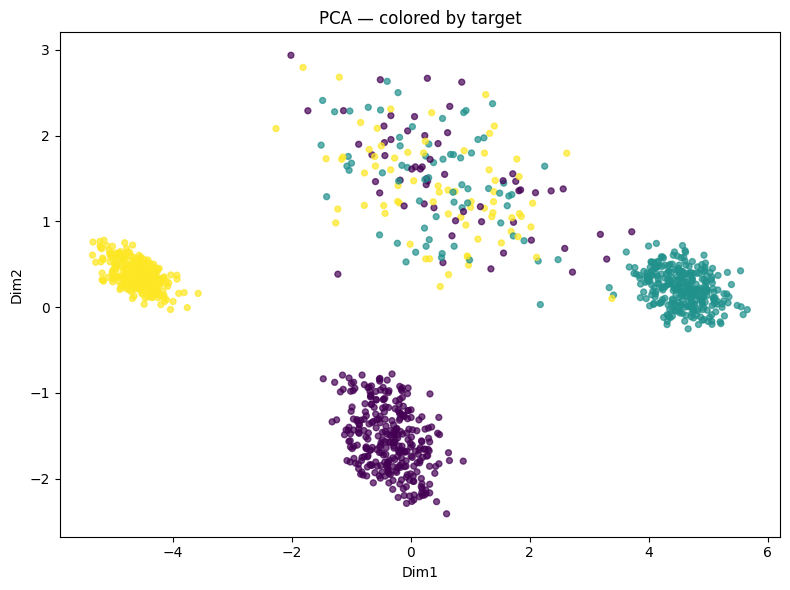

In [5]:
uns.reduce("pca")
uns.plot_embedding("pca", save=False)

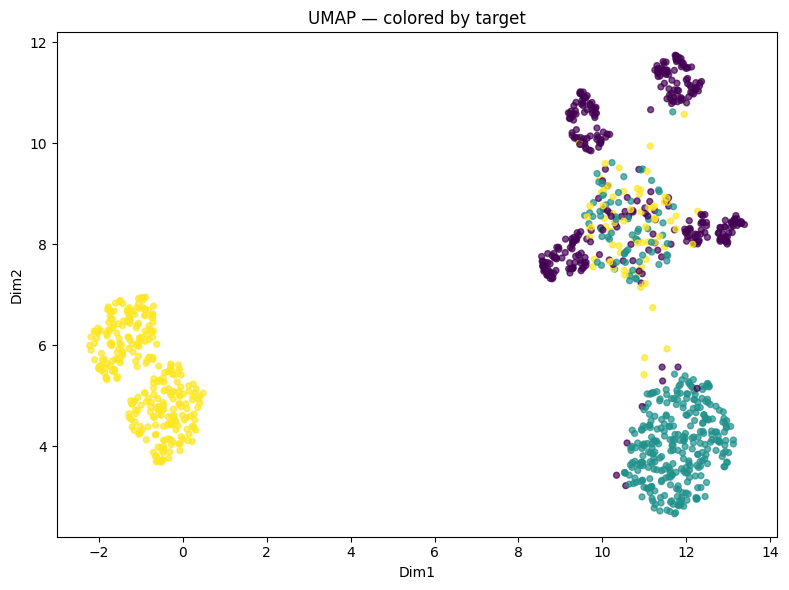

In [6]:
uns.reduce("umap")
uns.plot_embedding("umap", save=False)

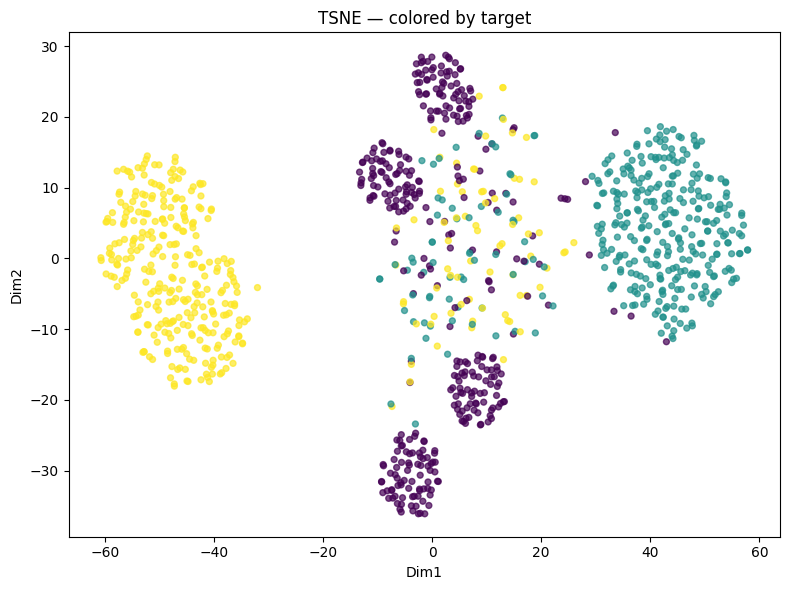

In [7]:
uns.reduce("tsne")
uns.plot_embedding("tsne", save=False)

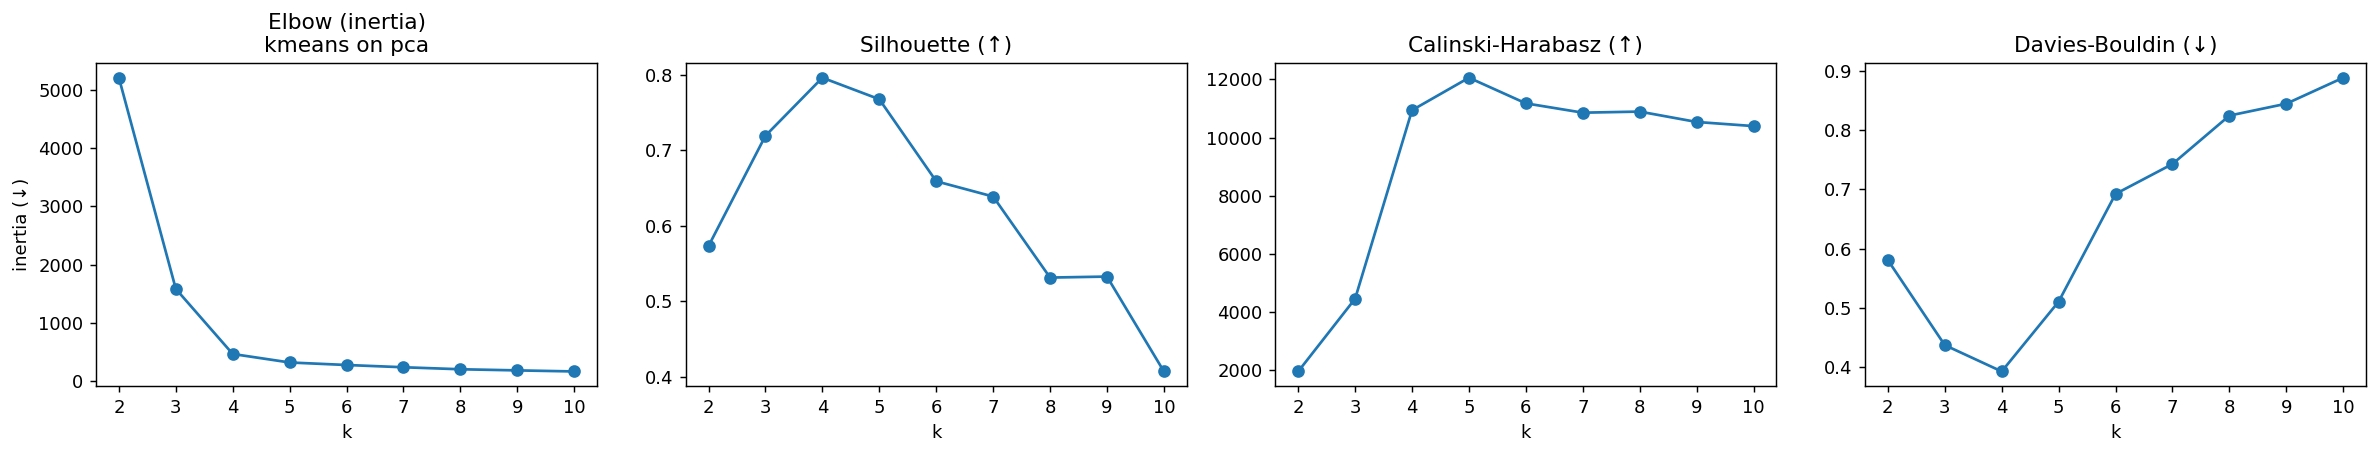

In [15]:
uns = UnsupervisedAnalysis(df, target="stress_level")
uns.prepare()

uns.reduce("pca", n_components=2)
dfk = uns.find_best_k(X="pca", k_range=range(2,11), method="kmeans")

In [16]:
res = uns.cluster_kmeans(X="pca", k=4)
labels = res["labels"]

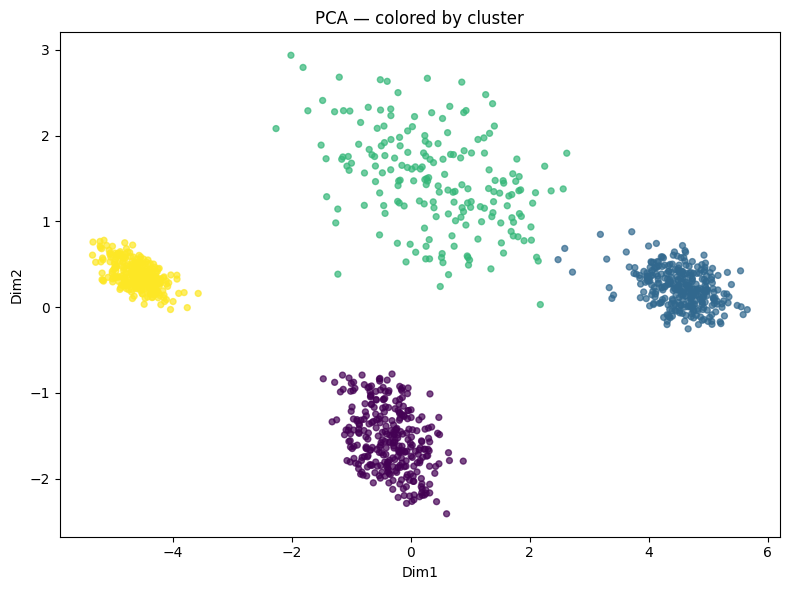

In [17]:
# 1) plot embedding (PCA) coloreado por clusters
uns.plot_embedding("pca", color_by="cluster", cluster_labels=labels, save=False)

In [18]:
# 2) radar/bar usando variables originales escaladas (X_embed_) agrupadas por cluster
centroids = uns.profile_clusters(labels)["numeric_means"]   # o función dedicada

C:\Users\vaguirre\AppData\Local\Temp\ipykernel_53072\2144417410.py:2255: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  t = dfp[self.target].astype("object").fillna("__NA__")


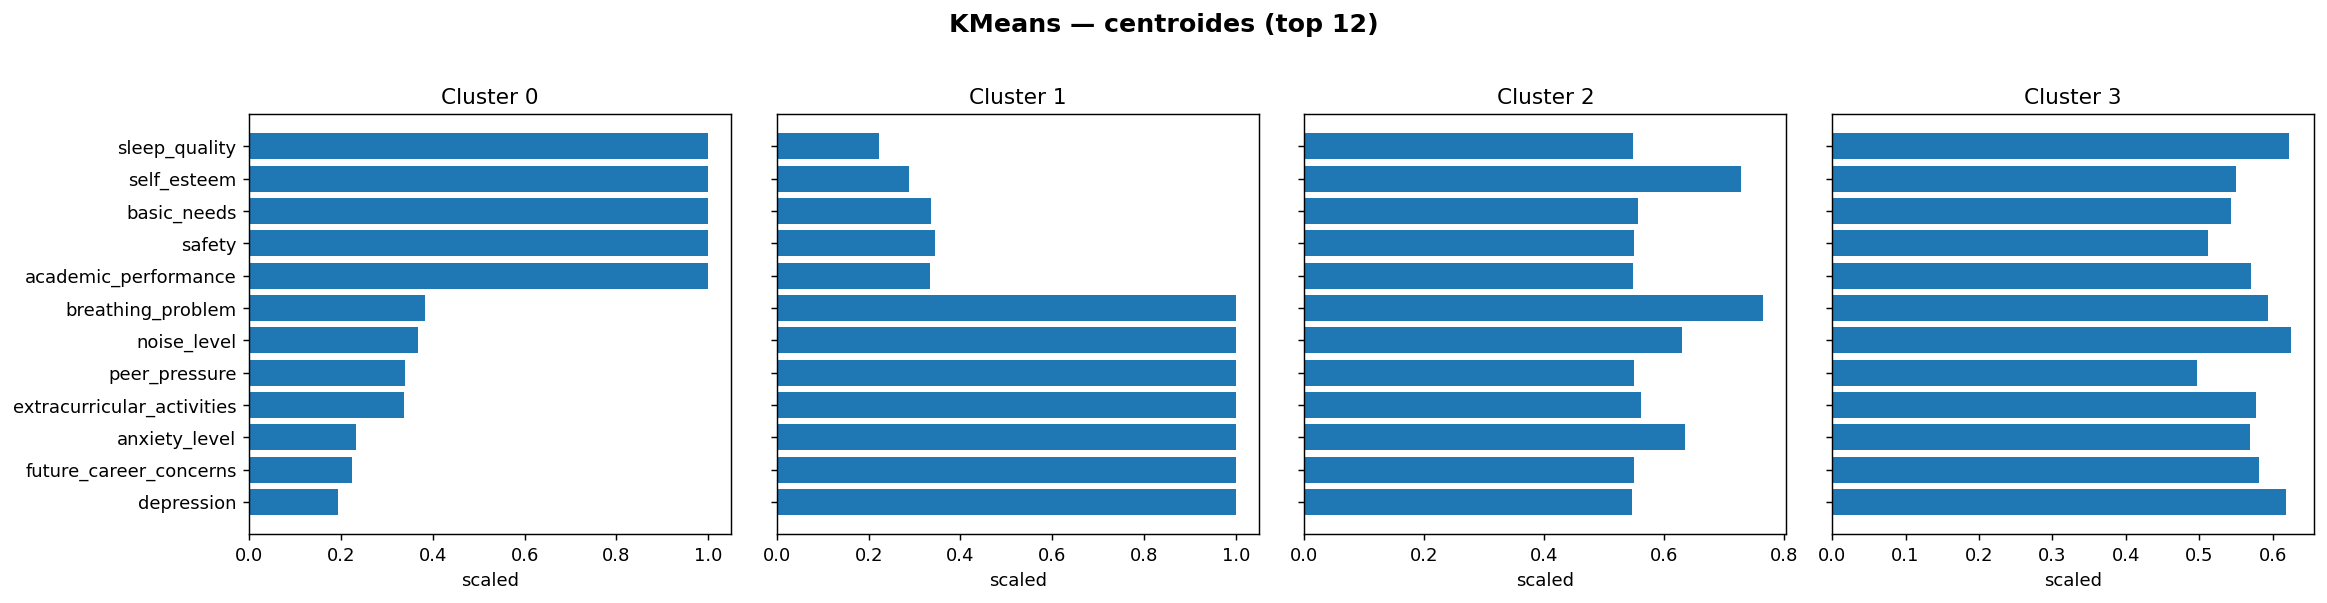

In [19]:
uns.plot_cluster_bars(centroids, normalize=True, top_n=12, title="KMeans — centroides (top 12)")

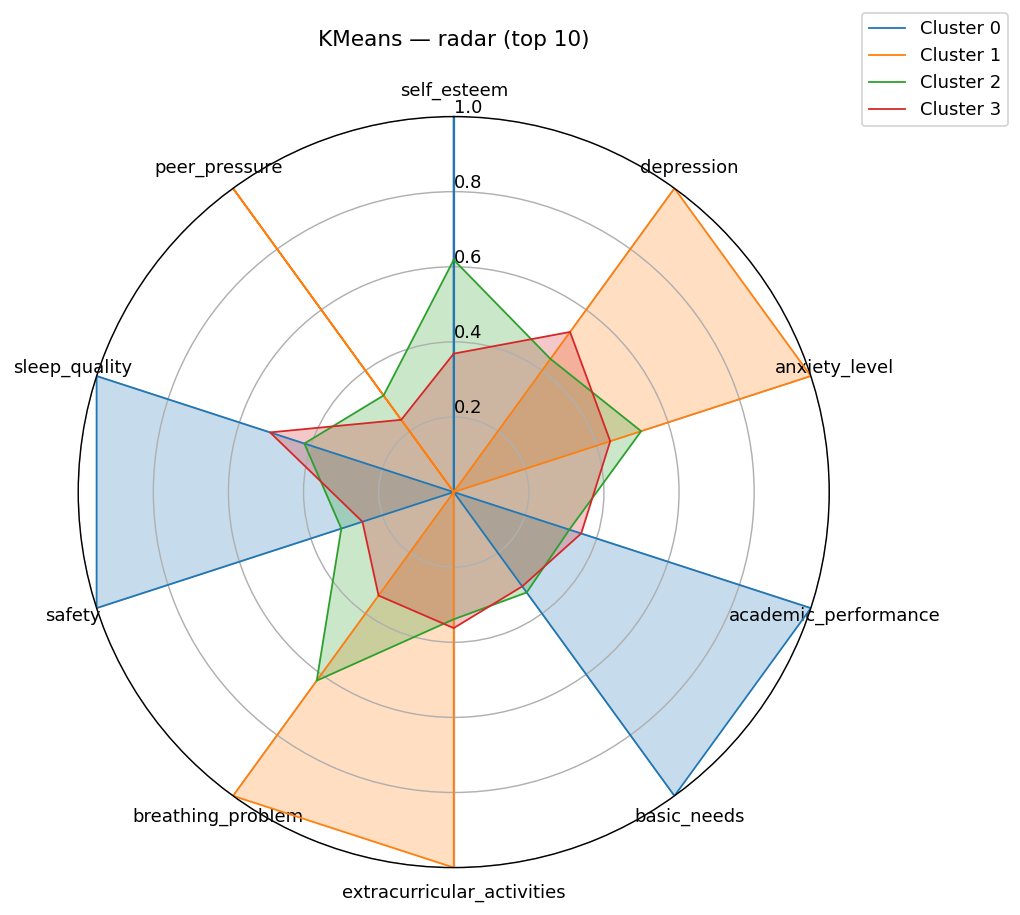

In [20]:
uns.plot_cluster_radar(centroids, top_n=10, normalize="minmax", title="KMeans — radar (top 10)")

# Pruebas de supervised analysis

In [8]:
df= pd.read_csv("students_dropout.csv")

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3630 entries, 0 to 3629
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   marital_status              3630 non-null   object 
 1   daytime_evening_attendance  3630 non-null   object 
 2   educational_special_needs   3630 non-null   object 
 3   debtor                      3630 non-null   object 
 4   tuition_fees_up_to_date     3630 non-null   object 
 5   gender                      3630 non-null   object 
 6   scholarship_holder          3630 non-null   object 
 7   age_at_enrollment           3630 non-null   int64  
 8   international               3630 non-null   object 
 9   unemployment_rate           3630 non-null   float64
 10  inflation_rate              3630 non-null   float64
 11  gdp                         3630 non-null   float64
 12  target                      3630 non-null   object 
dtypes: float64(3), int64(1), object(9

In [10]:
df["target"].value_counts() 

target
Graduate    2209
Dropout     1421
Name: count, dtype: int64

In [11]:
eda = EDAQuick(df, target="target") 

In [12]:

results = eda.run_eda(show_predictive_power=True, use_power_all=True)


Columnas convertidas a category: ['marital_status', 'daytime_evening_attendance', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international', 'target']
========== DATASET INFO ==========
rows: 3630
cols: 13
memory_mb: 0.14
duplicates_rows: 1952
target: target
n_numeric: 4
n_categorical: 9
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
age_at_enrollment,int64,0,0.0,46,1.27
unemployment_rate,float64,0,0.0,10,0.28
gdp,float64,0,0.0,10,0.28
inflation_rate,float64,0,0.0,9,0.25
marital_status,category,0,0.0,6,0.17
daytime_evening_attendance,category,0,0.0,2,0.06
educational_special_needs,category,0,0.0,2,0.06
debtor,category,0,0.0,2,0.06
tuition_fees_up_to_date,category,0,0.0,2,0.06
gender,category,0,0.0,2,0.06



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
age_at_enrollment,3630.0,23.461157,7.827994,17.00,19.0,20.00,25.00,70.00
unemployment_rate,3630.0,11.630358,2.667652,7.60,9.4,11.10,13.90,16.20
inflation_rate,3630.0,1.231598,1.384911,-0.80,0.3,1.40,2.60,3.70
gdp,3630.0,-0.009256,2.259986,-4.06,-1.7,0.32,1.79,3.51



========== TARGET DISTRIBUTION ==========


========== IMBALANCE REPORT ==========
Majority class : Graduate
Minority class : Dropout
Imbalance ratio: 1.55 : 1
Severity       : Mild imbalance
Recommendations:
 - Prefer F1-macro / balanced accuracy over plain accuracy.
 - Use stratified split / stratified CV.

========== CORRELATION ==========



========== OUTLIERS (boxplot) ==========



========== PREDICTIVE POWER ==========


In [15]:

sup = SupervisedClassification(df, target="target")

# 1) Prepare (split + preprocess safe + y encoding)
sup.prepare(
    test_size=0.20,
    valid_size=0.15,      # para threshold tuning
    stratify=True,
    scoring="f1_macro",
    cv_splits=5,
    model_encoding="auto",
    scale_num="standard",
    auto_cardinality_threshold=15
)

# 2) Register models (incluye MLP si lo agregaste en add_default_models)
sup.add_default_models()

# 3) HPO (rápido)
sup.tune("KNN", method="random", n_iter=25)
sup.tune("SVM", method="random", n_iter=25)
sup.tune("DecisionTree", method="random", n_iter=30)
sup.tune("GBC", method="random", n_iter=25)

# XGB (si existe)
if "XGB" in sup.model_specs_:
    sup.tune("XGB", method="random", n_iter=25)

# QDA/LDA (grid pequeñito)
sup.tune("QDA", method="grid")
sup.tune("LDA", method="grid")
# NaiveBayes sin HPO: compite igual

# 3.5) ✅ MLP (Keras) con KerasTuner (si está disponible)
# (en tu clase, _HAS_TF y _HAS_KT deben existir como flags globales)
if "MLP" in sup.model_specs_:
    try:
        sup.tune(
        "MLP",
        method="keras_tuner",
        param_space={
            "tuner_dir": "kt_dir",  # ahora esto se va al HOME automáticamente
            "project_name": "students_dropout_mlp",
            "max_trials": 25,
            "epochs": 40,
            "batch_size": 64,
            "patience": 6
        },
        verbose=0
        )
    except Exception as e:
        print(f"⚠️ MLP (keras_tuner) skipped: {e}")

# 4) Competition (incluye MLP si se tuneó)
lb = sup.compete(metric="f1_macro")
sup.pretty_table(lb, title="🏁 Leaderboard (CV)")

# 5) Fit best (train+valid)
sup.fit(model="best", refit_on="train_valid")

# 6) Test metrics
test_report = sup.evaluate_test(use_threshold=False)
sup.pretty_table(test_report, title="📌 Test metrics (default)")

# 7) Threshold tuning (binaria)
thr_df = sup.optimize_threshold(
    positive_label="Dropout",
    objective="precision",
    constraint={"recall_min": 0.60},
    use="valid"
)
sup.pretty_table(
    thr_df.sort_values("objective_value", ascending=False).head(10),
    title="🎯 Top thresholds (valid)"
)

# 8) Test metrics con threshold
test_thr = sup.evaluate_test(use_threshold=True)
sup.pretty_table(test_thr, title="📌 Test metrics (threshold)")

# 9) Save
sup.save("best_model.pkl", kind="pickle")


C:\Users\vaguirre\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning:


5 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\vaguirre\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\vaguirre\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\vaguirre\AppData\Roaming\Python\Pytho

🏁 Leaderboard (CV)


,model,metric,cv_mean,cv_std,n_splits,tuned
0,MLP,f1_macro,0.7490,nan,0,True
1,GBC,f1_macro,0.7367,0.0178,5,True
2,XGB,f1_macro,0.7361,0.0170,5,True
3,DecisionTree,f1_macro,0.7295,0.0216,5,True
4,AdaBoost,f1_macro,0.7255,0.0150,5,False
5,SVM,f1_macro,0.7202,0.0146,5,True
6,KNN,f1_macro,0.7168,0.0169,5,True
7,LDA,f1_macro,0.6993,0.0178,5,True
8,QDA,f1_macro,0.6951,0.0125,5,True
9,NaiveBayes,f1_macro,0.6838,0.0193,5,False


91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7683 - auc: 0.8255 - loss: 0.4807
📌 Test metrics (default)


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,log_loss,roc_auc,use_threshold,threshold,Dropout_precision,Dropout_recall,Dropout_f1,Dropout_support,Graduate_precision,Graduate_recall,Graduate_f1,Graduate_support
0,0.7410,0.6961,0.7486,0.6961,0.7029,0.7453,0.7410,0.7261,0.5136,0.8034,False,nan,0.7637,0.4894,0.5966,284,0.7335,0.9027,0.8093,442


...

,threshold,precision_pos,recall_pos,f1_pos,objective,objective_value,passes_constraint
75,0.8000,0.9815,0.3099,0.4711,precision,0.9815,False
76,0.8100,0.9804,0.2924,0.4505,precision,0.9804,False
77,0.8200,0.9804,0.2924,0.4505,precision,0.9804,False
78,0.8300,0.9800,0.2865,0.4434,precision,0.9800,False
81,0.8600,0.9792,0.2749,0.4292,precision,0.9792,False
80,0.8500,0.9792,0.2749,0.4292,precision,0.9792,False
79,0.8400,0.9792,0.2749,0.4292,precision,0.9792,False
82,0.8700,0.9792,0.2749,0.4292,precision,0.9792,False
83,0.8800,0.9792,0.2749,0.4292,precision,0.9792,False
84,0.8900,0.9787,0.2690,0.4220,precision,0.9787,False


📌 Test metrics (threshold)


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,log_loss,roc_auc,use_threshold,threshold,Dropout_precision,Dropout_recall,Dropout_f1,Dropout_support,Graduate_precision,Graduate_recall,Graduate_f1,Graduate_support
0,0.7369,0.7002,0.7326,0.7002,0.7067,0.7348,0.7369,0.7272,nan,nan,True,0.4600,0.7225,0.5317,0.6126,284,0.7427,0.8688,0.8008,442


⚠️ Detected a Keras model. Switching save kind from 'pickle' to 'h5'.
✅ Saved Keras -> best_model.h5
   sidecar preprocess: best_model.h5.preprocess.pkl
   meta json: best_model.h5.meta.json
   best_model: MLP | best_cv: 0.749018266792055
   threshold: 0.46 | positive_label: Dropout


'best_model.h5'

In [16]:
print("Best model:", sup.best_model_name_)
print("Best CV score:", sup.leaderboard_.iloc[0].to_dict() if hasattr(sup, "leaderboard_") else "N/A")

# sanity: distribuciones
print("y_train:", sup.y_train_.value_counts())
print("y_valid:", sup.y_valid_.value_counts())
print("y_test :", sup.y_test_.value_counts())


Best model: MLP
Best CV score: {'model': 'MLP', 'metric': 'f1_macro', 'cv_mean': 0.749018266792055, 'cv_std': nan, 'n_splits': 0, 'tuned': True}
y_train: target
Graduate    1502
Dropout      966
Name: count, dtype: int64
y_valid: target
Graduate    265
Dropout     171
Name: count, dtype: int64
y_test : target
Graduate    442
Dropout     284
Name: count, dtype: int64


In [17]:
test_report = sup.evaluate_test()

In [18]:
test_report

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,log_loss,roc_auc,use_threshold,threshold,Dropout_precision,Dropout_recall,Dropout_f1,Dropout_support,Graduate_precision,Graduate_recall,Graduate_f1,Graduate_support
0,0.741047,0.696076,0.748596,0.696076,0.702949,0.745301,0.741047,0.726101,0.513563,0.803363,False,NaN,0.763736,0.489437,0.596567,284,0.733456,0.902715,0.809331,442


In [19]:
test_thr = sup.evaluate_test(use_threshold=True)

In [20]:
test_thr

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,log_loss,roc_auc,use_threshold,threshold,Dropout_precision,Dropout_recall,Dropout_f1,Dropout_support,Graduate_precision,Graduate_recall,Graduate_f1,Graduate_support
0,0.736915,0.700234,0.732617,0.700234,0.706705,0.734822,0.736915,0.727191,NaN,NaN,True,0.46,0.722488,0.53169,0.612576,284,0.742747,0.868778,0.800834,442


# Pruebas de Sup regression

In [225]:
df = pd.read_csv("concreto.csv")

In [226]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cemento                 1030 non-null   float64
 1   escoria                 1030 non-null   float64
 2   ceniza_volatil          1030 non-null   float64
 3   agua                    1030 non-null   float64
 4   super_plastificante     1030 non-null   float64
 5   agregado_grueso         1030 non-null   float64
 6   agregado_fino           1030 non-null   float64
 7   edad                    1030 non-null   int64  
 8   resistencia_compresion  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [227]:
sup = SupervisedRegression(df, target="resistencia_compresion")

sup.prepare(
    test_size=0.20,
    valid_size=0.15,
    scoring="rmse",
    cv_splits=3,
    model_encoding="auto",
    scale_num="standard",
    auto_cardinality_threshold=15
)

# (C) Registrar modelos
sup.add_default_models()

# (D) HPO (rápido)
sup.tune("Lasso", method="random", n_iter=25)
sup.tune("Ridge", method="random", n_iter=25)
sup.tune("SVR", method="random", n_iter=30)
sup.tune("RandomForest", method="random", n_iter=25)
sup.tune("GBR", method="random", n_iter=25)

# (E) MLP con KerasTuner
if "MLP" in getattr(sup, "model_specs_", {}):
    try:
        sup.tune(
            "MLP",
            method="keras_tuner",
            param_space={
                "tuner_dir": "kt_dir",
                "project_name": "concreto_mlp_regression",
                "max_trials": 10,
                "epochs": 40,
                "batch_size": 64,
                "patience": 6
            },
            verbose=0
        )
    except Exception as e:
        print(f"⚠️ MLP (keras_tuner) skipped: {e}")

# (F) Competencia (CV)
lb = sup.compete(metric="rmse")
sup.pretty_table(lb, title="🏁 Leaderboard (CV)")

# (G) Fit best (train+valid)
sup.fit(model="best", refit_on="train_valid")

# (H) Evaluación en test
test_report = sup.evaluate_test()
sup.pretty_table(test_report, title="📌 Test metrics")

# (I) Distribución de y
sup.pretty_table(
    sup.y_distribution_summary(),
    title="📊 Distribución de y"
)

# (J) Guardar modelo
artifact = sup.save("best_reg_model.pkl", kind="pickle")
print("✅ Saved artifact:", artifact)

⚠️ MLP (keras_tuner) skipped: name 'layers' is not defined
🏁 Leaderboard (CV)


,model,metric,cv_mean,cv_std,n_splits,tuned,note
0,GBR,rmse,5.0707,0.1698,3,True,nan
1,RandomForest,rmse,6.3097,0.4990,3,True,nan
2,SVR,rmse,6.9158,0.5744,3,True,nan
3,DecisionTree,rmse,8.0121,0.7924,3,False,nan
4,Linear,rmse,10.7017,0.3638,3,False,nan
5,Ridge,rmse,10.7315,0.3367,3,True,nan
6,Lasso,rmse,10.7870,0.0671,3,True,nan
7,MLP,rmse,nan,nan,3,False,MLP requires tune(method='keras_tuner')


📌 Test metrics


,model,rmse,mae,r2,n_test
0,GBR,4.5283,2.8240,0.9224,206


📊 Distribución de y


,Variable,Min,Q1,Q3,Max
0,resistencia_compresion,2.3300,23.7100,46.1350,82.6000


✅ Saved -> best_reg_model.pkl
   best_model: GBR
   best_cv: 5.070665469406365
✅ Saved artifact: best_reg_model.pkl


# Probando timeseries

In [206]:
ts = TimeSeriesForecaster(df, date_col="fecha", target_col="valor", freq="D")

In [207]:
# ============================
# (LIGHT) 0) Datos + Forecaster
# ============================
df = pd.read_csv("consumo_agua.csv", sep=";")

# Serie (agrega si hay duplicados por fecha con sum)
ts.to_series(agg="sum")

# Missing report (antes de reindex)
missing_rep = ts.missing_report()


# Agregar fechas faltantes + imputar suavizado
ts.add_missing_dates()
ts.impute_smoothed(
    smooth="rolling_mean",
    window=5,
    center=True,
    impute="time",
    limit=None
)



In [208]:
missing_rep

,freq,start,end,n_expected,n_present,n_missing,missing_dates
0,D,2019-03-02,2021-11-30,1005,1005,0,[]


In [209]:
# Split temporal + periodograma
ts.prepare(train_size=0.95)
periods = ts.periodogram_candidates(best=3)
print("Period candidates:", periods)

Period candidates: [477, 318, 7]


12:07:58 - cmdstanpy - INFO - Chain [1] start processing
12:07:58 - cmdstanpy - INFO - Chain [1] done processing
12:07:58 - cmdstanpy - INFO - Chain [1] start processing
12:07:59 - cmdstanpy - INFO - Chain [1] done processing
12:07:59 - cmdstanpy - INFO - Chain [1] start processing
12:07:59 - cmdstanpy - INFO - Chain [1] done processing
12:07:59 - cmdstanpy - INFO - Chain [1] start processing
12:08:00 - cmdstanpy - INFO - Chain [1] done processing
12:08:00 - cmdstanpy - INFO - Chain [1] start processing
12:08:00 - cmdstanpy - INFO - Chain [1] done processing
12:08:00 - cmdstanpy - INFO - Chain [1] start processing
12:08:00 - cmdstanpy - INFO - Chain [1] done processing
12:08:01 - cmdstanpy - INFO - Chain [1] start processing
12:08:01 - cmdstanpy - INFO - Chain [1] done processing
12:08:01 - cmdstanpy - INFO - Chain [1] start processing
12:08:01 - cmdstanpy - INFO - Chain [1] done processing
12:08:02 - cmdstanpy - INFO - Chain [1] start processing
12:08:02 - cmdstanpy - INFO - Chain [1]

Leaderboard (RMSE) — menor es mejor


,model,rmse,params_str
0,SARIMA,225.7610,"{""order"": [2, 1, 2], ""seasonal_order"": [1, 1, 1, 7]}"
1,PROPHET,284.3794,"{""add_country_holidays"": null, ""changepoint_prior_scale"": 0.1, ""daily_seasonality"": false, ""holidays_prior_scale"": 10.0, ""interval_width"": 0.8, ""seasonality_mode"": ""additive"", ""seasonality_prior_scale"": 1.0, ""weekly_seasonality"": ""auto"", ""yearly_seasonality"": ""auto""}"
2,CNN1D,340.2613,"{""batch_size"": 16, ""epochs"": 10, ""filters"": 32, ""kernel_size"": 3, ""l2"": 0.0, ""lookback"": 7}"
3,XGBTS,362.0118,"{""colsample_bytree"": 0.8, ""lags"": [1, 7, 14], ""learning_rate"": 0.1, ""max_depth"": 4, ""n_estimators"": 300, ""reg_alpha"": 0.0, ""reg_lambda"": 1.0, ""rolling_windows"": [3, 7], ""subsample"": 1.0, ""use_date_parts"": true}"
4,ETS,377.6518,"{""alpha"": null, ""beta"": null, ""gamma"": null, ""optimized"": true, ""seasonal"": null, ""seasonal_periods"": null, ""trend"": ""add""}"
5,LSTM,409.7348,"{""batch_size"": 16, ""epochs"": 10, ""lookback"": 7}"


Best model params


,model,order,seasonal_order
0,SARIMA,"(2, 1, 2)","(1, 1, 1, 7)"


...

Target distribution (TEST)


,min,q1,median,q3,max,iqr
0,3606.0136,3988.4176,4250.8160,4489.2520,4712.7632,500.8344


RMSE contextualizado (ALL)


,rmse,rmse_over_iqr,rmse_over_range
0,225.7610,0.2985,0.0667


2021-12-01    4453.656718
2021-12-02    4381.651948
2021-12-03    4680.816287
2021-12-04    4614.577837
2021-12-05    4227.261044
2021-12-06    4151.314896
2021-12-07    4145.134680
Freq: D, Name: predicted_mean, dtype: float64


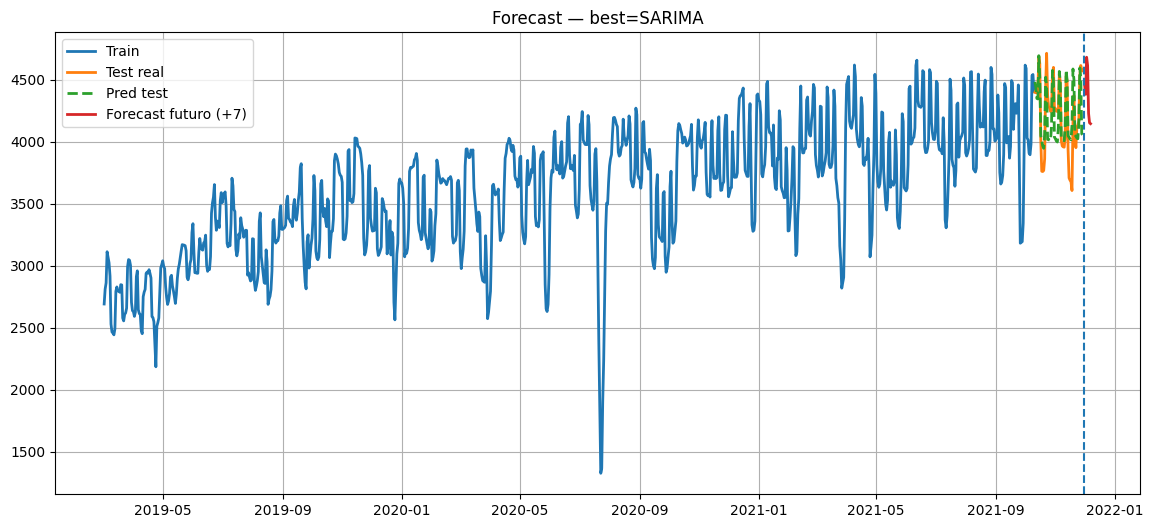

In [203]:

# ============================
# (LIGHT) Modelos + Tune
# ============================
ts.add_default_models(
    include_lstm=True,
    include_cnn=True,
    include_prophet=True,   # requiere `pip install prophet`
    include_xgb=True        # requiere `pip install xgboost`
)

# --- DL (forzado) ---
ts.tune("CNN1D", p_candidates=[7], dl_epochs=10)
ts.tune("LSTM",  p_candidates=[7], dl_epochs=10)

# --- SARIMA (light) ---
ts.tune(
    "SARIMA",
    S_candidates=[7],
    n_jobs=-1,
    search="grid",
    max_p=2, max_d=1, max_q=2,
    max_P=1, max_D=1, max_Q=1
)

# --- PROPHET (light) ---
ts.tune(
    "PROPHET",
    search="random",
    max_evals=25,
    random_state=None,
    changepoint_prior_scale_grid=[0.01, 0.05, 0.1],
    seasonality_prior_scale_grid=[1.0, 5.0, 10.0],
    seasonality_mode_grid=["additive", "multiplicative"],
    yearly_seasonality="auto",
    weekly_seasonality="auto",
    daily_seasonality=False
)

# --- XGBTS (light) ---
ts.tune(
    "XGBTS",
    search="random",
    max_evals=30,
    random_state=None,
    lag_sets=[
        [1,2,3,6,12],
        [1,2,7,14],
        [1,7,14]
    ],
    roll_sets=[
        [3,7,14],
        [7,14],
        [3,7]
    ],
    max_depth_grid=[3,4,5],
    learning_rate_grid=[0.03, 0.05, 0.1],
    n_estimators_grid=[300, 500],
    subsample_grid=[0.8, 0.9, 1.0],
    colsample_bytree_grid=[0.8, 0.9, 1.0]
)

# --- COMPETE ---
lb = ts.compete(metric="rmse", verbose=True)

# --- FIT FINAL + PRED ---
ts.fit(model="best", refit_on="train_test_full")

pred_7 = ts.predict(steps=7)
print(pred_7)

ts.plot_forecast(steps=7, show_test_pred=True)

# Probamos el run auto

In [210]:
resultados = ts.run_auto(
    # ---------- data ----------
    agg="sum",

    # ---------- fechas ----------
    check_missing=True,
    add_missing=True,
    impute_missing=True,
    impute_kwargs={
        "smooth": "rolling_mean",
        "window": 5,
        "center": True,
        "impute": "time"
    },

    # ---------- split ----------
    train_size=0.95,

    # ---------- periodograma ----------
    use_periodogram=True,
    best_periods=3,

    # ---------- candidatos (forzados) ----------
    p_candidates=[7],      # DL
    S_candidates=[7],      # SARIMA

    # ---------- modelos ----------
    include_lstm=True,
    include_cnn=True,
    include_prophet=True,
    include_xgb=True,

    # ---------- tuning ----------
    tune_models=True,
    dl_epochs=10,
    n_jobs=-1,
    tune_prophet=True,
    tune_xgb=True,
    prophet_max_evals=25,
    xgb_max_evals=30,

    # ---------- evaluación ----------
    metric="rmse",
    verbose=True,

    # ---------- fit final ----------
    refit_on="train_test_full",

    # ---------- forecast ----------
    forecast_steps=7
)

# outputs típicos
print(resultados["missing_report"])
print(resultados["leaderboard"])
print("Best:", resultados["best_model"], resultados["best_score"])
print(resultados["forecast"])

12:47:29 - cmdstanpy - INFO - Chain [1] start processing
12:47:29 - cmdstanpy - INFO - Chain [1] done processing
12:47:29 - cmdstanpy - INFO - Chain [1] start processing
12:47:29 - cmdstanpy - INFO - Chain [1] done processing
12:47:30 - cmdstanpy - INFO - Chain [1] start processing
12:47:30 - cmdstanpy - INFO - Chain [1] done processing
12:47:30 - cmdstanpy - INFO - Chain [1] start processing
12:47:30 - cmdstanpy - INFO - Chain [1] done processing
12:47:31 - cmdstanpy - INFO - Chain [1] start processing
12:47:31 - cmdstanpy - INFO - Chain [1] done processing
12:47:31 - cmdstanpy - INFO - Chain [1] start processing
12:47:31 - cmdstanpy - INFO - Chain [1] done processing
12:47:31 - cmdstanpy - INFO - Chain [1] start processing
12:47:32 - cmdstanpy - INFO - Chain [1] done processing
12:47:32 - cmdstanpy - INFO - Chain [1] start processing
12:47:32 - cmdstanpy - INFO - Chain [1] done processing
12:47:32 - cmdstanpy - INFO - Chain [1] start processing
12:47:32 - cmdstanpy - INFO - Chain [1]

Leaderboard (RMSE) — menor es mejor


,model,rmse,params_str
0,SARIMA,225.7610,"{""order"": [2, 1, 2], ""seasonal_order"": [1, 1, 1, 7]}"
1,PROPHET,284.3794,"{""add_country_holidays"": null, ""changepoint_prior_scale"": 0.1, ""daily_seasonality"": false, ""holidays_prior_scale"": 10.0, ""interval_width"": 0.8, ""seasonality_mode"": ""additive"", ""seasonality_prior_scale"": 1.0, ""weekly_seasonality"": ""auto"", ""yearly_seasonality"": ""auto""}"
2,ETS,377.6518,"{""alpha"": null, ""beta"": null, ""gamma"": null, ""optimized"": true, ""seasonal"": null, ""seasonal_periods"": null, ""trend"": ""add""}"
3,LSTM,432.3836,"{""batch_size"": 16, ""epochs"": 10, ""lookback"": 7}"
4,XGBTS,449.2070,"{""colsample_bytree"": 0.8, ""lags"": [1, 2, 3, 12], ""learning_rate"": 0.02, ""max_depth"": 5, ""n_estimators"": 300, ""reg_alpha"": 0.0, ""reg_lambda"": 1.0, ""rolling_windows"": [6, 12], ""subsample"": 0.8, ""use_date_parts"": true}"
5,CNN1D,462.2013,"{""batch_size"": 16, ""epochs"": 10, ""filters"": 32, ""kernel_size"": 3, ""l2"": 0.0, ""lookback"": 7}"


Best model params


,model,order,seasonal_order
0,SARIMA,"(2, 1, 2)","(1, 1, 1, 7)"


...

Target distribution (TEST)


,min,q1,median,q3,max,iqr
0,3606.0136,3988.4176,4250.8160,4489.2520,4712.7632,500.8344


RMSE contextualizado (ALL)


,rmse,rmse_over_iqr,rmse_over_range
0,225.7610,0.2985,0.0667


  freq      start        end  n_expected  n_present  n_missing missing_dates
0    D 2019-03-02 2021-11-30        1005       1005          0            []
     model        rmse  \
0   SARIMA  225.761040   
1  PROPHET  284.379442   
2      ETS  377.651777   
3     LSTM  432.383609   
4    XGBTS  449.207043   
5    CNN1D  462.201348   

                                                        params  \
0         {'order': (2, 1, 2), 'seasonal_order': (1, 1, 1, 7)}   
1  {'seasonality_mode': 'additive', 'yearly_seasonality': '...   
2  {'trend': 'add', 'seasonal': None, 'seasonal_periods': N...   
3              {'lookback': 7, 'epochs': 10, 'batch_size': 16}   
4  {'lags': [1, 2, 3, 12], 'rolling_windows': [6, 12], 'use...   
5  {'lookback': 7, 'epochs': 10, 'batch_size': 16, 'filters...   

                                                    params_str  
0         {"order": [2, 1, 2], "seasonal_order": [1, 1, 1, 7]}  
1  {"add_country_holidays": null, "changepoint_prior_scale"...  
2  {"

In [224]:
DFCore.dependency_doctor()

✅ Dependency doctor: todo OK (para los módulos chequeados).
Dependency doctor (OK)


,capability,status,missing
0,core,OK,
1,deeplearning_kt,OK,
2,deeplearning_tf,OK,
3,hpo_bayes_skopt,OK,
4,hpo_halving,OK,
5,sklearn_core,OK,
6,timeseries_prophet,OK,
7,timeseries_statsmodels,OK,
8,viz,OK,
9,xgboost,OK,
